# Estudo de Caso 2: Tempo de Tramitação no 4º JEC de Natal/RN — conciliação obrigatória presencial, remota e rito atual

**Autor:** rafaelcc · **Disciplina:** Ciência de Dados e Estatística aplicadas ao Direito e Políticas Públicas (CDEaDPP) — 2026.2 · **Professor:** Cleuler Barbosa das Neves
**Notebook:** `rafaelcc_ed2.ipynb` (gerado por `src/build_rafaelcc_ed2.py`; não editar à mão)

## Introdução

**O experimento.** O juiz titular do 4º Juizado Especial Cível (JEC) de Natal/RN, Paulo Giovani Militão de Alencar, conduziu, como pesquisa de mestrado profissional (PPGDP/UFG, orientação do Prof. Cleuler), um experimento na própria unidade. Cada ação de conhecimento distribuída ao 4º JEC entre **01/01/2026 e 03/08/2026** foi submetida a um sorteio que definia o rito procedimental:

| Grupo (código) | Rótulo neste notebook | Rótulo na planilha | Descrição |
|---|---|---|---|
| `Controle` | Controle (rito atual, AC opcional) | Rito Atual Ac Opcional | Fluxo vigente em Natal desde a pandemia: citação para contestar, sem audiência de conciliação (AC) inaugural, salvo pedido conjunto das partes |
| `Presencial` | AC presencial obrigatória | Ac Obrigatória Presencial | AC inaugural obrigatória (art. 21 da Lei 9.099/1995), no fórum, conduzida por servidora do CEJUSC |
| `Remota` | AC remota obrigatória | Ac Remota | AC inaugural obrigatória por videoconferência (Teams), conduzida por servidora do gabinete |

Nas audiências, a técnica de conciliação também era sorteada (seis técnicas). A planilha de acompanhamento, alimentada diariamente pela unidade, registra **943 processos** sorteados (944 linhas) com o rito, a ocorrência de acordo na audiência ou fora dela, a técnica, o tipo e a data da sentença. A versão analisada foi **atualizada em 07/10/2026**: os processos ainda sem sentença nessa data estão em tramitação e têm, portanto, tempo **censurado à direita**.

**Variável-alvo.** O **tempo de tramitação**, em dias corridos, da distribuição ao 4º JEC até a sentença (de mérito, sem mérito ou homologatória de acordo).

**Perguntas de pesquisa.**

1. **Curadoria.** Os dados brutos são confiáveis? Que anomalias existem e como tratá-las sem inventar informação?
2. **Efeito sobre o tempo.** A audiência de conciliação obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?
3. **Efeito sobre o acordo.** A audiência obrigatória aumenta a proporção de acordos? A modalidade (presencial × remota) importa?
4. **Desenho.** O sorteio produziu grupos comparáveis? Que limitações (censura, redistribuições, híbridas, unidade única) afetam a validade interna e a externa?
5. **Questões do professor.** Respostas às questões 2.2 a 2.12 do roteiro.

**Pipeline de ciência de dados.**

| Parte | Seções | Conteúdo |
|---|---|---|
| I. Curadoria | 1 | Ambiente; formação do dataset bruto; fórmulas e data de corte; tipos e tipologia das variáveis; ausências, duplicidades, número CNJ, grafias, recodificações e desvios de protocolo; dataset *tidy* com tempo e evento; verificações; registro de tratamentos; dicionário e exportação |
| II. Exploratória | 2 | Análise univariada e bivariada com o tempo como alvo; normalidade e ajuste de distribuições; modelo binomial para as proporções |
| III. Testes de hipóteses | 3 | Testes adequados a cada pergunta (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney, Dunn, sequências), com tamanho de efeito e correção de multiplicidade |
| IV. Análise de sobrevivência | 4 | Kaplan-Meier, log-rank, Cox, modelos AFT, riscos competitivos (Aalen-Johansen, Fine-Gray) e tempo médio restrito (RMST) |
| V. Multivariada e regressão | 5 | Modelos com covariáveis (mês de distribuição, origem do processo), regressão logística para o acordo e diagnósticos |
| VI. Questões do professor | 6 | Respostas fundamentadas às questões 2.2 a 2.12 |
| VII. Síntese | 7 | Conclusões, limitações e sugestões para a replicação |
| Apêndice | A | Painel-resumo do estudo; catálogo de todas as figuras e tabelas (numeradas por parte: Figura II.3, Tabela III.5) e exportação para `fig/`, `tab/` e `tab/ed2_tabelas.xlsx` |

### O notebook do professor

O notebook inicial `estcaso_4jec_natal_rn.ipynb` foi revisado célula a célula (30 problemas catalogados, E1 a E30). Os principais, corrigidos aqui:

- **E1** — `from lifelines import KaplanMeierFitter, logrank_test` falha (a função fica em `lifelines.statistics`), e o `except ImportError` desliga silenciosamente o Kaplan-Meier: a única análise adequada a dados censurados nunca é executada;
- **E7/E14** — os tempos dos processos em tramitação (censurados) são tratados como tempos completos, e a "janela de 218 dias" não corresponde aos dados; a data de referência real é 07/10/2026, fixada aqui;
- **E3** — duplicidades detectadas e não tratadas (há processos redistribuídos que voltaram e foram **sorteados de novo**, inclusive para outro grupo);
- **E4/E5** — o marcador `**` ("não se aplica") e as ausências estruturais são tratados como categorias ou como "Não";
- **E10** — a "Decisão" (redistribuição por prevenção) é contada como sentença;
- **E6/E16** — quatro colunas de duração são a mesma variável, e a matriz de correlação entre elas é tautológica (r = 1);
- **E17–E27** — Kruskal-Wallis, OLS e ajuste de distribuições aplicados a tempos censurados; testes tautológicos (Encerrado × Ativo) e sem tamanho de efeito nem correção de multiplicidade.

Em cada seção, quando a abordagem difere da do notebook do professor, o erro corrigido é indicado pelo código (E*n*).

---

# PARTE I — CURADORIA DOS DADOS

A Parte I transforma a planilha da pesquisadora num dataset analítico (*tidy*: uma linha por processo, uma coluna por variável, um tipo adequado por coluna). O roteiro segue a auditoria completa dos dados brutos, e cada decisão é registrada num **log de tratamentos** exportado ao final. Duas regras valem em toda a Parte I:

1. **O arquivo-fonte nunca é alterado**, e `dados_brutos` preserva exatamente a leitura; todas as transformações ocorrem numa cópia de trabalho.
2. **Nenhuma data ou duração é imputada.** O que falta continua faltando, e os processos sem sentença são tratados como **censurados** na data de corte.

## 1.1 Preparação do ambiente

A primeira célula concentra as importações, os caminhos, as constantes do estudo e a identidade visual que as demais partes do notebook reutilizam:

- **`DATA_CORTE = 07/10/2026`**: data de referência da censura (seção 1.4);
- **`CORES_GRUPO`**: uma cor fixa por grupo, da paleta de Okabe-Ito (segura para daltonismo). A mesma cor representa o mesmo grupo em todos os gráficos; **`CORES_DESFECHO`** usa matizes que não repetem os dos grupos (a camada de visualização completa, com estilo, rótulos e funções de figura e tabela, está na seção 1.2);
- **avisos**: só são silenciados os avisos conhecidos e inofensivos (extensões do Excel que o `openpyxl` não lê e avisos de depreciação). O notebook do professor usava `warnings.filterwarnings('ignore')`, que esconde qualquer problema, inclusive o que desligou o Kaplan-Meier (E1).

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import importlib
import platform
import re
import sys
import unicodedata
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, pairwise_logrank_test
import sklearn
import scikit_posthocs as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from IPython.display import display, Markdown

# Avisos conhecidos e inofensivos (não se usa filterwarnings('ignore') global)
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

# ---------------------------------------------------------------- caminhos
ARQUIVO_BRUTO = 'ControleDosProcessos_Mestrado_Atualizacao_07.10.2026.xlsx'
_candidatos = [Path.cwd(), Path.cwd() / 'EstudodeCaso2', Path.cwd().parent, Path.cwd().parent / 'EstudodeCaso2']
RAIZ = next((p.resolve() for p in _candidatos if (p / ARQUIVO_BRUTO).exists()), None)
if RAIZ is None:
    raise FileNotFoundError(f'{ARQUIVO_BRUTO} não encontrado. Inicie o kernel na raiz do projeto ou em EstudodeCaso2.')
BRUTO = RAIZ / ARQUIVO_BRUTO
PROC = RAIZ / 'dat' / 'processado'
FIG = RAIZ / 'fig'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- constantes do estudo
DATA_INICIO = pd.Timestamp('2026-01-01')        # primeira distribuição
FIM_RECRUTAMENTO = pd.Timestamp('2026-08-03')   # último sorteio
DATA_CORTE = pd.Timestamp('2026-10-07')         # atualização da planilha = censura administrativa
SEMENTE = 2026
RNG = np.random.default_rng(SEMENTE)

ORDEM_GRUPO = ['Controle', 'Presencial', 'Remota']   # referência = Controle
ROTULO_GRUPO = {'Controle': 'Controle (rito atual, AC opcional)',
                'Presencial': 'AC presencial obrigatória',
                'Remota': 'AC remota obrigatória'}
CORES_GRUPO = {'Controle': '#0072B2', 'Presencial': '#E69F00', 'Remota': '#009E73'}   # Okabe-Ito
ORDEM_DESFECHO = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Ativo']
# Desfechos são outra entidade: nenhuma cor de desfecho repete a cor de um grupo (validação na seção 1.2)
CORES_DESFECHO = {'Homologação': '#CC79A7', 'Mérito': '#4B3F8F', 'Sem mérito': '#B8461B',
                  'Redistribuição': '#7F7F7F', 'Ativo': '#C8C8C8'}
TINTA, TINTA_2, GRADE = '#1a1a1a', '#555555', '#e5e5e5'


# ---------------------------------------------------------------- números em pt-BR
def fmt_br(valor, casas=1):
    """Formata número no padrão brasileiro: 1.234,5."""
    try:
        if valor is None or pd.isna(valor):
            return '–'
    except (TypeError, ValueError):
        pass
    return f'{float(valor):,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def pct_br(proporcao, casas=1):
    """Proporção (0–1) como percentual pt-BR: 12,3%."""
    return fmt_br(100 * proporcao, casas) + '%'


def p_br(p):
    """Valor-p em pt-BR, com limite inferior."""
    return '< 0,001' if p < 0.001 else fmt_br(p, 3)


print(f'Python {platform.python_version()} | pasta do estudo: {RAIZ}')
print(f'Data de corte (censura): {DATA_CORTE:%d/%m/%Y}')

Python 3.12.8 | pasta do estudo: C:\Users\MPGO\AulaCleuler\EstudodeCaso2
Data de corte (censura): 07/10/2026


### Versões das bibliotecas e o erro de importação do notebook do professor

A tabela registra as versões usadas (reprodutibilidade; o ambiente é o `uv.lock` do projeto). Em seguida, a célula reproduz o import do notebook do professor. A função `logrank_test` **não** existe no espaço de nomes principal do `lifelines`; ela fica em `lifelines.statistics`. No notebook original, o `ImportError` era capturado por um `except` que fazia `TEM_LIFELINES = False`, e todo o Kaplan-Meier era pulado **mesmo com a biblioteca instalada** (E1).

In [2]:
BIBLIOTECAS = ['pandas', 'numpy', 'scipy', 'statsmodels', 'lifelines', 'sklearn', 'scikit_posthocs',
               'matplotlib', 'seaborn', 'openpyxl', 'nbformat']
versoes = pd.DataFrame(
    [(nome, getattr(importlib.import_module(nome), '__version__', '?')) for nome in BIBLIOTECAS],
    columns=['Biblioteca', 'Versão'])
display(versoes.set_index('Biblioteca').T)

try:
    from lifelines import logrank_test as _teste  # import do notebook do professor
    resultado_import = 'funcionou'
except ImportError as erro:
    resultado_import = f'ImportError: {erro}'
print('from lifelines import logrank_test            ->', resultado_import)
print('from lifelines.statistics import logrank_test ->', logrank_test.__module__, '(correto)')

Biblioteca,pandas,numpy,scipy,statsmodels,lifelines,sklearn,scikit_posthocs,matplotlib,seaborn,openpyxl,nbformat
Versão,3.0.5,2.5.2,1.18.0,0.15.0,0.30.0,1.9.0,0.17.0,3.11.1,0.13.2,3.1.5,5.11.1


from lifelines import logrank_test            -> ImportError: cannot import name 'logrank_test' from 'lifelines' (C:\Users\MPGO\AulaCleuler\.venv\Lib\site-packages\lifelines\__init__.py)
from lifelines.statistics import logrank_test -> lifelines.statistics (correto)


---

## 1.2 Camada de visualização

Todas as figuras e tabelas do notebook passam por uma **camada comum**, definida aqui uma única vez. O objetivo é que qualquer gráfico possa ser lido sem consultar o código: cada figura e cada tabela tem **número** (por parte: Figura II.3, Tabela III.5), **título** que enuncia o achado ou a pergunta, **eixos com unidade**, **n** de cada grupo, a **fonte** e, quando há teste, o **resultado do teste no próprio gráfico** (estatística, valor-p e tamanho de efeito). Tudo é numerado e registrado num catálogo, reproduzido no Apêndice, e exportado: figuras em `fig/<id>.png` (e `.svg`), tabelas em `tab/<id>.csv` (separador `;`, vírgula decimal, UTF-8 com BOM, que o Excel abre corretamente).

| Elemento | Regra adotada |
|---|---|
| Cor | identifica uma **entidade**, e só uma: os três grupos têm as cores fixas de Okabe-Ito; os desfechos usam outros matizes (nenhum repete a cor de um grupo); "ativo/censurado" é cinza claro. Mapas de calor usam uma escala **sequencial** de um só matiz (magnitude, como o V de Cramér) ou **divergente** com dois matizes opostos e meio cinza (sinal, como os resíduos ajustados) |
| Daltonismo | as paletas são verificadas por simulação (Machado, Oliveira e Fernandes, 2009, protanopia e deuteranopia de severidade 1,0) e distância perceptual ΔE no espaço OKLab (×100): alvo ≥ 8 entre cores vizinhas, piso de 15 sem simulação. Além da cor, há sempre um segundo canal: legenda, rótulo direto ou posição |
| Forma | barras **verticais** e *boxplots*; nunca dois eixos verticais com escalas diferentes; nunca histograma em escala logarítmica; Kaplan-Meier sempre como S(t) descendente, com IC e número em risco |
| Rótulos | nomes legíveis (não os nomes das colunas), rótulos longos quebrados em linhas, ordem fixa dos grupos (Controle, Presencial, Remota) e dos desfechos; legenda sempre que há duas ou mais séries, e rótulos diretos seletivos (não um número em cada ponto) |
| Números | padrão brasileiro nos eixos, rótulos e tabelas: vírgula decimal, ponto de milhar, valor-p como "< 0,001" |

As funções disponíveis para as demais partes:

- **`figura(fig, id, titulo, secao=..., fonte=..., nota=...)`**: numera, põe título e fonte, converte os eixos para vírgula decimal, salva PNG e SVG e registra no catálogo;
- **`tabela(df, id, titulo, secao=..., nota=..., formatos=..., destaque=...)`**: exibe a tabela formatada (legenda numerada, pt-BR, valor-p formatado, índice oculto quando não tem significado, linhas significativas destacadas), exporta CSV e registra no catálogo;
- **auxiliares de gráfico**: `barras_verticais`, `barras_agrupadas`, `barras_empilhadas`, `boxplot_grupos`, `plot_km`, `anotar_n`, `anotar_teste`, `texto_teste`, `quebra`, `eixo_pct`, `eixo_meses`, `legenda_abaixo`;
- **rótulos**: `ROTULOS` (variável → rótulo com unidade), `ROTULO_DESFECHO`, `rotulo_grupo(g, com_n=True)` → "Controle (n = 313)".

In [3]:
import textwrap
from matplotlib.offsetbox import AnchoredText
from matplotlib.ticker import ScalarFormatter, FuncFormatter
from IPython.display import HTML

TAB = RAIZ / 'tab'
TAB.mkdir(parents=True, exist_ok=True)
FONTE_PADRAO = ('Fonte: elaboração própria a partir da planilha de controle dos processos do 4º JEC de Natal/RN '
                '(atualização de 07/10/2026).')

# ---------------------------------------------------------------- rótulos legíveis (com unidade)
ROTULOS = {
    'tempo': 'Tempo até a sentença ou a censura (dias)',
    'tempo_sentenca': 'Tempo até a sentença (dias)',
    'tempo_pos': 'Tempo até a sentença ou a censura (dias; zeros = 0,5)',
    'followup': 'Seguimento máximo possível (dias)',
    'dias': 'Dias desde a distribuição',
    'S': 'Proporção ainda sem sentença, S(t)',
    'F': 'Proporção acumulada de sentenças',
    'CIF': 'Incidência acumulada',
    'grupo': 'Grupo (rito sorteado)',
    'tipo_desfecho': 'Tipo de desfecho',
    'mes_distribuicao': 'Mês de distribuição (2026)',
    'dt_distribuicao': 'Data de distribuição (2026)',
    'dt_sentenca': 'Data da sentença (2026)',
    'ordem_chegada': 'Ordem de chegada (1 a 938)',
    'dia_estudo': 'Dia do estudo (desde 01/01/2026)',
    'n': 'Número de processos',
    'pct': 'Processos (%)',
    'acordo': 'Acordo (na AC ou fora dela)',
    'acordo_ac': 'Acordo na audiência de conciliação',
    'acordo_fora': 'Acordo fora da audiência',
    'ac_realizada': 'Audiência de conciliação realizada',
    'tecnica': 'Técnica de conciliação',
    'hibrida': 'Audiência híbrida',
    'origem_externa': 'Processo de outro órgão ou ano anterior',
}
ROTULO_DESFECHO = {'Homologação': 'Homologação de acordo', 'Mérito': 'Sentença de mérito',
                   'Sem mérito': 'Extinção sem mérito', 'Redistribuição': 'Redistribuição (Decisão)',
                   'Ativo': 'Em tramitação (censurado)'}
ORDEM_STATUS = ['Sentença', 'Redistribuição', 'Ativo (censurado)']
CORES_STATUS = {'Sentença': '#3D3D3D', 'Redistribuição': CORES_DESFECHO['Redistribuição'],
                'Ativo (censurado)': CORES_DESFECHO['Ativo']}
CINZA = '#A6A6A6'                       # séries de contexto (ênfase = 1 cor + cinza)
DESTAQUE = '#D55E00'                    # referência/limiar externo (linha de referência, valor divulgado)
MESES_PT = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']


def rotulo_grupo(g, com_n=False, longo=False, base=None, quebrar=False):
    """'Controle' | 'Controle (n = 313)' | rótulo longo; `base` = DataFrame de onde contar n (padrão: dados)."""
    nome = ROTULO_GRUPO.get(g, str(g)) if longo else str(g)
    if com_n:
        base = base if base is not None else globals().get('dados')
        n = int((base['grupo'] == g).sum()) if base is not None else None
        if n is not None:
            nome = f'{nome}\n(n = {fmt_br(n, 0)})' if quebrar else f'{nome} (n = {fmt_br(n, 0)})'
    return nome


def quebra(texto, largura=16):
    """Quebra rótulos longos em linhas ('Extinção do Feito com Homologação do Acordo' → 3 linhas)."""
    return '\n'.join(textwrap.fill(parte, largura, break_long_words=False) for parte in str(texto).split('\n'))


def fmt_p(p, casas=3):
    """Valor-p em pt-BR: '< 0,001' ou '0,034'; ausente → '–'."""
    try:
        if p is None or pd.isna(p):
            return '–'
    except (TypeError, ValueError):
        return str(p)
    limite = 10 ** -casas
    return f'< {fmt_br(limite, casas)}' if p < limite else fmt_br(p, casas)


def fmt_int(x):
    return fmt_br(x, 0)


# ---------------------------------------------------------------- paletas sequencial e divergente
SEQ = mpl.colors.LinearSegmentedColormap.from_list('ed2_seq', ['#F4F6F8', '#A9B8C6', '#5B7389', '#2B3A4A'])
DIV = mpl.colors.LinearSegmentedColormap.from_list('ed2_div', ['#2166AC', '#92C5DE', '#F2F2F2', '#F4A582', '#B2182B'])
for _mapa in (SEQ, DIV):
    _mapa.set_bad('#FFFFFF')

# ---------------------------------------------------------------- estilo matplotlib
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 8, 'axes.labelsize': 10, 'axes.labelcolor': TINTA,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'legend.fontsize': 9, 'legend.title_fontsize': 9, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8c8c8c', 'axes.linewidth': 0.8,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRADE, 'grid.linewidth': 0.7, 'grid.linestyle': '-',
    'axes.axisbelow': True, 'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'patch.linewidth': 0,
    'axes.formatter.limits': (-5, 6), 'axes.formatter.use_mathtext': False,
    'axes.prop_cycle': mpl.cycler(color=list(CORES_GRUPO.values())),
    'boxplot.medianprops.color': TINTA, 'image.cmap': 'ed2_seq' if 'ed2_seq' in mpl.colormaps else 'viridis',
})
if 'ed2_seq' not in mpl.colormaps:
    mpl.colormaps.register(SEQ); mpl.colormaps.register(DIV)
plt.rcParams['image.cmap'] = 'ed2_seq'
sns.set_palette(list(CORES_GRUPO.values()))


class FormatadorBR(ScalarFormatter):
    """Rótulos de eixo com vírgula decimal e ponto de milhar (0,25 · 1.200)."""
    def __call__(self, x, pos=None):
        s = super().__call__(x, pos)
        try:
            v = float(s.replace('−', '-'))
        except ValueError:
            return s.replace('.', ',')
        if abs(v) >= 1000 and float(v).is_integer():
            return fmt_br(v, 0).replace('-', '−')
        return s.replace('.', ',')


def aplicar_br(fig):
    """Troca o formatador padrão de todos os eixos numéricos da figura pelo formatador pt-BR."""
    for ax in fig.axes:
        for eixo in (ax.xaxis, ax.yaxis):
            if type(eixo.get_major_formatter()) is ScalarFormatter:
                eixo.set_major_formatter(FormatadorBR())


def eixo_pct(ax, eixo='y', casas=0, escala=100):
    """Eixo em percentual pt-BR. `escala=100` quando os dados estão em proporção (0–1)."""
    f = FuncFormatter(lambda v, _: fmt_br(v * escala, casas) + '%')
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)


def eixo_meses(ax, eixo='x', formato='mes'):
    """Eixo de datas com meses em português ('jan', 'fev', …) ou dia/mês ('15/03')."""
    alvo = ax.xaxis if eixo == 'x' else ax.yaxis
    if formato == 'mes':
        alvo.set_major_locator(mpl.dates.MonthLocator())
        alvo.set_major_formatter(FuncFormatter(lambda v, _: MESES_PT[mpl.dates.num2date(v).month - 1]))
    else:
        alvo.set_major_formatter(mpl.dates.DateFormatter('%d/%m'))


def legenda_abaixo(ax, ncol=3, dy=-0.16, **kw):
    """Legenda centralizada abaixo do eixo (não disputa espaço com os dados)."""
    return ax.legend(loc='upper center', bbox_to_anchor=(0.5, dy), ncol=ncol, **kw)


# ---------------------------------------------------------------- catálogo, figuras e tabelas
CATALOGO = {}          # (tipo, id) -> registro
TABELAS_EXPORT = {}    # id -> DataFrame exportado (para a pasta de trabalho do Apêndice)
_CONTADOR = {}
PARTE_ATUAL = 'I'
_ROMANO = {1: 'I', 2: 'II', 3: 'III', 4: 'IV', 5: 'V', 6: 'VI', 7: 'VII', 8: 'VIII', 99: 'A'}


def _parte_de(secao):
    if secao is None:
        return PARTE_ATUAL
    try:
        return _ROMANO.get(int(str(secao).split('.')[0]), str(secao).split('.')[0])
    except ValueError:
        return str(secao)


def _registra(tipo, id_, titulo, secao, arquivo):
    chave = (tipo, id_)
    parte = _parte_de(secao)
    if chave in CATALOGO:
        numero = CATALOGO[chave]['Número']
    else:
        _CONTADOR[(tipo, parte)] = _CONTADOR.get((tipo, parte), 0) + 1
        numero = f'{parte}.{_CONTADOR[(tipo, parte)]}'
    CATALOGO[chave] = {'Tipo': tipo, 'Número': numero, 'id': id_, 'Título': titulo,
                       'Seção': '' if secao is None else str(secao), 'Arquivo': arquivo}
    return numero


def ref(id_, tipo='Figura'):
    """'Figura II.3' a partir do id (para textos gerados em código)."""
    reg = CATALOGO.get((tipo, id_))
    return f'{tipo} {reg["Número"]}' if reg else f'{tipo} ?'


def _quebrar_largura(texto, largura_pol, tamanho):
    n = max(40, int(largura_pol * 72 / (tamanho * 0.53)))
    return '\n'.join(textwrap.fill(par, n, break_long_words=False) if par else '' for par in str(texto).split('\n'))


def figura(fig, id, titulo, secao=None, fonte=FONTE_PADRAO, nota=None, svg=True, mostrar=True):
    """Numera, titula, põe fonte/nota, aplica pt-BR aos eixos, salva fig/<id>.png (+ .svg) e cataloga.

    O título (`titulo`) deve enunciar o achado ou a pergunta; os títulos dos painéis (ax.set_title)
    dizem o que cada painel mostra. Não use plt.suptitle: esta função é dona do título da figura.
    """
    numero = _registra('Figura', id, titulo, secao, f'fig/{id}.png')
    aplicar_br(fig)
    if getattr(fig, '_suptitle', None) is not None:
        fig._suptitle.set_visible(False)
    if fig.get_layout_engine() is None:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', UserWarning)
            fig.tight_layout()
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())
    W, H = fig.get_size_inches()
    x0 = caixa.x0 / W
    largura = caixa.width
    fig.text(x0, (caixa.y1 + 0.12) / H, _quebrar_largura(f'Figura {numero} — {titulo}', largura, 12),
             ha='left', va='bottom', fontsize=12, fontweight='bold', color=TINTA)
    rodape = fonte or ''
    if nota:
        rodape = f'{rodape}\nNota: {nota}' if rodape else f'Nota: {nota}'
    if rodape:
        fig.text(x0, (caixa.y0 - 0.10) / H, _quebrar_largura(rodape, largura, 8.5),
                 ha='left', va='top', fontsize=8.5, color=TINTA_2, linespacing=1.35)
    fig.savefig(FIG / f'{id}.png', bbox_inches='tight', pad_inches=0.15)
    if svg:
        fig.savefig(FIG / f'{id}.svg', bbox_inches='tight', pad_inches=0.15)
    if mostrar:
        display(fig)
    plt.close(fig)


def _e_coluna_p(nome):
    s = str(nome[-1] if isinstance(nome, tuple) else nome).strip().lower()
    return (s in {'p', 'valor-p', 'p-valor', 'valor p', 'p holm', 'p bh', 'p_holm'}
            or s.startswith(('p ', 'p(', 'p_', 'p-', 'valor-p', 'valor p')))


def _na(v):
    try:
        return v is None or bool(pd.isna(v))
    except (TypeError, ValueError):
        return False


def _formatador(serie, nome, formato, casas):
    if callable(formato):
        return lambda v: '–' if _na(v) else formato(v)
    if formato == 'p' or (formato is None and _e_coluna_p(nome)):
        return fmt_p
    if formato == 'pct':                      # proporção 0–1 → 12,3%
        return lambda v: '–' if _na(v) else pct_br(v, 1)
    if formato == '%':                        # já em percentual → 12,3%
        return lambda v: '–' if _na(v) else fmt_br(v, 1) + '%'
    if formato == 'int':
        return lambda v: '–' if _na(v) else fmt_br(v, 0)
    if formato == 'texto':
        return lambda v: '–' if _na(v) else str(v)
    if isinstance(formato, int) and not isinstance(formato, bool):
        return lambda v, c=formato: '–' if _na(v) else fmt_br(v, c)
    s = serie.dropna()
    if pd.api.types.is_bool_dtype(serie) or (len(s) and s.map(lambda v: isinstance(v, (bool, np.bool_))).all()):
        return lambda v: '–' if _na(v) else ('Sim' if bool(v) else 'Não')
    if pd.api.types.is_datetime64_any_dtype(serie):
        return lambda v: '–' if _na(v) else pd.Timestamp(v).strftime('%d/%m/%Y')
    if pd.api.types.is_numeric_dtype(serie):
        valores = pd.to_numeric(s, errors='coerce').astype(float)
        valores = valores[np.isfinite(valores)]
        if '%' in str(nome):
            return lambda v: '–' if _na(v) else fmt_br(v, 1)
        if len(valores) and np.allclose(valores, np.round(valores)):
            return lambda v: '–' if _na(v) else fmt_br(v, 0)
        return lambda v, c=casas: '–' if _na(v) else fmt_br(v, c)

    def _obj(v):
        if _na(v):
            return '–'
        if isinstance(v, (bool, np.bool_)):
            return 'Sim' if v else 'Não'
        if isinstance(v, (float, np.floating)):
            return fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, casas)
        if isinstance(v, (int, np.integer)):
            return fmt_br(v, 0)
        if isinstance(v, pd.Timestamp):
            return v.strftime('%d/%m/%Y')
        return str(v)
    return _obj


def _limpa_dtypes(df):
    """Nullable (Int64, Float64, boolean, string) → tipos simples, para formatação e exportação sem ruído."""
    saida = df.copy()
    for c in saida.columns:
        dt = saida[c].dtype
        if isinstance(dt, pd.CategoricalDtype):
            saida[c] = saida[c].astype(object)
        elif str(dt) in ('Int64', 'Int32', 'Float64', 'Float32', 'UInt8', 'Int8', 'Int16'):
            saida[c] = saida[c].astype('float64')
        elif str(dt) == 'boolean':
            saida[c] = saida[c].astype(object).where(saida[c].notna(), None)
        elif str(dt) in ('string', 'str'):
            saida[c] = saida[c].astype(object)
    return saida


def tabela(df, id, titulo, secao=None, nota=None, fonte=FONTE_PADRAO, formatos=None, destaque=None,
           casas=2, indice=None, alfa=0.05, gradiente=None, exportar=True, mostrar=True):
    """Exibe `df` como tabela numerada (Tabela II.4 — título), em pt-BR, exporta tab/<id>.csv e cataloga.

    formatos: {coluna: casas (int) | 'p' | 'pct' (proporção→%) | '%' (já em %) | 'int' | 'texto' | função}.
              Sem formato, colunas cujo nome começa com 'p' + separador ('p', 'p Holm', 'p (exato)') viram
              valor-p; inteiros ficam sem casas; demais números com `casas`.
    destaque: nome de uma coluna de valores-p (linhas com p < alfa em destaque), máscara booleana
              ou função df -> máscara.
    indice:   None = oculta se for um RangeIndex sem significado; True/False força.
    gradiente: {'mapa': SEQ | DIV, 'colunas': [...], 'vmin': .., 'vmax': ..} para mapas de calor em tabela.
    """
    if isinstance(df, pd.Series):
        df = df.to_frame()
    bruto = df.copy()
    numero = _registra('Tabela', id, titulo, secao, f'tab/{id}.csv')
    if indice is None:
        indice = not (isinstance(bruto.index, pd.RangeIndex) and bruto.index.name is None)
    if indice and not isinstance(bruto.index, pd.MultiIndex) and not isinstance(bruto.columns, pd.MultiIndex):
        # índice simples com significado vira a 1ª coluna (sem a linha extra do nome do índice)
        nome_ind = bruto.index.name if bruto.index.name is not None else ''
        bruto = bruto.reset_index(names=[nome_ind] if nome_ind not in bruto.columns else ['_' + str(nome_ind)])
        indice = False
    limpo = _limpa_dtypes(bruto)
    if isinstance(limpo.index, pd.CategoricalIndex):
        limpo.index = limpo.index.astype(object)
    formatos = formatos or {}
    fmt = {c: _formatador(limpo[c], c, formatos.get(c), casas) for c in limpo.columns}
    sty = limpo.style.format(fmt, na_rep='–', escape='html')
    sty = sty.format_index(lambda v: '–' if _na(v) else (fmt_br(v, 0) if isinstance(v, (int, np.integer)) and abs(v) >= 1000
                                                          else (pd.Timestamp(v).strftime('%d/%m/%Y') if isinstance(v, pd.Timestamp)
                                                                else str(v))), escape='html')
    sty = sty.set_caption(f'Tabela {numero} — {titulo}')
    sty = sty.set_table_styles([
        {'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; '
                                         'color: #1a1a1a; padding: 4px 0 6px 0;'},
        {'selector': 'th', 'props': 'text-align: center; background-color: #f3f3f3; color: #1a1a1a; '
                                    'padding: 4px 8px; border-bottom: 1px solid #bbb;'},
        {'selector': 'th.row_heading', 'props': 'text-align: left; background-color: #fafafa;'},
        {'selector': 'td', 'props': 'text-align: right; padding: 3px 8px; font-variant-numeric: tabular-nums;'},
        {'selector': '', 'props': 'border-collapse: collapse; margin-bottom: 2px;'},
    ])
    texto = [c for c in limpo.columns if limpo[c].dtype == object
             and not limpo[c].dropna().map(lambda v: isinstance(v, (int, float, np.number, bool, np.bool_))).all()]
    if texto:
        sty = sty.set_properties(subset=texto, **{'text-align': 'left'})
    if gradiente:
        sty = sty.background_gradient(cmap=gradiente.get('mapa', SEQ), subset=gradiente.get('colunas'),
                                      vmin=gradiente.get('vmin'), vmax=gradiente.get('vmax'), axis=None)
    if destaque is not None:
        if isinstance(destaque, str):
            mascara = pd.to_numeric(bruto[destaque], errors='coerce').lt(alfa).to_numpy()
        elif callable(destaque):
            mascara = np.asarray(destaque(bruto), dtype=bool)
        else:
            mascara = np.asarray(destaque, dtype=bool)
        css = 'background-color: #EAF0F6; font-weight: 600;'
        sty = sty.apply(lambda d: pd.DataFrame(np.where(np.broadcast_to(mascara[:, None], d.shape), css, ''), index=d.index, columns=d.columns),
                        axis=None)
    if not indice:
        sty = sty.hide(axis='index')
    if mostrar:
        display(sty)
        rodape = []
        if nota:
            rodape.append(f'Nota: {nota}')
        if fonte:
            rodape.append(fonte)
        if rodape:
            display(HTML('<div style="font-size: 0.85em; color: #555; margin: 2px 0 14px 0; max-width: 60em;">'
                         + '<br>'.join(rodape) + '</div>'))
    if exportar:
        exp = limpo.copy()
        if isinstance(exp.columns, pd.MultiIndex):
            exp.columns = [' | '.join(str(x) for x in c if str(x) != '') for c in exp.columns]
        if indice:
            exp = exp.reset_index()
        exp.columns = [str(c) for c in exp.columns]
        exp.to_csv(TAB / f'{id}.csv', sep=';', decimal=',', encoding='utf-8-sig', index=False)
        TABELAS_EXPORT[id] = exp


# ---------------------------------------------------------------- auxiliares de gráfico
def anotar_n(ax, posicoes, ns, onde='topo', tamanho=8.5):
    """Escreve 'n = …' sobre cada posição do eixo x (topo ou base da área do gráfico)."""
    trans = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    y, va = (0.985, 'top') if onde == 'topo' else (0.015, 'bottom')
    for x, n in zip(posicoes, ns):
        ax.text(x, y, f'n = {fmt_br(n, 0)}', transform=trans, ha='center', va=va, fontsize=tamanho, color=TINTA_2)


def texto_teste(teste, estatistica=None, p=None, efeito=None, extra=None):
    """Monta o texto padrão do resultado: 'Kruskal-Wallis\\nH = 3,21; p = 0,201\\nε² = 0,002 [0,000; 0,010]'."""
    linhas = [teste]
    meio = []
    if estatistica:
        meio.append(estatistica)
    if p is not None:
        meio.append(f'p {"< 0,001" if p < 0.001 else "= " + fmt_p(p)}')
    if meio:
        linhas.append('; '.join(meio))
    if efeito:
        linhas.append(efeito)
    if extra:
        linhas.append(extra)
    return '\n'.join(linhas)


def anotar_teste(ax, texto, loc='upper right', tamanho=8.5):
    """Caixa com o resultado do teste dentro do gráfico (estatística, p, efeito)."""
    caixa = AnchoredText(texto, loc=loc, prop=dict(size=tamanho, color=TINTA), frameon=True, pad=0.4, borderpad=0.6)
    caixa.patch.set_boxstyle('round,pad=0.3,rounding_size=0.2')
    caixa.patch.set_facecolor((1, 1, 1, 0.92))
    caixa.patch.set_edgecolor('#bdbdbd')
    caixa.patch.set_linewidth(0.8)
    ax.add_artist(caixa)
    return caixa


def _cor_texto(cor):
    r, g, b = mpl.colors.to_rgb(cor)
    return 'white' if (0.299 * r + 0.587 * g + 0.114 * b) < 0.55 else TINTA


def barras_verticais(ax, categorias, valores, cores=None, rotular=True, fmt=None, erro=None, largura=0.6,
                     quebrar=14, ylabel=None, xlabel=None, ns=None, ymax=None):
    """Barras verticais com rótulo do valor no topo (rotular=True | 'max' | False) e IC opcional (erro=(lo, hi))."""
    categorias = list(categorias)
    valores = np.asarray(valores, dtype=float)
    x = np.arange(len(categorias))
    if cores is None:
        cores = [CORES_GRUPO.get(c, CORES_GRUPO['Controle']) if c in CORES_GRUPO else '#5B7389' for c in categorias]
    elif isinstance(cores, dict):
        cores = [cores.get(c, CINZA) for c in categorias]
    elif isinstance(cores, str):
        cores = [cores] * len(categorias)
    barras = ax.bar(x, valores, width=largura, color=cores, edgecolor='white', linewidth=1)
    topo = valores.copy()
    if erro is not None:
        lo, hi = (np.asarray(e, dtype=float) for e in erro)
        ax.errorbar(x, valores, yerr=[valores - lo, hi - valores], fmt='none', ecolor=TINTA, elinewidth=1, capsize=4)
        topo = np.maximum(topo, hi)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    if rotular:
        alvo = range(len(x)) if rotular is True else [int(np.nanargmax(valores))]
        for i in alvo:
            ax.annotate(fmt(valores[i]), (x[i], topo[i]), xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=9, color=TINTA)
    rot = [quebra(c, quebrar) for c in categorias]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, ymax if ymax is not None else np.nanmax(topo) * 1.15 if np.nanmax(topo) > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return barras


def barras_agrupadas(ax, tab, cores=None, rotular=False, fmt=None, largura_total=0.8, quebrar=14,
                     ylabel=None, xlabel=None, legenda=True, erro=None, titulo_legenda=None):
    """Barras verticais agrupadas: linhas de `tab` no eixo x, colunas = séries (cores por série)."""
    cores = cores or CORES_GRUPO
    series = list(tab.columns)
    x = np.arange(len(tab.index))
    w = largura_total / len(series)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    topo_max = 0
    for j, s in enumerate(series):
        v = tab[s].to_numpy(dtype=float)
        pos = x + (j - (len(series) - 1) / 2) * w
        ax.bar(pos, v, width=w, color=cores.get(s, CINZA), label=str(s), edgecolor='white', linewidth=1)
        topo = v
        if erro is not None and s in erro:
            lo, hi = (np.asarray(e, dtype=float) for e in erro[s])
            ax.errorbar(pos, v, yerr=[v - lo, hi - v], fmt='none', ecolor=TINTA, elinewidth=1, capsize=3)
            topo = np.maximum(v, hi)
        topo_max = max(topo_max, np.nanmax(topo))
        if rotular:
            for xi, vi, ti in zip(pos, v, topo):
                ax.annotate(fmt(vi), (xi, ti), xytext=(0, 2), textcoords='offset points', ha='center',
                            va='bottom', fontsize=8, color=TINTA)
    ax.set_xticks(x, [quebra(c, quebrar) for c in tab.index])
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, topo_max * 1.15 if topo_max > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    if legenda and len(series) > 1:
        ax.legend(title=titulo_legenda)


def barras_empilhadas(ax, tab_prop, cores=None, rotulo_min=0.06, fmt=None, largura=0.6, quebrar=14,
                      ylabel='Processos (%)', ns=None, legenda=True, rotulos_serie=None, ncol_legenda=None):
    """Barras verticais 100% empilhadas (linhas = barras; colunas = partes, em proporção 0–1).

    Rótulo dentro do segmento só quando cabe (≥ rotulo_min); separação por um fio branco (sem contorno).
    """
    cores = cores or CORES_DESFECHO
    fmt = fmt or (lambda v: pct_br(v, 0))
    x = np.arange(len(tab_prop.index))
    base = np.zeros(len(x))
    for parte in tab_prop.columns:
        v = tab_prop[parte].fillna(0).to_numpy(dtype=float)
        nome = (rotulos_serie or {}).get(parte, parte)
        ax.bar(x, v, bottom=base, width=largura, color=cores.get(parte, CINZA), label=nome,
               edgecolor='white', linewidth=1.2)
        for xi, b, vi in zip(x, base, v):
            if vi >= rotulo_min:
                ax.text(xi, b + vi / 2, fmt(vi), ha='center', va='center', fontsize=8.5,
                        color=_cor_texto(cores.get(parte, CINZA)))
        base += v
    rot = [quebra(c, quebrar) for c in tab_prop.index]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.set_ylim(0, 1)
    eixo_pct(ax)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if legenda:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc='center left', bbox_to_anchor=(1.01, 0.5))


def boxplot_grupos(ax, df, valor, grupo='grupo', ordem=None, cores=None, pontos=True, rotulo_mediana=True,
                   ylabel=None, xlabel=None, com_n=True, largura=0.5, quebrar=14, semente=SEMENTE, tam_ponto=6):
    """Boxplot vertical por grupo, com pontos (jitter), mediana rotulada e n no rótulo do eixo."""
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    amostras = [pd.to_numeric(df.loc[df[grupo] == g, valor], errors='coerce').dropna().astype(float).to_numpy()
                for g in ordem]
    bp = ax.boxplot(amostras, positions=np.arange(len(ordem)), widths=largura, patch_artist=True,
                    showfliers=not pontos, medianprops=dict(color=TINTA, lw=2),
                    whiskerprops=dict(color=TINTA_2, lw=1), capprops=dict(color=TINTA_2, lw=1),
                    boxprops=dict(lw=1.2), flierprops=dict(marker='o', ms=3, mfc='none', mec=TINTA_2))
    for caixa, g in zip(bp['boxes'], ordem):
        cor = cores.get(g, CINZA)
        caixa.set_facecolor(mpl.colors.to_rgba(cor, 0.22))
        caixa.set_edgecolor(cor)
    if pontos:
        rng = np.random.default_rng(semente)
        for i, (a, g) in enumerate(zip(amostras, ordem)):
            ax.scatter(i + rng.uniform(-largura * 0.35, largura * 0.35, len(a)), a, s=tam_ponto,
                       color=cores.get(g, CINZA), alpha=0.35, lw=0, zorder=1)
    if rotulo_mediana:
        for i, a in enumerate(amostras):
            if len(a):
                ax.annotate(f'Md = {fmt_br(np.median(a), 0 if np.median(a).is_integer() else 1)}',
                            (i + largura / 2, np.median(a)), xytext=(4, 0), textcoords='offset points',
                            va='center', ha='left', fontsize=8.5, color=TINTA)
    rot = [quebra(str(g), quebrar) for g in ordem]
    if com_n:
        rot = [f'{r}\n(n = {fmt_br(len(a), 0)})' for r, a in zip(rot, amostras)]
    ax.set_xticks(np.arange(len(ordem)), rot)
    ax.set_xlim(-0.6, len(ordem) - 0.4)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return amostras


def plot_km(ax, df, tempo='tempo', evento='evento', grupo='grupo', ordem=None, cores=None, ic=True, censuras=True,
            tabela_risco=True, passo=30, tmax=None, rotulos=None, mediana=True, xlabel=None, ylabel=None,
            legenda=True):
    """Kaplan-Meier S(t) descendente por grupo: IC 95%, marcas de censura, número em risco sob o eixo.

    Os rótulos da legenda trazem n e a mediana (ou '> tmax' quando a curva não cruza 0,5).
    Devolve {grupo: KaplanMeierFitter}.
    """
    if grupo is None:
        df = df.assign(_todos='Todos')
        grupo, ordem, cores = '_todos', ['Todos'], {'Todos': TINTA}
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    T_all = df[tempo].astype(float)
    tmax = tmax or float(T_all.max())
    kms = {}
    for g in ordem:
        sub = df[df[grupo] == g]
        T, E = sub[tempo].astype(float), sub[evento].astype(float)
        km = KaplanMeierFitter(label=str(g)).fit(T, E)
        kms[g] = km
        sf = km.survival_function_.iloc[:, 0]
        nome = (rotulos or {}).get(g, str(g))
        nome = f'{nome} (n = {fmt_br(len(sub), 0)}'
        if mediana:
            md_ = km.median_survival_time_
            nome += f'; mediana = {fmt_br(md_, 0)} dias)' if np.isfinite(md_) else f'; mediana > {fmt_br(tmax, 0)} dias)'
        else:
            nome += ')'
        cor = cores.get(g, CINZA)
        ax.step(sf.index, sf.values, where='post', color=cor, lw=2, label=nome)
        if ic:
            ci = km.confidence_interval_survival_function_
            ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=cor, alpha=0.13, lw=0)
        if censuras:
            tc = np.unique(T[E == 0])
            if len(tc):
                ax.plot(tc, km.survival_function_at_times(tc).to_numpy(), ls='', marker='|', ms=6, mew=1, color=cor)
    ax.set_xlim(0, tmax * 1.01)
    ax.set_ylim(0, 1.02)
    ax.set_xticks(np.arange(0, tmax + 1, passo))
    ax.grid(axis='both', visible=True)
    ax.set_xlabel(xlabel or ROTULOS['dias'])
    ax.set_ylabel(ylabel or ROTULOS['S'])
    if legenda:
        ax.legend(loc='upper right')
    if tabela_risco:
        tempos = np.arange(0, tmax + 1, passo)
        ax.annotate('Número em risco', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46),
                    textcoords='offset points', ha='left', va='top', fontsize=8.5, fontweight='bold', color=TINTA)
        for i, g in enumerate(ordem):
            sub = df[df[grupo] == g]
            T = sub[tempo].astype(float).to_numpy()
            dy = -60 - 12 * i
            ax.annotate('■', xy=(0, 0), xycoords='axes fraction', xytext=(-14, dy), textcoords='offset points',
                        ha='right', va='top', fontsize=8.5, color=cores.get(g, CINZA))
            ax.annotate(str((rotulos or {}).get(g, g)), xy=(0, 0), xycoords='axes fraction', xytext=(-26, dy),
                        textcoords='offset points', ha='right', va='top', fontsize=8.5, color=TINTA)
            for t in tempos:
                ax.annotate(fmt_br(int((T >= t).sum()), 0), xy=(t, 0), xycoords=('data', 'axes fraction'),
                            xytext=(0, dy), textcoords='offset points', ha='center', va='top', fontsize=8.5,
                            color=TINTA_2, annotation_clip=False)
    return kms


print('Camada de visualização carregada: figuras em', FIG.name + '/', '| tabelas em', TAB.name + '/')

Camada de visualização carregada: figuras em fig/ | tabelas em tab/


### 1.2.1 Verificação das paletas para daltonismo

As cores não são escolhidas "a olho". A célula simula como cada par de cores é visto por pessoas com protanopia e deuteranopia (as formas mais comuns de daltonismo, cerca de 8% dos homens) pelo modelo de Machado, Oliveira e Fernandes (2009, severidade 1,0) e mede a distância perceptual ΔE no espaço OKLab (×100). Os limiares seguem o método adotado: **ΔE ≥ 8** sob simulação para cores vizinhas (6 a 8 só com rótulo direto ou legenda) e **ΔE ≥ 15** sem simulação. Para o mapa divergente, verifica-se que a luminosidade cresce de cada polo até o meio cinza (os dois braços são simétricos e ordenados).

A paleta dos grupos é a de Okabe e Ito (2008), validada na literatura; a dos desfechos foi trocada em relação à versão anterior do notebook, que usava o verde da Remota para a homologação e o azul do Controle para o mérito (a mesma cor significava duas coisas diferentes).

Paleta,Pares,Menor ΔE normal,Menor ΔE simulado
Grupos (todos os pares),3,"18,7","11,4"
Desfechos (vizinhos),4,"16,6","11,6"
Grupo × desfecho (mesmo gráfico),9,"14,3","7,6"


Pares abaixo do alvo (exigem segundo canal):
  grupo Controle × desfecho Mérito: ΔE normal 14,3; pior simulado 10,8 → passa com rótulo/legenda
  grupo Remota × desfecho Homologação: ΔE normal 25,4; pior simulado 7,6 → passa com rótulo/legenda
Sequencial: luminosidade decrescente (claro → escuro): True
Divergente: luminosidade cresce até o meio e decresce depois: True


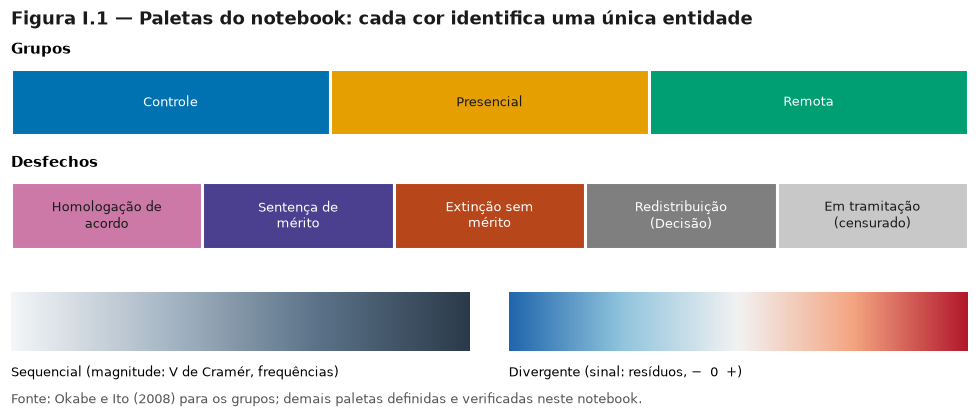

In [4]:
_MACHADO = {
    'protanopia': np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    'deuteranopia': np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
}


def _linear(cor):
    c = np.array(mpl.colors.to_rgb(cor))
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _oklab(rgb_linear):
    rgb_linear = np.clip(rgb_linear, 0, 1)
    lms = np.array([[0.4122214708, 0.5363325363, 0.0514459929], [0.2119034982, 0.6806995451, 0.1073969566],
                    [0.0883024619, 0.2817188376, 0.6299787005]]) @ rgb_linear
    return np.array([[0.2104542553, 0.7936177850, -0.0040720468], [1.9779984951, -2.4285922050, 0.4505937099],
                     [0.0259040371, 0.7827717662, -0.8086757660]]) @ np.cbrt(lms)


def delta_e(a, b, simulacao=None):
    """ΔE OKLab (×100) entre duas cores, opcionalmente sob simulação de daltonismo (Machado et al., 2009)."""
    A, B = _linear(a), _linear(b)
    if simulacao:
        A, B = _MACHADO[simulacao] @ A, _MACHADO[simulacao] @ B
    return 100 * float(np.linalg.norm(_oklab(A) - _oklab(B)))


def relatorio_cvd(nome, cores, pares):
    linhas = []
    for a, b in pares:
        d = {'Paleta': nome, 'Par': f'{a} × {b}', 'ΔE normal': delta_e(cores[a], cores[b])}
        for s in _MACHADO:
            d[f'ΔE {s}'] = delta_e(cores[a], cores[b], s)
        linhas.append(d)
    return linhas


_pares_grupo = [(a, b) for i, a in enumerate(ORDEM_GRUPO) for b in ORDEM_GRUPO[i + 1:]]
_pares_desf = list(zip(ORDEM_DESFECHO[:-1], ORDEM_DESFECHO[1:]))           # vizinhos nas barras empilhadas
_cromaticos = ['Homologação', 'Mérito', 'Sem mérito']
_cruzadas = {**{f'grupo {g}': CORES_GRUPO[g] for g in ORDEM_GRUPO}, **{f'desfecho {k}': CORES_DESFECHO[k] for k in _cromaticos}}
_pares_cruz = [(f'grupo {g}', f'desfecho {k}') for g in ORDEM_GRUPO for k in _cromaticos]
cvd = pd.DataFrame(relatorio_cvd('Grupos (todos os pares)', CORES_GRUPO, _pares_grupo)
                   + relatorio_cvd('Desfechos (vizinhos)', CORES_DESFECHO, _pares_desf)
                   + relatorio_cvd('Grupo × desfecho (mesmo gráfico)', _cruzadas, _pares_cruz))
cvd['Pior simulado'] = cvd[['ΔE protanopia', 'ΔE deuteranopia']].min(axis=1)
cvd['Situação'] = np.select([(cvd['Pior simulado'] >= 8) & (cvd['ΔE normal'] >= 15), cvd['Pior simulado'] >= 6],
                            ['passa', 'passa com rótulo/legenda'], 'exige 2º canal (forma, posição)')
resumo_cvd = cvd.groupby('Paleta', sort=False).agg(**{'Pares': ('Par', 'size'), 'Menor ΔE normal': ('ΔE normal', 'min'),
                                                      'Menor ΔE simulado': ('Pior simulado', 'min')})
tabela(resumo_cvd, 'cur_cvd_resumo', 'Distância perceptual mínima entre as cores de cada paleta (ΔE OKLab × 100)',
       secao='1.2.1', casas=1,
       nota='simulação de Machado, Oliveira e Fernandes (2009), severidade 1,0; alvo ≥ 8 sob simulação e ≥ 15 sem simulação. '
            'A linha "grupo × desfecho" é informativa: grupos e desfechos só dividem o mesmo gráfico quando a forma '
            '(linha × marcador) também os distingue.')
_fracos = cvd[cvd['Situação'] != 'passa']
if len(_fracos):
    print('Pares abaixo do alvo (exigem segundo canal):')
    for _, r in _fracos.iterrows():
        print(f"  {r['Par']}: ΔE normal {fmt_br(r['ΔE normal'])}; pior simulado {fmt_br(r['Pior simulado'])} → {r['Situação']}")

# Mapas sequencial e divergente: luminosidade OKLab monotônica
_L = lambda mapa, xs: [_oklab(_linear(mapa(x)))[0] for x in xs]
_seq_L = _L(SEQ, np.linspace(0, 1, 11))
_div_L = _L(DIV, np.linspace(0, 1, 11))
print('Sequencial: luminosidade decrescente (claro → escuro):', all(np.diff(_seq_L) < 0))
print('Divergente: luminosidade cresce até o meio e decresce depois:',
      all(np.diff(_div_L[:6]) > 0) and all(np.diff(_div_L[5:]) < 0))

fig, ax = plt.subplots(3, 1, figsize=(9, 3.4), gridspec_kw={'height_ratios': [1, 1, 0.8]})
for a, (nome, cores_) in zip(ax[:2], [('Grupos', {g: CORES_GRUPO[g] for g in ORDEM_GRUPO}),
                                       ('Desfechos', {ROTULO_DESFECHO[k]: CORES_DESFECHO[k] for k in ORDEM_DESFECHO})]):
    for i, (rot, cor) in enumerate(cores_.items()):
        a.barh(0, 1, left=i, color=cor, edgecolor='white', linewidth=2)
        a.text(i + 0.5, 0, quebra(rot, 14), ha='center', va='center', fontsize=8.5, color=_cor_texto(cor))
    a.set_xlim(0, len(cores_)); a.set_axis_off(); a.set_title(nome, loc='left', fontsize=10)
gradiente = np.linspace(0, 1, 256)[None, :]
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=SEQ, extent=(0, 0.48, 0, 1))
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=DIV, extent=(0.52, 1, 0, 1))
ax[2].set_xlim(0, 1); ax[2].set_axis_off()
ax[2].text(0, -0.25, 'Sequencial (magnitude: V de Cramér, frequências)', fontsize=8.5, va='top', transform=ax[2].transAxes)
ax[2].text(0.52, -0.25, 'Divergente (sinal: resíduos, −  0  +)', fontsize=8.5, va='top', transform=ax[2].transAxes)
figura(fig, 'cur_paletas', 'Paletas do notebook: cada cor identifica uma única entidade', secao='1.2.1',
       fonte='Fonte: Okabe e Ito (2008) para os grupos; demais paletas definidas e verificadas neste notebook.')

---

## 1.3 Formação do dataset bruto

### 1.3.1 As abas da planilha

O arquivo tem oito abas, mas só uma contém dados por processo. As demais são painéis, tabelas dinâmicas e listas de validação construídas **a partir** da aba `Processos`; servem apenas para conferência (seção 1.14).

In [5]:
livro = openpyxl.load_workbook(BRUTO, data_only=False)   # fórmulas, não valores
PAPEL_ABA = {
    'Processos': 'Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica',
    'Dash1': 'Painel (segmentações/gráficos), sem dados',
    'Dash2': 'Painel (segmentações/gráficos), sem dados',
    'Dash3': 'Painel (segmentações/gráficos), sem dados',
    'Tab_D': 'Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)',
    'Tabelas': 'Resumos com fórmulas (acordos, "eficiência" por rito)',
    'Resumo': 'Questionário de perguntas descritivas (valores vazios no cache)',
    'Lista': 'Listas das validações de dados (valores permitidos nas colunas)',
}
abas = pd.DataFrame([{
    'Aba': ws.title,
    'Visibilidade': 'oculta' if ws.sheet_state != 'visible' else 'visível',
    'Intervalo usado': ws.dimensions,
    'Células preenchidas': sum(c.value is not None for linha in ws.iter_rows() for c in linha),
    'Papel': PAPEL_ABA.get(ws.title, ''),
} for ws in livro.worksheets])
tabela(abas, 'cur_abas', 'Abas da planilha e o papel de cada uma: só a aba Processos tem dados por processo', secao='1.3.1')

ws = livro['Processos']
print('Tabela Excel na aba Processos:', {nome: ref for nome, ref in ws.tables.items()})
print('Colunas ocultas:', [c for c, d in ws.column_dimensions.items() if d.hidden])
print('Linha 1 (acima do cabeçalho):', [ws.cell(1, c).value for c in range(1, 16)])

Aba,Visibilidade,Intervalo usado,Células preenchidas,Papel
Processos,visível,A2:O946,13.317,Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica
Dash1,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash2,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash3,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Tab_D,oculta,A1:BG144,351,"Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)"
Tabelas,visível,A2:AL49,623,"Resumos com fórmulas (acordos, ""eficiência"" por rito)"
Resumo,visível,A2:C25,25,Questionário de perguntas descritivas (valores vazios no cache)
Lista,oculta,A1:I8,26,Listas das validações de dados (valores permitidos nas colunas)


Tabela Excel na aba Processos: {'TAB_DADOS': 'A2:O946'}
Colunas ocultas: ['J', 'M', 'P']
Linha 1 (acima do cabeçalho): [None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


### 1.3.2 Leitura da aba `Processos`

A linha 1 está vazia e o cabeçalho está na linha 2 (`header=1`). O índice de `dados_brutos` passa a ser o **número da linha no Excel** (`linha_excel`), o que permite rastrear cada tratamento até a célula de origem. `dados_brutos` não é modificado em nenhum momento.

In [6]:
dados_brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
dados_brutos.index = pd.RangeIndex(3, 3 + len(dados_brutos), name='linha_excel')

print(f'{dados_brutos.shape[0]} linhas × {dados_brutos.shape[1]} colunas (linhas 3 a {dados_brutos.index[-1]} do Excel)')
print('Nomes das colunas (repr, para ver espaços):')
print([c for c in dados_brutos.columns])
print(f'Linhas inteiramente vazias: {dados_brutos.isna().all(axis=1).sum()} | '
      f'números de processo distintos: {dados_brutos["NÚMERO DO PROCESSO"].nunique()}')
tabela(dados_brutos.head(5), 'cur_bruto_amostra', 'As cinco primeiras linhas da aba Processos, como lidas (dados brutos, sem tratamento)',
       secao='1.3.2', indice=True, exportar=False, nota='a primeira coluna (linha_excel) é o número da linha no Excel.')

944 linhas × 15 colunas (linhas 3 a 946 do Excel)
Nomes das colunas (repr, para ver espaços):
['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA', 'DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', ' DURAÇÃO DO PROCESSO', 'STATUS']


Linhas inteiramente vazias: 0 | números de processo distintos: 938


linha_excel,NÚMERO DO PROCESSO,DT. DISTRIBUIÇÃO,SORTEIO,HÍBRIDA,TEVE ACORDO NA AC?,TÉCNICA,TEVE ACORDO FORA DA AC?,SENTENÇA,DT. SENTENÇA,DURAÇÃO-SENT2,DURAÇÃO-TECN,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO DO PROCESSO,STATUS
3,0800001-35.2026.8.20.5004,01/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do feito sem julgamento de mérito,07/01/2026,6,–,6,6,6 dia(s),Encerrado
4,0800024-78.2026.8.20.5004,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,–,–,–,274,–,274,274,274 dia(s),Ativo
5,0808292-43.2025.8.20.5300,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito sem Julgamento de Mérito,09/01/2026,3,–,3,3,3 dia(s),Encerrado
6,0800038-62.2026.8.20.5004,07/01/2026,Ac Obrigatória Presencial,Não,Sim,Desconstrução da Verdade,Não,Extinção do Feito com Homologação do Acordo,22/02/2026,46,46,46,46,46 dia(s),Encerrado
7,0800035-10.2026.8.20.5004,07/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito com Julgamento de Mérito,27/02/2026,51,–,51,51,51 dia(s),Encerrado


**Leitura.**

- **Uma única aba tem dados.** A aba `Processos` (tabela Excel `TAB_DADOS`, intervalo A2:O946) é a fonte de tudo o que vem depois. As abas `Dash1` a `Dash3` estão vazias de dados (só segmentações e gráficos); `Tab_D` e `Lista` estão **ocultas** e contêm as tabelas dinâmicas e as listas de validação; `Tabelas` e `Resumo` são resumos calculados.
- **944 linhas, não 943.** A aba tem 944 linhas de dados (linhas 3 a 946 do Excel), com **938 números de processo distintos**: há números repetidos (seção 1.10). O enunciado fala em 943 processos porque uma linha (920) não tem as fórmulas de duração e de status (seção 1.4).
- **15 colunas, não 11.** Nove são digitadas pela unidade (A a I); seis são calculadas por fórmula (J a O), três delas ocultas (J, M e a coluna vazia P). O nome de uma coluna começa com espaço (`' DURAÇÃO DO PROCESSO'`), detalhe que quebra qualquer código que a procure pelo nome "limpo".

---

## 1.4 Colunas digitadas × colunas calculadas: a data de corte

As colunas J a O da planilha **não são dados**: são fórmulas. Ler as fórmulas (e não apenas os valores) é essencial, porque a duração dos processos sem sentença é calculada com `TODAY()`, uma função **volátil**: cada vez que o arquivo é aberto, o tempo dos processos ativos aumenta, sem que nenhuma informação nova tenha sido coletada. A célula mostra a fórmula de cada coluna calculada e conta quantas linhas têm fórmula.

In [7]:
COLUNAS_CALCULADAS = {'J': 'DURAÇÃO-SENT2', 'K': 'DURAÇÃO-TECN', 'L': 'DURAÇÃO-SORT', 'M': 'DURAÇÃO-PROC',
                      'N': 'DURAÇÃO DO PROCESSO', 'O': 'STATUS'}
ultima = 2 + len(dados_brutos)
formulas = []
for letra, nome in COLUNAS_CALCULADAS.items():
    valores = [ws[f'{letra}{r}'].value for r in range(3, ultima + 1)]
    com_formula = [isinstance(v, str) and v.startswith('=') for v in valores]
    formulas.append({'Coluna': letra, 'Nome': nome,
                     'Linhas com fórmula': sum(com_formula),
                     'Usa TODAY()': 'TODAY()' in str(valores[0]),
                     'Oculta': ws.column_dimensions[letra].hidden,
                     'Fórmula (linha 3)': valores[0]})
tabela(pd.DataFrame(formulas), 'cur_formulas', 'Colunas calculadas por fórmula (J a O): a duração dos ativos depende de TODAY()',
       secao='1.4')

sem_formula = [r for r in range(3, ultima + 1) if not str(ws[f'M{r}'].value or '').startswith('=')]
print('Linhas sem fórmula na coluna M:', sem_formula)
print('Conteúdo da linha', sem_formula[0], ':', [ws[f'{c}{sem_formula[0]}'].value for c in 'ABCDEFGHI'])

Coluna,Nome,Linhas com fórmula,Usa TODAY(),Oculta,Fórmula (linha 3)
J,DURAÇÃO-SENT2,943,Sim,Sim,"=IF(TAB_DADOS[[#This Row],[SENTENÇA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
K,DURAÇÃO-TECN,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[TÉCNICA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
L,DURAÇÃO-SORT,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[SORTEIO]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
M,DURAÇÃO-PROC,943,Sim,Sim,"=ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3))))"
N,DURAÇÃO DO PROCESSO,943,Não,Não,"=IF(TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]="""","""",TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]&"" dia(s)"")"
O,STATUS,943,Não,Não,"=IF(AND(B3="""",I3=""""),"""",IF(AND(NOT(ISBLANK(B3)),NOT(ISBLANK(I3))),""Encerrado"",""Ativo""))"


Linhas sem fórmula na coluna M: [920]
Conteúdo da linha 920 : ['0813782-27.2026.8.20.5004', datetime.datetime(2026, 7, 29, 0, 0), 'Ac Obrigatória Presencial', None, None, None, None, None, None]


Os **valores em cache** (o que o Excel calculou na última gravação e o que o `pandas` lê) revelam a data em que `TODAY()` foi avaliado: para cada processo ativo, `DT. DISTRIBUIÇÃO + DURAÇÃO-PROC` é essa data. Se ela for única, é a data de corte de fato usada pela pesquisadora.

In [8]:
ativos_bruto = dados_brutos['STATUS'].eq('Ativo')
data_referencia = (dados_brutos.loc[ativos_bruto, 'DT. DISTRIBUIÇÃO']
                   + pd.to_timedelta(dados_brutos.loc[ativos_bruto, 'DURAÇÃO-PROC'], unit='D'))
tabela(data_referencia.dt.strftime('%d/%m/%Y').value_counts().rename_axis('Data implícita de TODAY()').rename('Processos ativos').to_frame(),
       'cur_data_today', 'Data em que TODAY() foi avaliado, reconstituída dos valores em cache', secao='1.4')
assert data_referencia.nunique() == 1 and data_referencia.iloc[0] == DATA_CORTE

props = livro.properties
print(f'Última gravação do arquivo: {props.modified} (por {props.lastModifiedBy}); criado em {props.created:%d/%m/%Y}')
print(f'Sentença mais recente: {dados_brutos["DT. SENTENÇA"].max():%d/%m/%Y} | '
      f'distribuição mais recente: {dados_brutos["DT. DISTRIBUIÇÃO"].max():%d/%m/%Y}')
assert dados_brutos['DT. SENTENÇA'].max() <= DATA_CORTE and dados_brutos['DT. DISTRIBUIÇÃO'].max() <= DATA_CORTE

# As quatro durações são a mesma variável (E6): comparação célula a célula onde não nulas
DURACOES = ['DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT']
iguais = pd.DataFrame([{
    'Coluna': c,
    'Não nulas': int(dados_brutos[c].notna().sum()),
    'Iguais a DURAÇÃO-PROC': int((dados_brutos[c] == dados_brutos['DURAÇÃO-PROC']).sum()),
} for c in DURACOES])
texto_igual = (dados_brutos[' DURAÇÃO DO PROCESSO'].str.extract(r'(\d+)')[0].astype(float)
               == dados_brutos['DURAÇÃO-PROC']).sum()
tabela(iguais, 'cur_duracoes_iguais', 'As colunas de duração repetem DURAÇÃO-PROC (mesma variável, E6)', secao='1.4')
print(f'" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em {texto_igual} linhas')

Data implícita de TODAY(),Processos ativos
07/10/2026,209


Última gravação do arquivo: 2026-10-07 19:57:29 (por pvccr); criado em 28/01/2026
Sentença mais recente: 06/10/2026 | distribuição mais recente: 03/08/2026


Coluna,Não nulas,Iguais a DURAÇÃO-PROC
DURAÇÃO-SENT2,943,943
DURAÇÃO-TECN,428,428
DURAÇÃO-SORT,943,943


" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em 943 linhas


**Leitura. A data de corte é 07/10/2026, e precisa ser fixada.**

- **Todas as durações vêm de uma fórmula com `TODAY()`.** As 943 linhas com fórmula calculam `ABS(DT. SENTENÇA − DT. DISTRIBUIÇÃO)` quando há sentença e `ABS(TODAY() − DT. DISTRIBUIÇÃO)` quando não há.
- **Os 209 processos ativos apontam para uma única data: 07/10/2026.** É o dia da última gravação do arquivo (07/10/2026, 19h57) e o que está no nome do arquivo. A sentença mais recente é de 06/10/2026 e a última distribuição, de 03/08/2026, coerentes com essa data.
- **Por que fixar.** Se a planilha for aberta e recalculada hoje (12/11/2026), cada processo ativo "ganha" 36 dias sem nenhuma informação nova. O tempo é, por isso, recalculado em Python a partir das datas, com `DATA_CORTE = 07/10/2026`. O acompanhamento real vai de **65 dias** (distribuídos em 03/08) a **279 dias** (distribuídos em 01/01). A "janela de 218 dias" usada no notebook do professor não corresponde aos dados (E7).
- **As quatro colunas de duração são a mesma variável.** `DURAÇÃO-SENT2` e `DURAÇÃO-SORT` coincidem com `DURAÇÃO-PROC` nas 943 linhas; `DURAÇÃO-TECN` coincide nas 428 em que existe (é a mesma duração, apagada onde a técnica é `**`); o texto `"N dia(s)"` repete o número. Elas só serviam de filtro para as tabelas dinâmicas. Por isso a matriz de correlação do notebook do professor dá r = 1 em todos os pares (E6, E16): correlaciona uma variável consigo mesma.
- **O `ABS()` da fórmula esconderia datas trocadas** (sentença anterior à distribuição). A verificação direta nas datas (seção 1.14) mostra que não há nenhum caso.

---

## 1.5 Estrutura do dado bruto: o que o pandas leu

O `dtype` atribuído pelo `pandas` na leitura não é o tipo estatístico da variável. A coluna *tipos Python presentes* mostra o que realmente existe em cada coluna (por exemplo, `str` e `float` juntos indicam texto com células vazias, `NaN`).

In [9]:
def tipos_presentes(serie):
    """Tipos Python efetivamente presentes nas células não nulas, com contagem."""
    contagem = Counter(type(v).__name__ for v in serie.dropna())
    return ', '.join(f'{t} ({n})' for t, n in contagem.most_common())


perfil_bruto = pd.DataFrame({
    'dtype lido': dados_brutos.dtypes.astype(str),
    'tipos Python presentes': dados_brutos.apply(tipos_presentes),
    'não nulos': dados_brutos.notna().sum(),
    'NaN': dados_brutos.isna().sum(),
    'distintos': dados_brutos.nunique(),
    'exemplo (linha 3)': dados_brutos.iloc[0].astype(str).str.slice(0, 45),
})
tabela(perfil_bruto.rename_axis('Coluna bruta'), 'cur_perfil_bruto', 'Perfil das colunas como lidas pelo pandas: dtype, tipos presentes e ausências',
       secao='1.5', formatos={'dtype lido': 'texto'})

Coluna bruta,dtype lido,tipos Python presentes,não nulos,NaN,distintos,exemplo (linha 3)
NÚMERO DO PROCESSO,str,str (944),944,0,938,0800001-35.2026.8.20.5004
DT. DISTRIBUIÇÃO,datetime64[us],Timestamp (944),944,0,190,2026-01-01 00:00:00
SORTEIO,str,str (944),944,0,3,Rito Atual Ac Opcional
HÍBRIDA,str,str (872),872,72,2,Não
TEVE ACORDO NA AC?,str,str (869),869,75,2,Não
TÉCNICA,str,str (867),867,77,7,**
TEVE ACORDO FORA DA AC?,str,str (736),736,208,3,Não
SENTENÇA,str,str (734),734,210,5,Extinção do feito sem julgamento de mérito
DT. SENTENÇA,datetime64[us],Timestamp (734),734,210,179,2026-01-07 00:00:00
DURAÇÃO-SENT2,float64,float (943),943,1,189,6.0


---

## 1.6 Tipologia estatística das variáveis

A escolha de gráficos, medidas e testes depende do **tipo estatístico** de cada variável, não do `dtype`. A tabela classifica as colunas da planilha e indica o tipo `pandas` adequado a cada uma no dataset *tidy*:

- **nominal** → `category` (sem ordem); **ordinal** → `category` ordenada;
- **binária** → `boolean` (o tipo anulável do pandas, que aceita `<NA>` sem virar `object`);
- **quantitativa discreta** (contagem de dias) → `Int64` (inteiro anulável);
- **data** → `datetime64`; **identificador** → `string` (não é medida: não se calcula média de número de processo).

Note-se que o tempo em dias é discreto por registro, mas é tratado como **contínuo** nos modelos de sobrevivência (com empates). As colunas J a O são descartadas: são derivadas por fórmula, redundantes entre si e dependentes de `TODAY()`.

In [10]:
TIPOLOGIA_BRUTA = pd.DataFrame([
    ('NÚMERO DO PROCESSO', 'Identificador', '—', 'string', 'Mantida como `processo` (limpa e validada)'),
    ('DT. DISTRIBUIÇÃO', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Origem do tempo; gera mês, dia da semana, ordem'),
    ('SORTEIO', 'Qualitativa nominal (3 níveis)', 'nominal', 'category', 'Tratamento sorteado → `grupo`'),
    ('HÍBRIDA', 'Qualitativa binária', 'nominal', 'boolean', 'Adesão ao protocolo (pós-sorteio)'),
    ('TEVE ACORDO NA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('TÉCNICA', 'Qualitativa nominal (6 níveis + "**")', 'nominal', 'category', '`**` → AC não realizada (`ac_realizada`)'),
    ('TEVE ACORDO FORA DA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('SENTENÇA', 'Qualitativa nominal (4 níveis)', 'nominal', 'category', 'Tipo de desfecho; define o evento'),
    ('DT. SENTENÇA', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Fim do tempo quando há desfecho'),
    ('DURAÇÃO-SENT2', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-TECN', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: cópia filtrada de DURAÇÃO-PROC'),
    ('DURAÇÃO-SORT', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-PROC', 'Quantitativa discreta (dias)', 'razão', 'Int64', 'Recalculada pelas datas → `tempo` (com censura)'),
    (' DURAÇÃO DO PROCESSO', 'Texto ("N dia(s)")', '—', '—', 'Descartada: DURAÇÃO-PROC em texto'),
    ('STATUS', 'Qualitativa binária', 'nominal', 'boolean', 'Recalculada pela data → `encerrado`'),
], columns=['Coluna bruta', 'Tipo estatístico', 'Escala de medida', 'dtype adequado', 'Decisão'])
TIPOLOGIA_BRUTA.insert(1, 'dtype lido', TIPOLOGIA_BRUTA['Coluna bruta'].map(dados_brutos.dtypes.astype(str)))
tabela(TIPOLOGIA_BRUTA, 'cur_tipologia', 'Tipologia estatística das colunas da planilha e decisão de tratamento', secao='1.6')

Coluna bruta,dtype lido,Tipo estatístico,Escala de medida,dtype adequado,Decisão
NÚMERO DO PROCESSO,str,Identificador,—,string,Mantida como `processo` (limpa e validada)
DT. DISTRIBUIÇÃO,datetime64[us],Data,intervalar (tempo de calendário),datetime64,"Origem do tempo; gera mês, dia da semana, ordem"
SORTEIO,str,Qualitativa nominal (3 níveis),nominal,category,Tratamento sorteado → `grupo`
HÍBRIDA,str,Qualitativa binária,nominal,boolean,Adesão ao protocolo (pós-sorteio)
TEVE ACORDO NA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
TÉCNICA,str,"Qualitativa nominal (6 níveis + ""**"")",nominal,category,`**` → AC não realizada (`ac_realizada`)
TEVE ACORDO FORA DA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
SENTENÇA,str,Qualitativa nominal (4 níveis),nominal,category,Tipo de desfecho; define o evento
DT. SENTENÇA,datetime64[us],Data,intervalar (tempo de calendário),datetime64,Fim do tempo quando há desfecho
DURAÇÃO-SENT2,float64,Quantitativa discreta (dias),razão,—,"Descartada: fórmula, cópia de DURAÇÃO-PROC"


---

## 1.7 Ausências: `NaN`, `**` e células em branco

A planilha tem **três formas** de "não há valor", que não significam a mesma coisa e não podem ser fundidas:

| Forma | Significado | Exemplo |
|---|---|---|
| `NaN` (célula vazia) | **ainda não informado**: o processo não chegou àquela etapa (quase sempre em tramitação) | `SENTENÇA` vazia num processo ativo |
| `**` | **não se aplica**: a etapa não existe para aquele processo (zero estrutural) | `TÉCNICA = **` no Controle, que não tem audiência |
| texto vazio/espaços | erro de digitação | — |

O notebook do professor tratou `**` como categoria nos gráficos de Pareto e, no Controle, leu "Não" como resposta, quando a pergunta não se aplica (E4, E5).

In [11]:
COLUNAS_DIGITADAS = ['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?',
                     'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA']


def resumo_ausencias(df, colunas):
    linhas = []
    for c in colunas:
        s = df[c]
        texto = s.dropna().astype(str)
        linhas.append({'Coluna': c, 'NaN': int(s.isna().sum()), '"**"': int(texto.eq('**').sum()),
                       'Vazio/espaços': int(texto.str.strip().eq('').sum()),
                       'Válidos': int(s.notna().sum() - texto.eq('**').sum() - texto.str.strip().eq('').sum())})
    return pd.DataFrame(linhas).set_index('Coluna')


tabela(resumo_ausencias(dados_brutos, COLUNAS_DIGITADAS), 'cur_ausencias', 'Três formas de ausência por coluna digitada (linhas da planilha)',
       secao='1.7', nota='NaN = não informado; "**" = não se aplica (zero estrutural).')

Coluna,NaN,"""**""",Vazio/espaços,Válidos
NÚMERO DO PROCESSO,0,0,0,944
DT. DISTRIBUIÇÃO,0,0,0,944
SORTEIO,0,0,0,944
HÍBRIDA,72,0,0,872
TEVE ACORDO NA AC?,75,0,0,869
TÉCNICA,77,515,0,352
TEVE ACORDO FORA DA AC?,208,1,0,735
SENTENÇA,210,0,0,734
DT. SENTENÇA,210,0,0,734


### 1.7.1 Padrões de ausência

Se as ausências dependem da **etapa** do processo, elas aparecem em blocos: quem ainda não teve audiência não tem acordo na AC, técnica, acordo fora nem sentença. A tabela codifica, para cinco colunas, `1` = `NaN` e `0` = preenchido, e cruza o padrão com o status e o grupo sorteado.

In [12]:
COLUNAS_PADRAO = ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']
padrao = dados_brutos[COLUNAS_PADRAO].isna().astype(int).astype(str).agg(''.join, axis=1).rename('padrão')
tabela_padrao = pd.concat([
    pd.crosstab(padrao, dados_brutos['STATUS'].fillna('(vazio)')),
    pd.crosstab(padrao, dados_brutos['SORTEIO']),
], axis=1)
tabela_padrao['Total'] = padrao.value_counts()
tabela_padrao['Linhas (se ≤ 3)'] = padrao.groupby(padrao).apply(
    lambda s: ', '.join(map(str, s.index)) if len(s) <= 3 else '')
tabela(tabela_padrao.sort_values('Total', ascending=False).rename_axis('Padrão (1 = NaN)'), 'cur_padroes_ausencia',
       'Padrões de ausência em cinco colunas, por status e grupo sorteado: as lacunas acompanham a etapa do processo',
       secao='1.7.1', formatos={'Padrão (1 = NaN)': 'texto'},
       nota='ordem das posições no padrão: ' + ', '.join(COLUNAS_PADRAO) + '.')
print('Ordem das colunas no padrão:', COLUNAS_PADRAO)

Padrão (1 = NaN),(vazio),Ativo,Encerrado,Ac Obrigatória Presencial,Ac Remota,Rito Atual Ac Opcional,Total,Linhas (se ≤ 3)
00000,0,0,733,240,225,268,733,
00011,0,132,0,50,36,46,132,
11111,1,71,0,24,48,0,72,
01111,0,3,0,1,2,0,3,"268, 369, 832"
00001,0,2,0,0,2,0,2,"566, 607"
00111,0,1,0,0,1,0,1,249
00100,0,0,1,1,0,0,1,373


Ordem das colunas no padrão: ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']


O mapa abaixo mostra a mesma informação linha a linha, na ordem de chegada dos processos (eixo vertical). Cinza claro = preenchido; azul-acinzentado claro = `**` (não se aplica); ardósia escura = `NaN` (não informado).

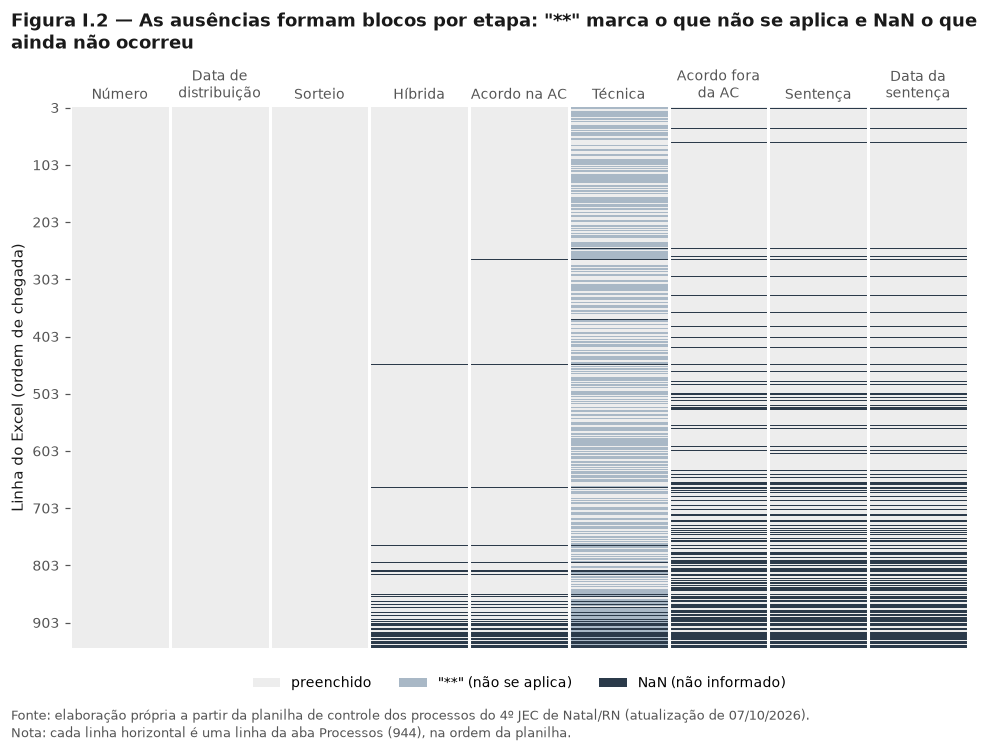

In [13]:
codigo_ausencia = pd.DataFrame({
    c: np.select([dados_brutos[c].isna(), dados_brutos[c].astype(str).eq('**')], [2, 1], 0)
    for c in COLUNAS_DIGITADAS})
CORES_AUSENCIA = ['#EDEDED', '#A9B8C6', '#2B3A4A']   # preenchido, "**", NaN (sem matizes de grupo/desfecho)
fig, ax = plt.subplots(figsize=(9, 6))
mapa = mpl.colors.ListedColormap(CORES_AUSENCIA)
ax.imshow(codigo_ausencia.to_numpy(), aspect='auto', cmap=mapa, interpolation='nearest', vmin=0, vmax=2)
ROTULOS_CURTOS = ['Número', 'Data de distribuição', 'Sorteio', 'Híbrida', 'Acordo na AC', 'Técnica', 'Acordo fora da AC',
                  'Sentença', 'Data da sentença']
ax.set_xticks(range(len(COLUNAS_DIGITADAS)), [quebra(r, 12) for r in ROTULOS_CURTOS])
ax.xaxis.tick_top()
ax.tick_params(axis='x', length=0)
ax.set_yticks(np.arange(0, len(codigo_ausencia), 100), dados_brutos.index[::100])
ax.set_ylabel('Linha do Excel (ordem de chegada)')
ax.grid(False)
for sp_ in ax.spines.values():
    sp_.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(COLUNAS_DIGITADAS)), minor=True)
ax.grid(which='minor', axis='x', color='white', lw=2)
ax.tick_params(which='minor', length=0)
legenda = [mpl.patches.Patch(color=c, label=r) for c, r in
           zip(CORES_AUSENCIA, ['preenchido', '"**" (não se aplica)', 'NaN (não informado)'])]
legenda_abaixo(ax, handles=legenda, ncol=3, dy=-0.03)
figura(fig, 'cur_mapa_ausencias',
       'As ausências formam blocos por etapa: "**" marca o que não se aplica e NaN o que ainda não ocorreu',
       secao='1.7.1', nota='cada linha horizontal é uma linha da aba Processos (944), na ordem da planilha.')

**Leitura. As ausências são estruturais: dependem da etapa em que o processo está.**

- **Não há texto vazio nem espaços soltos**; as ausências são `NaN` (célula vazia) ou o marcador `**`.
- **`**` aparece em duas colunas.** Em `TÉCNICA` (515 linhas) significa que a audiência não foi realizada: todo o Controle e parte dos tratados. Em `ACORDO FORA DA AC?` aparece uma única vez (linha 888), um erro de preenchimento.
- **Os `NaN` formam blocos coerentes com a tramitação:**
  - **733 linhas completas**, todas encerradas;
  - **132 ativos** com audiência já registrada, aguardando o acordo fora e a sentença (padrão `00011`);
  - **72 linhas sem nada após o sorteio** (padrão `11111`): 71 ativos e a linha 920, recém-distribuídos, **todos dos grupos com audiência** (24 Presencial, 48 Remota, 0 Controle). No Controle não há audiência a aguardar, e a unidade já preenche `Não`/`**` na distribuição;
  - **sete linhas com padrões isolados**, listadas na tabela e tratadas nas seções 1.11 e 1.12. A mais relevante é a linha 373: um processo encerrado com a técnica em branco.
- **No mapa, os `NaN` se concentram nas últimas linhas**, as de chegada mais recente. É a assinatura de uma ausência que depende do tempo de acompanhamento, e não de um sorteio ao acaso (não é MCAR).
- **Consequência.** Nenhuma imputação é necessária nem adequada. O desfecho principal (tempo até a sentença) trata a falta de sentença como **censura**. As variáveis de processo (híbrida, técnica, acordo na AC) são analisadas onde se aplicam, com a ausência declarada, e não por exclusão silenciosa de casos incompletos, como fazem os testes do notebook do professor (E5).

---

## 1.8 Cópia de trabalho, nomes das colunas e registro de tratamentos

A partir daqui as transformações acontecem em `trab`, uma cópia de `dados_brutos` com nomes em *snake_case* (minúsculas, sem acento, válidos como identificador Python). As colunas calculadas (J a O) são mantidas na cópia apenas para conferência e descartadas no dataset final.

Cada correção, exclusão ou recodificação é anotada pela função `registrar()` num **log de tratamentos**, com a linha do Excel, o processo, a variável, o valor original, o valor novo, o problema e a justificativa. O código `A`*n* remete ao catálogo de anomalias da auditoria dos dados.

In [14]:
RENOMEAR = {
    'NÚMERO DO PROCESSO': 'numero_bruto', 'DT. DISTRIBUIÇÃO': 'dt_distribuicao', 'SORTEIO': 'sorteio',
    'HÍBRIDA': 'hibrida_bruto', 'TEVE ACORDO NA AC?': 'acordo_ac_bruto', 'TÉCNICA': 'tecnica_bruto',
    'TEVE ACORDO FORA DA AC?': 'acordo_fora_bruto', 'SENTENÇA': 'sentenca_bruto', 'DT. SENTENÇA': 'dt_sentenca',
    'DURAÇÃO-SENT2': 'xl_duracao_sent2', 'DURAÇÃO-TECN': 'xl_duracao_tecn', 'DURAÇÃO-SORT': 'xl_duracao_sort',
    'DURAÇÃO-PROC': 'xl_duracao_proc', ' DURAÇÃO DO PROCESSO': 'xl_duracao_texto', 'STATUS': 'xl_status',
}
trab = dados_brutos.rename(columns=RENOMEAR).copy()
assert set(RENOMEAR) == set(dados_brutos.columns)
assert all(c.isidentifier() and c.isascii() for c in trab.columns)

_registros = []


def registrar(linhas, variavel, valor_novo, problema, tratamento, codigo, valor_original=None):
    """Anota um tratamento para cada linha do Excel informada (valor original lido de dados_brutos)."""
    linhas = [linhas] if np.isscalar(linhas) else list(linhas)
    coluna_bruta = {v: k for k, v in RENOMEAR.items()}.get(variavel)
    for linha in linhas:
        original = valor_original
        if original is None and coluna_bruta is not None:
            original = dados_brutos.at[linha, coluna_bruta]
        _registros.append({'codigo': codigo, 'linha_excel': int(linha),
                           'processo_bruto': dados_brutos.at[linha, 'NÚMERO DO PROCESSO'],
                           'variavel': variavel, 'valor_original': repr(original) if isinstance(original, str) else str(original),
                           'valor_novo': str(valor_novo), 'problema': problema, 'tratamento': tratamento})


def log_tratamentos():
    return pd.DataFrame(_registros)


tabela(pd.DataFrame({'Coluna original': [repr(k) for k in RENOMEAR], 'Nome na cópia de trabalho': list(RENOMEAR.values())}),
       'cur_renomear', 'Nomes das colunas na cópia de trabalho (o repr mostra espaços extras do original)', secao='1.8')

Coluna original,Nome na cópia de trabalho
'NÚMERO DO PROCESSO',numero_bruto
'DT. DISTRIBUIÇÃO',dt_distribuicao
'SORTEIO',sorteio
'HÍBRIDA',hibrida_bruto
'TEVE ACORDO NA AC?',acordo_ac_bruto
'TÉCNICA',tecnica_bruto
'TEVE ACORDO FORA DA AC?',acordo_fora_bruto
'SENTENÇA',sentenca_bruto
'DT. SENTENÇA',dt_sentenca
'DURAÇÃO-SENT2',xl_duracao_sent2


---

## 1.9 Número do processo (CNJ)

O número único segue a Resolução CNJ 65/2008: `NNNNNNN-DD.AAAA.J.TR.OOOO` (sequencial, dígito verificador, ano de ajuizamento, segmento da Justiça, tribunal e órgão de origem). O dígito verificador (DV) é calculado pelo **módulo 97** (ISO 7064): `DD = 98 − (NNNNNNN AAAA J TR OOOO 00 mod 97)`. Validar o DV detecta erros de digitação no número, a chave que permite cruzar a base com o PJe e o DataJud.

A limpeza tem três passos, cada um registrado:

1. remover espaços e quebras de linha nas bordas;
2. remover hífen final digitado por engano;
3. completar o órgão truncado com 3 dígitos, **somente se** o DV confirmar o órgão do estudo (5004 = 4º JEC de Natal).

In [15]:
PADRAO_CNJ = re.compile(r'^(\d{7})-(\d{2})\.(\d{4})\.(\d)\.(\d{2})\.(\d{4})$')


def dv_cnj(sequencial, ano, j, tr, orgao):
    """Dígito verificador CNJ (mod 97, ISO 7064)."""
    return 98 - int(f'{sequencial}{ano}{j}{tr}{orgao}00') % 97


def cnj_valido(numero):
    m = PADRAO_CNJ.fullmatch(str(numero))
    return bool(m) and int(m.group(2)) == dv_cnj(m.group(1), m.group(3), m.group(4), m.group(5), m.group(6))


numero = trab['numero_bruto'].astype('string')
fora = ~numero.map(lambda n: bool(PADRAO_CNJ.fullmatch(n))).astype(bool)
print('Fora do padrão antes da limpeza:', int(fora.sum()), '→ linhas', list(trab.index[fora]))
tabela(numero[fora].map(repr).rename('Valor bruto (repr)').to_frame().rename_axis('Linha do Excel'), 'cur_cnj_fora',
       'Números de processo fora do padrão CNJ antes da limpeza', secao='1.9', formatos={'Linha do Excel': 'texto'})

# Passo 1 — espaços e quebras de linha
passo1 = numero.str.strip()
alterado = trab.index[passo1 != numero]
registrar(alterado, 'numero_bruto', '(sem espaços)', 'Espaço ou quebra de linha no fim do número',
          'strip()', 'A7')

# Passo 2 — hífen final
passo2 = passo1.str.replace(r'\s*-\s*$', '', regex=True)
alterado = trab.index[passo2 != passo1]
registrar(alterado, 'numero_bruto', '(sem hífen final)', 'Hífen digitado após o número', 'Sufixo removido', 'A7')

# Passo 3 — órgão truncado (3 dígitos): candidatos que fecham o DV
truncado = passo2.str.match(r'^\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{3}$')
candidatos = {}
for linha in trab.index[truncado]:
    seq, dv, ano, j, tr, _ = re.split(r'[-.]', passo2[linha])
    candidatos[linha] = [o for o in range(5000, 5400) if dv_cnj(seq, ano, j, tr, o) == int(dv)]
tabela(pd.DataFrame({'Número truncado': passo2[truncado],
                     'Órgãos 5000–5399 com DV válido': pd.Series(candidatos).map(lambda l: ', '.join(map(str, l)))}
                    ).rename_axis('Linha do Excel'),
       'cur_cnj_truncado', 'Números com órgão truncado: órgãos candidatos que fecham o dígito verificador', secao='1.9',
       formatos={'Linha do Excel': 'texto'})
passo3 = passo2.copy()
for linha, lista in candidatos.items():
    assert 5004 in lista, f'linha {linha}: DV não fecha com 5004'
    passo3[linha] = passo2[linha] + '4'
registrar(list(candidatos), 'numero_bruto', '(órgão 5004)', 'Órgão de origem com 3 dígitos ("500")',
          'Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido', 'A8')

trab['processo'] = passo3
trab['cnj_corrigido'] = trab.index.isin(trab.index[(passo3 != numero.str.strip())])
partes = trab['processo'].str.extract(PADRAO_CNJ)
partes.columns = ['seq', 'dv', 'ano', 'j', 'tr', 'orgao']
trab['dv_valido'] = trab['processo'].map(cnj_valido)
trab['cnj_ano'] = partes['ano'].astype('Int64')
trab['cnj_orgao'] = partes['orgao']
print(f'Após a limpeza: {int(partes["seq"].notna().sum())} no padrão; DV válido em {int(trab["dv_valido"].sum())}; '
      f'J.TR = {sorted((partes["j"] + "." + partes["tr"]).unique())}')
assert trab['dv_valido'].all()

Fora do padrão antes da limpeza: 6 → linhas [55, 377, 443, 453, 692, 771]


Linha do Excel,Valor bruto (repr)
55,'0800780-87.2026.8.20.5004-'
377,'0805750-33.2026.8.20.5004\xa0-'
443,'0806633-77.2026.8.20.500'
453,'0806739-39.2026.8.20.500'
692,'0809702-20.2026.8.20.5004 '
771,'0811548-72.2026.8.20.5004\n'


Linha do Excel,Número truncado,Órgãos 5000–5399 com DV válido
443,0806633-77.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"
453,0806739-39.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"


Após a limpeza: 944 no padrão; DV válido em 944; J.TR = ['8.20']


### 1.9.1 Processos de outro órgão ou de ano anterior

O órgão `5004` é o 4º JEC de Natal e o ano esperado é 2026. Números de outro órgão ou de ano anterior indicam processos **ajuizados em outra unidade e redistribuídos** ao 4º JEC: a "data de distribuição" da planilha é a data de chegada à vara, não a do ajuizamento. Eles são mantidos (entraram no sorteio quando chegaram, e o relógio do estudo começa ali), marcados com `origem_externa` para análise de sensibilidade.

In [16]:
trab['origem_externa'] = trab['cnj_orgao'].ne('5004') | trab['cnj_ano'].lt(2026)
tabela(pd.crosstab([trab['cnj_ano'].astype(str).rename('Ano (CNJ)'), trab['cnj_orgao'].rename('Órgão (CNJ)')],
                   trab['sorteio'], margins=True, margins_name='Total'),
       'cur_cnj_orgao_ano', 'Ano e órgão de origem do número CNJ por grupo sorteado (linhas da planilha)', secao='1.9.1', indice=True)
registrar(trab.index[trab['origem_externa']], 'numero_bruto', 'origem_externa=True',
          'Número de outro órgão ou de ano anterior (processo redistribuído à vara)',
          'Mantido; flag origem_externa para sensibilidade', 'A9', valor_original='(órgão/ano)')
print(f'origem_externa: {int(trab["origem_externa"].sum())} linhas')

origem_externa: 12 linhas


---

## 1.10 Duplicidades e reentradas

A unidade experimental é o **processo**: cada um deve aparecer uma vez, com o grupo do seu sorteio. Depois da limpeza do número, há processos com mais de uma linha. A tabela mostra todos, para que a regra de decisão seja verificável:

In [17]:
duplicados = trab[trab['processo'].duplicated(keep=False)].sort_values(['processo', 'dt_distribuicao'])
tabela(duplicados[['processo', 'dt_distribuicao', 'sorteio', 'tecnica_bruto', 'sentenca_bruto', 'dt_sentenca', 'xl_status']]
       .rename_axis('Linha do Excel').rename(columns={'processo': 'Processo', 'dt_distribuicao': 'Distribuição', 'sorteio': 'Sorteio',
                                                       'tecnica_bruto': 'Técnica', 'sentenca_bruto': 'Sentença',
                                                       'dt_sentenca': 'Data da sentença', 'xl_status': 'STATUS'}),
       'cur_duplicados', 'Números de processo repetidos: reentradas após redistribuição, às vezes sorteadas para outro grupo',
       secao='1.10', formatos={'Linha do Excel': 'texto', 'Processo': 'texto'})
print(f'{duplicados["processo"].nunique()} números repetidos em {len(duplicados)} linhas; '
      f'{trab["processo"].nunique()} processos distintos')

Linha do Excel,Processo,Distribuição,Sorteio,Técnica,Sentença,Data da sentença,STATUS
162,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,**,Decisão,18/02/2026,Encerrado
164,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,–,–,–,Ativo
290,0804436-52.2026.8.20.5004,18/03/2026,Ac Obrigatória Presencial,**,Decisão,18/03/2026,Encerrado
322,0804436-52.2026.8.20.5004,24/03/2026,Ac Obrigatória Presencial,**,Decisão,09/04/2026,Encerrado
475,0804436-52.2026.8.20.5004,27/04/2026,Rito Atual Ac Opcional,**,Decisão,27/04/2026,Encerrado
591,0808905-44.2026.8.20.5004,20/05/2026,Ac Remota,**,Decisão,21/05/2026,Encerrado
607,0808905-44.2026.8.20.5004,22/05/2026,Ac Remota,**,–,–,Ativo
819,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,–,–,–,Ativo
822,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,**,Extinção do Feito com Homologação do Acordo,16/09/2026,Encerrado
851,0812839-10.2026.8.20.5004,15/07/2026,Ac Remota,Padrões Objetivos,–,–,Ativo


5 números repetidos em 11 linhas; 938 processos distintos


Há duas situações diferentes:

- **Duplicata de registro** (A3, A4): a segunda linha é uma cópia vazia ou desatualizada do mesmo processo, no mesmo grupo. Mantê-la criaria um **falso censurado** (por exemplo, a linha 164 ficaria "ativa" por 236 dias, embora o processo tenha sido redistribuído em 5 dias). → excluir a cópia e manter o registro mais antigo/completo.
- **Reentrada após `Decisão`** (A5): o processo saiu por redistribuição, voltou à vara e foi **sorteado de novo**; o `0804436-52` passou de Presencial para Controle. Reentradas violam a unicidade da unidade experimental e contaminam os grupos (E3). → na base primária, por **intenção de tratar**, vale só o **primeiro episódio**, com o grupo do primeiro sorteio. As alternativas (excluir o processo; unir os episódios) ficam para a análise de sensibilidade, a partir do arquivo com todas as linhas.

In [18]:
EXCLUIR_PRIMARIA = {
    164: ('A3', 'Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)'),
    819: ('A3', 'Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho'),
    857: ('A4', 'Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo'),
    322: ('A5', 'Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado'),
    475: ('A5', 'Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo'),
    607: ('A5', 'Reentrada de 0808905-44 um dia após a Decisão; re-sorteado'),
}
# Conferência: toda linha excluída tem o mesmo número que uma linha mantida, e esta é anterior ou igual na data
for linha, (codigo, motivo) in EXCLUIR_PRIMARIA.items():
    mesmos = trab.index[trab['processo'].eq(trab.at[linha, 'processo'])]
    mantidas = [m for m in mesmos if m not in EXCLUIR_PRIMARIA]
    assert len(mantidas) == 1 and trab.at[mantidas[0], 'dt_distribuicao'] <= trab.at[linha, 'dt_distribuicao']
    registrar(linha, 'processo', 'excluída da base primária', motivo,
              f'Excluída; mantida a linha {mantidas[0]} (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)',
              codigo, valor_original=trab.at[linha, 'processo'])

trab['base_primaria'] = ~trab.index.isin(list(EXCLUIR_PRIMARIA))
trab['motivo_exclusao'] = pd.Series({k: f'{v[0]}: {v[1]}' for k, v in EXCLUIR_PRIMARIA.items()},
                                    dtype='string').reindex(trab.index)
trab['duplicado_removido'] = trab['processo'].duplicated(keep=False) & trab['base_primaria']
trab['reentrada'] = trab['processo'].duplicated(keep='first')  # 2º episódio em diante (inclui duplicatas)
assert not trab.loc[trab['base_primaria'], 'processo'].duplicated().any()
print('Base primária:', int(trab['base_primaria'].sum()), 'processos')
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio'), trab['base_primaria'].map({True: 'Mantidas', False: 'Excluídas'}),
                   margins=True, margins_name='Total'),
       'cur_base_primaria', 'Linhas mantidas na base primária e excluídas (duplicata/reentrada), por grupo sorteado', secao='1.10')

Base primária: 938 processos


Sorteio,Excluídas,Mantidas,Total
Ac Obrigatória Presencial,2,314,316
Ac Remota,3,311,314
Rito Atual Ac Opcional,1,313,314
Total,6,938,944


**Leitura.**

- **São 5 números repetidos em 11 linhas**, ou seja, 6 linhas a mais que processos. O notebook do professor contou essas 6 linhas extras como "6 duplicatas" e não as tratou (E3).
- **Três são duplicatas de registro** (linhas 164, 819 e 857): cópias vazias ou desatualizadas do mesmo processo, no mesmo grupo. A linha 164, por exemplo, ficaria "em tramitação" por 236 dias, quando o processo foi redistribuído 5 dias depois de chegar (linha 162).
- **Três são reentradas re-sorteadas** (linhas 322, 475 e 607):
  - o processo `0804436-52` saiu por `Decisão` em 18/03, voltou em 24/03 (Presencial, nova Decisão em 09/04) e voltou de novo em 27/04, quando foi sorteado para o **Controle** (nova Decisão no mesmo dia);
  - o `0808905-44` foi redistribuído em 21/05 e voltou no dia 22/05, sorteado de novo.
- **Lição de desenho.** Um processo que sai e volta não deveria passar por novo sorteio: deveria herdar o grupo original.
- **Base primária: 938 processos** (Controle 313, Presencial 314, Remota 311), cada um com o grupo do primeiro sorteio (intenção de tratar). As 944 linhas ficam preservadas em `ed2_todas_linhas.pkl` para as análises de sensibilidade.

---

## 1.11 Categorias: grafia, partições e recodificações

### 1.11.1 Funções de normalização

Uma variável categórica bem construída é uma **partição** dos casos: exaustiva, disjunta, sem classes vazias e sem sinônimos (a mesma categoria com duas grafias). Três funções garantem isso:

- `limpar_texto` colapsa espaços e quebras de linha e converte texto vazio em `<NA>`;
- `normalizar_chave` gera uma chave de comparação sem acento, em maiúsculas e com espaços simples; duas grafias com a mesma chave são **sinônimos**;
- `para_categoria` aplica um **mapa explícito** (valor original → rótulo) e recusa valores não previstos; `verificar_particao` confere as propriedades com `assert`, de modo que um erro interrompe a execução em vez de passar despercebido.

In [19]:
def limpar_texto(serie):
    """Colapsa espaços/quebras de linha e converte vazio em NA (dtype string)."""
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().replace('', pd.NA)


def normalizar_chave(texto):
    """Chave de comparação: sem acentos, maiúscula, espaços simples (não altera o dado)."""
    if pd.isna(texto):
        return pd.NA
    texto = unicodedata.normalize('NFKD', str(texto))
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', texto).strip().upper()


def para_categoria(serie, mapa, ordem, ordenada=False):
    """Aplica um mapa exaustivo (valor original → rótulo) e devolve dtype category."""
    sem_mapa = sorted(set(serie.dropna().unique()) - set(mapa))
    assert not sem_mapa, f'Valores sem mapeamento: {sem_mapa}'
    rotulos = serie.map(mapa)
    assert set(rotulos.dropna()) <= set(ordem), 'Há rótulos fora da lista de categorias'
    return pd.Series(pd.Categorical(rotulos, categories=ordem, ordered=ordenada), index=serie.index, name=serie.name)


resumo_particoes = []


def verificar_particao(nova, nome, ausentes_permitidos=0):
    """Confere se uma variável category é partição: exaustiva, sem vazias e sem sinônimos."""
    contagem = nova.value_counts(sort=False, dropna=True)
    chaves = pd.Series(contagem.index.astype(str)).map(normalizar_chave)
    resultado = {'Variável': nome, 'Categorias': len(contagem), 'Vazias': int((contagem == 0).sum()),
                 'NA': int(nova.isna().sum()), 'Sinônimos': int(chaves.duplicated().sum()),
                 'Soma = n': int(contagem.sum() + nova.isna().sum()) == len(nova)}
    resultado['Partição válida'] = (resultado['Vazias'] == 0 and resultado['Sinônimos'] == 0
                                    and resultado['NA'] <= ausentes_permitidos and resultado['Soma = n'])
    assert resultado['Partição válida'], f'{nome} não é partição: {resultado}'
    resumo_particoes.append(resultado)
    return contagem


COLUNAS_TEXTO = ['sorteio', 'hibrida_bruto', 'acordo_ac_bruto', 'tecnica_bruto', 'acordo_fora_bruto', 'sentenca_bruto']
diagnostico = []
for c in COLUNAS_TEXTO:
    original = trab[c].astype('string')
    limpo = limpar_texto(trab[c])
    chaves = original.dropna().map(normalizar_chave)
    diagnostico.append({'Variável': c, 'Valores alterados pela limpeza': int((original != limpo).sum()),
                        'Grafias distintas': original.nunique(), 'Chaves distintas': chaves.nunique()})
    trab[c] = limpo
tabela(pd.DataFrame(diagnostico), 'cur_grafias', 'Grafias distintas e chaves normalizadas por coluna categórica', secao='1.11.1')

Variável,Valores alterados pela limpeza,Grafias distintas,Chaves distintas
sorteio,0,3,3
hibrida_bruto,0,2,2
acordo_ac_bruto,0,2,2
tecnica_bruto,0,7,7
acordo_fora_bruto,0,3,3
sentenca_bruto,0,5,4


### 1.11.2 Tipo de sentença: uma variante de caixa e o significado de "Decisão"

`SENTENÇA` tem cinco grafias, mas só quatro chaves: `Extinção do feito sem julgamento de mérito` (minúsculas, 11 casos de janeiro) é a mesma categoria que `Extinção do Feito sem Julgamento de Mérito`. A validação de lista do Excel não distingue maiúsculas, por isso a variante passou.

`Decisão` **não é sentença**. Segundo o pesquisador, é a decisão que remete o processo para redistribuição a outro juízo, por prevenção: o processo **sai da vara** e o seu desfecho deixa de ser observado. Contá-la como sentença, como faz o notebook do professor (E10), encurta artificialmente o tempo dos grupos. Aqui ela vira o desfecho `Redistribuição`, tratado como censura na análise principal e como risco competitivo na complementar (Parte IV).

In [20]:
tabela(trab['sentenca_bruto'].value_counts(dropna=False).rename_axis('Grafia').to_frame('Linhas')
       .assign(Chave=lambda t: t.index.map(normalizar_chave)),
       'cur_sentenca_grafias', 'Grafias do tipo de sentença na planilha e chave normalizada', secao='1.11.2')

MAPA_SENTENCA = {
    'Extinção do Feito com Homologação do Acordo': 'Homologação',
    'Extinção do Feito com Julgamento de Mérito': 'Mérito',
    'Extinção do Feito sem Julgamento de Mérito': 'Sem mérito',
    'Extinção do feito sem julgamento de mérito': 'Sem mérito',
    'Decisão': 'Redistribuição',
}
variante = trab['sentenca_bruto'].eq('Extinção do feito sem julgamento de mérito').fillna(False)
registrar(trab.index[variante], 'sentenca_bruto', 'Sem mérito', 'Variante de caixa (minúsculas)',
          'Recodificada para a forma canônica', 'A6')
decisao = trab['sentenca_bruto'].eq('Decisão').fillna(False)
registrar(trab.index[decisao], 'sentenca_bruto', 'Redistribuição',
          '"Decisão" = remessa para redistribuição por prevenção (não é sentença)',
          'Desfecho Redistribuição; evento=0 (censura) e evento_cr=2 (risco competitivo)', 'A-Dec')

desfecho = trab['sentenca_bruto'].map(MAPA_SENTENCA).where(trab['sentenca_bruto'].notna(), 'Ativo')
trab['tipo_desfecho'] = para_categoria(desfecho, {v: v for v in ORDEM_DESFECHO}, ORDEM_DESFECHO)
tabela(pd.crosstab(trab['sentenca_bruto'].fillna('(vazio)').rename('Sentença (planilha)'), trab['tipo_desfecho']),
       'cur_recod_desfecho', 'Recodificação da sentença da planilha no tipo de desfecho', secao='1.11.2')

Grafia,Linhas,Chave
Extinção do Feito com Julgamento de Mérito,341,EXTINCAO DO FEITO COM JULGAMENTO DE MERITO
Extinção do Feito sem Julgamento de Mérito,275,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO
–,210,–
Extinção do Feito com Homologação do Acordo,81,EXTINCAO DO FEITO COM HOMOLOGACAO DO ACORDO
Decisão,26,DECISAO
Extinção do feito sem julgamento de mérito,11,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO


Sentença (planilha),Homologação,Mérito,Sem mérito,Redistribuição,Ativo
(vazio),0,0,0,0,210
Decisão,0,0,0,26,0
Extinção do Feito com Homologação do Acordo,81,0,0,0,0
Extinção do Feito com Julgamento de Mérito,0,341,0,0,0
Extinção do Feito sem Julgamento de Mérito,0,0,275,0,0
Extinção do feito sem julgamento de mérito,0,0,11,0,0


### 1.11.3 Grupo sorteado

Os rótulos longos da planilha passam a códigos curtos (`Controle`, `Presencial`, `Remota`), com `Controle` como **categoria de referência** (primeira posição). O rótulo descritivo fica em `grupo_rotulo`, para tabelas e legendas.

In [21]:
MAPA_GRUPO = {'Rito Atual Ac Opcional': 'Controle', 'Ac Obrigatória Presencial': 'Presencial', 'Ac Remota': 'Remota'}
trab['grupo'] = para_categoria(trab['sorteio'], MAPA_GRUPO, ORDEM_GRUPO)
trab['grupo_rotulo'] = para_categoria(trab['grupo'].astype('string'), ROTULO_GRUPO, list(ROTULO_GRUPO.values()))
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio (planilha)'), trab['grupo']), 'cur_recod_grupo',
       'Recodificação do grupo sorteado', secao='1.11.3')

Sorteio (planilha),Controle,Presencial,Remota
Ac Obrigatória Presencial,0,316,0
Ac Remota,0,0,314
Rito Atual Ac Opcional,314,0,0


### 1.11.4 Respostas Sim/Não, o `**` em "acordo fora" e a técnica

- **`HÍBRIDA`, `TEVE ACORDO NA AC?`, `TEVE ACORDO FORA DA AC?`** → `boolean` (`Sim` = True, `Não` = False, `NaN` = `<NA>`).
- **`**` em "acordo fora" (linha 888, A10):** processo extinto sem mérito em 8 dias, sem homologação → `False`.
- **`TÉCNICA`:** `**` significa que a AC **não foi realizada** (todo o Controle e parte dos tratados); vira `ac_realizada = False` e `tecnica = <NA>`. `NaN` significa "ainda não informado" (processos ativos sem audiência) → `ac_realizada = <NA>`. Essa separação é a que o notebook do professor não fez (E4).
- **Linha 373 (A11):** processo Presencial **encerrado** sem mérito em 1 dia, com técnica vazia; não houve AC → `**`.
- **Linha 249 (A14):** processo Remota ativo com "acordo na AC = Não" e técnica vazia; mantido `<NA>` (não se imputa).

In [22]:
SIM_NAO = {'Sim': True, 'Não': False}
for bruto, novo in [('hibrida_bruto', 'hibrida'), ('acordo_ac_bruto', 'acordo_ac'), ('acordo_fora_bruto', 'acordo_fora')]:
    valores = trab[bruto]
    if bruto == 'acordo_fora_bruto':
        estrela = valores.eq('**').fillna(False)
        registrar(trab.index[estrela], bruto, False, '"**" em acordo fora da AC (desfecho sem mérito, sem homologação)',
                  'Recodificado para Não (False)', 'A10')
        valores = valores.mask(estrela, 'Não')
    assert set(valores.dropna().unique()) <= set(SIM_NAO), (bruto, valores.unique())
    trab[novo] = valores.map(SIM_NAO).astype('boolean')

tecnica = trab['tecnica_bruto'].copy()
linha_373 = trab.index[tecnica.isna() & trab['tipo_desfecho'].ne('Ativo')]
assert list(linha_373) == [373]
registrar(linha_373, 'tecnica_bruto', '**', 'Técnica vazia em processo encerrado (sem mérito em 1 dia)',
          'Recodificada para "**" (AC não realizada)', 'A11')
tecnica[linha_373] = '**'
registrar(249, 'tecnica_bruto', '<NA>', 'Processo ativo com acordo na AC = Não e técnica vazia',
          'Mantido NA (não imputado)', 'A14')

trab['ac_realizada'] = pd.Series(np.where(tecnica.isna(), pd.NA, tecnica.ne('**')), index=trab.index).astype('boolean')
ORDEM_TECNICA = ['Desconstrução da Verdade', 'Parafraseamento', 'Separação de Pessoas e Problemas',
                 'Padrões Objetivos', 'Teoria do Afago ou do Reforço Positivo',
                 'Análise da Comunicação Verbal e Não-Verbal das Partes']
CURTA_TECNICA = dict(zip(ORDEM_TECNICA, ['Desconstrução', 'Parafraseamento', 'Separação', 'Padrões objetivos',
                                         'Afago', 'Comunicação']))
trab['tecnica'] = para_categoria(tecnica.where(tecnica.ne('**')), {t: t for t in ORDEM_TECNICA}, ORDEM_TECNICA)
trab['tecnica_curta'] = para_categoria(trab['tecnica'].astype('string'), CURTA_TECNICA, list(CURTA_TECNICA.values()))

# Acordo em qualquer momento: lógica de Kleene (True se houve algum; False só se ambos False)
trab['acordo'] = trab['acordo_ac'] | trab['acordo_fora']

_sn = lambda s: s.map({True: 'Sim', False: 'Não'}).astype(object).fillna('<NA>')
tabela(pd.crosstab(trab['tecnica_bruto'].fillna('(NaN)').rename('Técnica (planilha)'),
                   _sn(trab['ac_realizada']).rename('AC realizada'), margins=True, margins_name='Total'),
       'cur_tecnica_ac', 'Técnica registrada × AC realizada: "**" indica que a audiência não ocorreu', secao='1.11.4')
tabela(pd.crosstab([_sn(trab['acordo_ac']).rename('Acordo na AC'), _sn(trab['acordo_fora']).rename('Acordo fora da AC')],
                   trab['tipo_desfecho']),
       'cur_acordos_desfecho', 'Acordo na AC e fora dela × tipo de desfecho', secao='1.11.4', indice=True)

Técnica (planilha),,Não,Sim,Total
(NaN),76,1,0,77
**,0,515,0,515
Análise da Comunicação Verbal e Não-Verbal das Partes,0,0,63,63
Desconstrução da Verdade,0,0,47,47
Padrões Objetivos,0,0,67,67
Parafraseamento,0,0,57,57
Separação de Pessoas e Problemas,0,0,60,60
Teoria do Afago ou do Reforço Positivo,0,0,58,58
Total,76,516,352,944


**Leitura.**

- **Uma só variante de grafia.** Nas seis colunas categóricas, a limpeza de espaços não alterou nenhum valor, e só `SENTENÇA` tem duas grafias para a mesma chave: 11 sentenças de janeiro escritas em minúsculas, unificadas na categoria `Sem mérito` (275 + 11 = **286**). As demais (grupo, híbrida, acordos, técnica) não têm sinônimos.
- **Desfechos nas 944 linhas:** 341 de mérito, 286 sem mérito, 81 homologações de acordo, 26 redistribuições (`Decisão`) e 210 sem desfecho.
- **Técnica e audiência.** 352 linhas têm técnica registrada (AC realizada), 516 têm `**` (as 515 originais mais a linha 373) e 76 seguem `<NA>`, por não haver ainda informação. As seis técnicas aparecem entre 47 (Desconstrução) e 67 (Padrões objetivos) vezes; o "53,85% de padrões objetivos" do resumo expandido não se reproduz nesta versão dos dados.
- **Acordo e sentença são perfeitamente coerentes.** As 81 homologações correspondem exatamente a 17 acordos na AC e 64 fora dela. Não há acordo marcado sem homologação, nem homologação sem acordo, nem acordo nos dois momentos. Por isso `acordo` (qualquer momento) é igual a "sentença homologatória" sempre que é conhecido.
- **`<NA>` nos acordos só ocorre em processos ativos:** 75 sem nenhuma das duas respostas e 133 com "Não" na AC e o acordo fora ainda em aberto. Para um processo em tramitação, "ainda não houve acordo" não é "não houve acordo", e a variável não é preenchida com `False`.

---

## 1.12 Desvios de protocolo e coerência do desenho

O protocolo define o que é possível em cada grupo. Três verificações:

- **Controle sem audiência (A18):** o grupo de rito atual não deveria ter AC, técnica nem acordo na AC. Se isso se confirma, o contraste real do experimento é "**com AC obrigatória × sem AC**".
- **Híbrida na Remota (A12):** por definição do pesquisador, a híbrida é uma AC *presencial* em que uma parte participou à distância (Res. CNJ 481). Uma híbrida no grupo Remota é incongruente.
- **Híbrida sem AC (A13):** marcar "híbrida = Sim" pressupõe que a audiência ocorreu; com técnica `**`, há contradição.

Os casos são **mantidos no grupo sorteado** (análise por intenção de tratar, ITT) e marcados com `desvio_protocolo` para a análise "conforme tratado". A variável `hibrida` é, ela mesma, **pós-sorteio** (decorre do pedido da parte): é adesão parcial ao rito presencial, não um quarto grupo aleatorizado (E11).

In [23]:
coerencia_grupo = pd.DataFrame({
    'AC realizada': trab.groupby('grupo', observed=True)['ac_realizada'].sum(),
    'Técnica registrada': trab.groupby('grupo', observed=True)['tecnica'].count(),
    'Acordo na AC': trab.groupby('grupo', observed=True)['acordo_ac'].sum(),
    'Acordo fora da AC': trab.groupby('grupo', observed=True)['acordo_fora'].sum(),
    'Híbrida = Sim': trab.groupby('grupo', observed=True)['hibrida'].sum(),
    'Linhas': trab.groupby('grupo', observed=True).size(),
})
tabela(coerencia_grupo, 'cur_coerencia', 'Coerência entre o grupo sorteado e o que ocorreu: o Controle não tem AC (zeros estruturais)',
       secao='1.12')
assert coerencia_grupo.loc['Controle', ['AC realizada', 'Técnica registrada', 'Acordo na AC', 'Híbrida = Sim']].eq(0).all()

trab['hibrida_remota'] = (trab['hibrida'].fillna(False) & trab['grupo'].eq('Remota')).astype(bool)
trab['hibrida_sem_ac'] = (trab['hibrida'].fillna(False) & trab['ac_realizada'].eq(False).fillna(False)).astype(bool)
trab['desvio_protocolo'] = trab['hibrida_remota'] | trab['hibrida_sem_ac']
registrar(trab.index[trab['hibrida_remota']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Audiência híbrida no grupo Remota (protocolo prevê híbrida só na presencial)',
          'Mantido no grupo sorteado (ITT); flag hibrida_remota', 'A12')
registrar(trab.index[trab['hibrida_sem_ac']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Híbrida = Sim com técnica "**" (AC não realizada): contraditório',
          'Mantido; flag hibrida_sem_ac; consultar a pesquisadora', 'A13')
tabela(trab.loc[trab['desvio_protocolo'], ['processo', 'grupo', 'hibrida', 'tecnica_bruto', 'tipo_desfecho',
                                           'hibrida_remota', 'hibrida_sem_ac']].rename_axis('Linha do Excel'),
       'cur_desvios', 'Processos com desvio de protocolo (marcados para análise de sensibilidade)', secao='1.12',
       formatos={'Linha do Excel': 'texto', 'processo': 'texto'})

grupo,AC realizada,Técnica registrada,Acordo na AC,Acordo fora da AC,Híbrida = Sim,Linhas
Controle,0,0,0,21,0,314
Presencial,178,178,9,16,28,316
Remota,174,174,8,27,3,314


Linha do Excel,processo,grupo,hibrida,tecnica_bruto,tipo_desfecho,hibrida_remota,hibrida_sem_ac
318,0804822-82.2026.8.20.5004,Remota,Sim,Separação de Pessoas e Problemas,Mérito,Sim,Não
433,0806545-39.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
455,0806829-47.2026.8.20.5004,Presencial,Sim,**,Homologação,Não,Sim
456,0806797-42.2026.8.20.5004,Remota,Sim,Teoria do Afago ou do Reforço Positivo,Ativo,Sim,Não
712,0810564-88.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
832,0812493-59.2026.8.20.5004,Remota,Sim,–,Ativo,Sim,Não


### 1.12.1 As redistribuições (`Decisão`)

Quando ocorrem as redistribuições? Se quase todas acontecem nos primeiros dias, antes de qualquer audiência, o processo saiu do estudo antes de poder receber o tratamento.

In [24]:
redist = trab[trab['tipo_desfecho'].eq('Redistribuição')].copy()
redist['dias'] = (redist['dt_sentenca'] - redist['dt_distribuicao']).dt.days
print(f'{len(redist)} redistribuições (todas as linhas); na base primária: {int(redist["base_primaria"].sum())}')
tabela(redist.groupby('grupo', observed=True)['dias'].describe()[['count', 'min', '50%', 'mean', 'max']]
       .rename(columns={'count': 'n', 'min': 'Mínimo (dias)', '50%': 'Mediana (dias)', 'mean': 'Média (dias)', 'max': 'Máximo (dias)'})
       .rename_axis('Grupo'),
       'cur_redistribuicoes', 'Dias da distribuição até a Decisão de redistribuição, por grupo (todas as linhas)',
       secao='1.12.1', casas=1)
tabela(redist.loc[redist['ac_realizada'].fillna(False), ['processo', 'grupo', 'tecnica', 'dias']]
       .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'tecnica': 'Técnica', 'dias': 'Dias até a Decisão'}),
       'cur_redist_com_ac', 'Redistribuições ocorridas depois de uma AC realizada', secao='1.12.1',
       indice=False, formatos={'Processo': 'texto'})

26 redistribuições (todas as linhas); na base primária: 24


Grupo,n,Mínimo (dias),Mediana (dias),Média (dias),Máximo (dias)
Controle,6,0,1,"4,2",20
Presencial,11,0,1,"3,0",16
Remota,9,1,8,"25,4",84


Processo,Grupo,Técnica,Dias até a Decisão
0805907-06.2026.8.20.5004,Remota,Teoria do Afago ou do Reforço Positivo,84
0808552-04.2026.8.20.5004,Remota,Padrões Objetivos,74


**Leitura.**

- **O Controle não teve nenhuma audiência.** São 0 audiências, 0 técnicas, 0 acordos na AC e 0 híbridas em 314 processos. O contraste real do experimento é, portanto, "**AC obrigatória × nenhuma AC**", e não "AC obrigatória × AC opcional". O acordo fora da audiência existe nos três grupos (21 no Controle, 16 na Presencial, 27 na Remota) e é o único desfecho de acordo comparável entre os três.
- **Nem todo tratado teve audiência.** Só 178 dos 316 processos da Presencial (56%) e 174 dos 314 da Remota (55%) têm técnica registrada. Os demais foram extintos antes da audiência (`**`) ou ainda a aguardam (`<NA>`). A análise por intenção de tratar (ITT) compara os **grupos sorteados**, não "quem teve audiência", para não quebrar a aleatorização.
- **Desvios de protocolo em 6 processos, todos mantidos no grupo sorteado e sinalizados:**
  - 3 híbridas no grupo **Remota** (linhas 318, 456 e 832), quando a híbrida, por definição, é uma variação da audiência presencial;
  - 3 híbridas na Presencial com técnica `**` (linhas 433, 455 e 712), o que é contraditório. Uma delas (455) terminou em homologação.
- **A híbrida é adesão parcial, não tratamento.** Ela ocorreu em 28 processos da Presencial, a pedido da parte, e não foi sorteada. Uma comparação "híbrida × presencial" é observacional.
- **As redistribuições são quase sempre imediatas.** A mediana é de 1 dia no Controle e na Presencial e de 8 dias na Remota. Só 2 ocorreram depois da audiência: as linhas 395 (84 dias) e 571 (74 dias), ambas da Remota, que puxam a média desse grupo para 25,4 dias. Em geral, o processo sai da vara antes que o tratamento possa agir, e por isso a `Decisão` é censura ou risco competitivo, nunca sentença (E10).

---

## 1.13 O dataset *tidy*: tempo, evento e variáveis derivadas

### 1.13.1 Tempo e evento

A análise de sobrevivência precisa de dois números por processo:

- **`tempo`** — dias corridos da distribuição até o desfecho (`dt_sentenca`), ou até a **data de corte** (07/10/2026) se não houve desfecho. É recalculado pelas datas; as colunas de duração do Excel não são usadas (A1, A17);
- **`evento`** — `1` se o processo foi **sentenciado** (mérito, sem mérito ou homologação de acordo); `0` se está **censurado**: em tramitação na data de corte ou **redistribuído** (sai da vara no dia da Decisão, sem sentença observada).

Duas codificações complementares:

- **`evento_cr`** (riscos competitivos): `0` = censurado (ativo), `1` = sentença, `2` = redistribuição;
- **`causa`** (desfecho específico): `0` = censurado, `1` = homologação, `2` = mérito, `3` = sem mérito, `4` = redistribuição. Permite estudar, por exemplo, o tempo até a homologação de acordo, que é onde a conciliação atua diretamente.

Há processos com tempo **zero** (desfecho no próprio dia da distribuição). Kaplan-Meier e Cox os aceitam; os modelos paramétricos (AFT) exigem tempo positivo, por isso `tempo_pos` substitui 0 por 0,5 dia (convenção documentada, não imputação; A15).

O **acompanhamento** (`followup`) é o tempo entre a distribuição e a data de corte: o máximo que cada processo poderia ser observado. Como a entrada é escalonada (janeiro a agosto), o acompanhamento varia de 65 a 279 dias, e é por isso que a média simples dos tempos, sem tratar a censura, não é um estimador válido (E7, E14).

In [25]:
CODIGO_CAUSA = {'Ativo': 0, 'Homologação': 1, 'Mérito': 2, 'Sem mérito': 3, 'Redistribuição': 4}
CODIGO_CR = {'Ativo': 0, 'Homologação': 1, 'Mérito': 1, 'Sem mérito': 1, 'Redistribuição': 2}
SENTENCAS = ['Homologação', 'Mérito', 'Sem mérito']

fim = trab['dt_sentenca'].fillna(DATA_CORTE)
trab['tempo'] = (fim - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_pos'] = trab['tempo'].astype('float64').mask(trab['tempo'].eq(0), 0.5)
trab['evento'] = trab['tipo_desfecho'].isin(SENTENCAS).astype('Int64')
trab['evento_cr'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CR).astype('Int64')
trab['causa'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CAUSA).astype('Int64')
trab['encerrado'] = trab['dt_sentenca'].notna().astype('boolean')
trab['followup'] = (DATA_CORTE - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_zero'] = trab['tempo'].eq(0).astype('boolean')
trab['sem_formula_excel'] = trab['xl_duracao_proc'].isna().astype('boolean')

registrar(trab.index[trab['tipo_desfecho'].eq('Ativo')], 'xl_duracao_proc', 'tempo = 07/10/2026 − distribuição',
          'Duração dos ativos calculada com TODAY() (volátil)', 'Censurado em DATA_CORTE fixa; evento=0', 'A1')
registrar(trab.index[trab['sem_formula_excel']], 'xl_duracao_proc', 'tempo = 70; evento = 0',
          'Linha sem nenhuma fórmula (STATUS vazio)', 'Mantida: ativo censurado em 07/10/2026 (data de distribuição válida)', 'A2')
registrar(trab.index[trab['tempo_zero']], 'tempo', 'tempo=0; tempo_pos=0,5',
          'Desfecho no próprio dia da distribuição', 'Mantido; tempo_pos=0,5 só para modelos paramétricos', 'A15',
          valor_original='0')

# Conferência com a coluna DURAÇÃO-PROC do Excel (valores em cache)
confere = trab['tempo'].astype('float64').eq(trab['xl_duracao_proc'])
print(f'tempo recalculado = DURAÇÃO-PROC do Excel em {int(confere.sum())} de {len(trab)} linhas; '
      f'divergentes: {list(trab.index[~confere])} (sem fórmula no Excel)')

tempo recalculado = DURAÇÃO-PROC do Excel em 943 de 944 linhas; divergentes: [920] (sem fórmula no Excel)


### 1.13.2 Variáveis de calendário e ordem de chegada

Segundo o pesquisador, o sorteio "seguiu rigorosamente a ordem de chegada" dos processos, e as linhas da planilha estão nessa ordem (a data de distribuição nunca decresce de uma linha para a seguinte). Derivam-se:

- **`ordem_chegada`** — posição do processo na sequência de chegada da base primária (1 = primeiro); variável **ordinal**, usada na questão 2.7;
- **`dia_estudo`** — dias desde 01/01/2026 (tempo de calendário da entrada, quantitativo);
- **`mes_distribuicao`** — mês de entrada (ordinal); como a censura depende do mês de entrada, é a covariável natural de estratificação;
- **`ciclo`** — os "dois ciclos" do resumo expandido: 01/01–28/04 e 29/04–03/08/2026;
- **`dia_semana_distribuicao`** e **`sentenca_fim_semana`** — sentenças em sábado ou domingo sugerem que a data registrada pode ser a de **lançamento** no sistema (ou de mutirão), não a da assinatura (A16).

In [26]:
assert trab['dt_distribuicao'].is_monotonic_increasing, 'linhas fora da ordem cronológica'
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
MESES = {1: 'jan', 2: 'fev', 3: 'mar', 4: 'abr', 5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago'}

trab['dia_estudo'] = (trab['dt_distribuicao'] - DATA_INICIO).dt.days.astype('Int64')
trab['mes_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.month.map(MESES),
                                          categories=list(MESES.values()), ordered=True)
trab['ciclo'] = pd.Categorical(np.where(trab['dt_distribuicao'] <= pd.Timestamp('2026-04-28'), '1º ciclo', '2º ciclo'),
                               categories=['1º ciclo', '2º ciclo'], ordered=True)
trab['dia_semana_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.dayofweek.map(dict(enumerate(DIAS))),
                                                 categories=DIAS, ordered=True)
trab['sentenca_fim_semana'] = pd.Series(pd.NA, index=trab.index, dtype='boolean')
tem_data = trab['dt_sentenca'].notna()
trab.loc[tem_data, 'sentenca_fim_semana'] = trab.loc[tem_data, 'dt_sentenca'].dt.dayofweek.ge(5)
registrar(trab.index[trab['sentenca_fim_semana'].fillna(False)], 'dt_sentenca', '(mantida)',
          'Sentença datada em sábado ou domingo (possível data de lançamento/lote)',
          'Mantida; flag sentenca_fim_semana; limitação a validar no DataJud', 'A16', valor_original='(fim de semana)')

trab['ordem_chegada'] = pd.Series(pd.NA, index=trab.index, dtype='Int64')
trab.loc[trab['base_primaria'], 'ordem_chegada'] = np.arange(1, int(trab['base_primaria'].sum()) + 1)
print('Sentenças em fim de semana:', int(trab['sentenca_fim_semana'].sum()), 'de', int(tem_data.sum()))
tabela(trab.loc[tem_data].groupby(trab['dt_sentenca'].dt.dayofweek.map(dict(enumerate(DIAS))))
       .size().reindex(DIAS).rename('Sentenças').to_frame().T, 'cur_sentenca_dia_semana',
       'Sentenças por dia da semana da data registrada', secao='1.13.2', indice=False)

Sentenças em fim de semana: 135 de 734


seg,ter,qua,qui,sex,sáb,dom
91,186,149,85,88,70,65


### 1.13.3 Montagem e tipos finais

O dataset final tem uma linha por processo e as colunas na ordem: identificação → calendário → tratamento → processo (audiência, acordo) → desfecho e tempo → *flags* de qualidade. São produzidos dois objetos:

- **`dados_todas`** — as 944 linhas, com `base_primaria` e `motivo_exclusao` (para as análises de sensibilidade);
- **`dados`** — a **base primária** (`base_primaria == True`), usada em todo o restante do notebook.

In [27]:
COLUNAS_TIDY = [
    'processo', 'linha_excel', 'ordem_chegada',
    'dt_distribuicao', 'dia_estudo', 'mes_distribuicao', 'ciclo', 'dia_semana_distribuicao',
    'grupo', 'grupo_rotulo',
    'ac_realizada', 'tecnica', 'tecnica_curta', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo',
    'tipo_desfecho', 'dt_sentenca', 'encerrado', 'tempo', 'tempo_pos', 'evento', 'evento_cr', 'causa', 'followup',
    'cnj_ano', 'cnj_orgao', 'cnj_corrigido', 'origem_externa', 'duplicado_removido', 'sem_formula_excel',
    'sentenca_fim_semana', 'tempo_zero', 'hibrida_remota', 'hibrida_sem_ac', 'desvio_protocolo',
]
dados_todas = trab.reset_index()[COLUNAS_TIDY + ['base_primaria', 'motivo_exclusao', 'reentrada']].copy()
TIPOS = {
    'processo': 'string', 'linha_excel': 'Int64', 'dt_distribuicao': 'datetime64[ns]',
    'dt_sentenca': 'datetime64[ns]', 'cnj_orgao': 'category',
    'cnj_corrigido': 'boolean', 'origem_externa': 'boolean', 'duplicado_removido': 'boolean',
    'hibrida_remota': 'boolean', 'hibrida_sem_ac': 'boolean', 'desvio_protocolo': 'boolean',
    'base_primaria': 'boolean', 'reentrada': 'boolean', 'motivo_exclusao': 'string',
}
dados_todas = dados_todas.astype(TIPOS)
dados = dados_todas.loc[dados_todas['base_primaria'], COLUNAS_TIDY].reset_index(drop=True)

print(f'dados_todas: {dados_todas.shape} | dados (base primária): {dados.shape}')
tabela(dados.dtypes.astype(str).rename('dtype').rename_axis('Variável').to_frame(), 'cur_dtypes_tidy',
       'Tipos finais das variáveis do dataset tidy', secao='1.13.3', formatos={'dtype': 'texto'})
tabela(dados.head(5), 'cur_tidy_amostra', 'As cinco primeiras linhas do dataset tidy (base primária)', secao='1.13.3',
       exportar=False, indice=False)

dados_todas: (944, 40) | dados (base primária): (938, 37)


Variável,dtype
processo,string
linha_excel,Int64
ordem_chegada,Int64
dt_distribuicao,datetime64[ns]
dia_estudo,Int64
mes_distribuicao,category
ciclo,category
dia_semana_distribuicao,category
grupo,category
grupo_rotulo,category


processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
0800001-35.2026.8.20.5004,3,1,01/01/2026,0,jan,1º ciclo,qui,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,07/01/2026,Sim,6,6,1,1,3,279,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não
0800024-78.2026.8.20.5004,4,2,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,–,–,Ativo,–,Não,274,274,0,0,0,274,2.026,5004,Não,Não,Não,Não,–,Não,Não,Não,Não
0808292-43.2025.8.20.5300,5,3,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,09/01/2026,Sim,3,3,1,1,3,274,2.025,5300,Não,Sim,Não,Não,Não,Não,Não,Não,Não
0800038-62.2026.8.20.5004,6,4,07/01/2026,6,jan,1º ciclo,qua,Presencial,AC presencial obrigatória,Sim,Desconstrução da Verdade,Desconstrução,Não,Sim,Não,Sim,Homologação,22/02/2026,Sim,46,46,1,1,1,273,2.026,5004,Não,Não,Não,Não,Sim,Não,Não,Não,Não
0800035-10.2026.8.20.5004,7,5,07/01/2026,6,jan,1º ciclo,qua,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Mérito,27/02/2026,Sim,51,51,1,1,2,273,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não


---

## 1.14 Verificações

### 1.14.1 Asserções de integridade

Cada propriedade que as análises seguintes pressupõem é verificada com `assert`: se alguma falhar, a execução para aqui. Entre elas: unicidade do processo, tempos não negativos e nunca maiores que o acompanhamento, coerência entre `evento`, `evento_cr`, `causa`, `tipo_desfecho` e a data da sentença, e as partições das variáveis categóricas.

In [28]:
n = len(dados)
assert n == 938 and dados['processo'].is_unique
assert dados['grupo'].value_counts().to_dict() == {'Controle': 313, 'Presencial': 314, 'Remota': 311}
assert dados['tempo'].notna().all() and (dados['tempo'] >= 0).all()
assert (dados['tempo'] <= dados['followup']).all() and (dados['followup'] >= 65).all()
assert (dados['dt_sentenca'].dropna() >= dados.loc[dados['dt_sentenca'].notna(), 'dt_distribuicao']).all()
# evento e desfecho
assert (dados['evento'].eq(1) == dados['tipo_desfecho'].isin(SENTENCAS)).all()
assert (dados['evento_cr'].eq(0) == dados['tipo_desfecho'].eq('Ativo')).all()
assert (dados['evento_cr'].eq(2) == dados['tipo_desfecho'].eq('Redistribuição')).all()
assert (dados['encerrado'] == dados['dt_sentenca'].notna()).all()
assert (dados['encerrado'] == dados['evento_cr'].ne(0)).all()
assert (dados.loc[dados['evento_cr'].eq(0), 'tempo'] == dados.loc[dados['evento_cr'].eq(0), 'followup']).all()
assert (dados['causa'].map({0: 'Ativo', 1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'})
        == dados['tipo_desfecho'].astype(str)).all()
# acordo e audiência
assert (dados['acordo'].fillna(False) == dados['tipo_desfecho'].eq('Homologação')).all()
assert not (dados['acordo_ac'].fillna(False) & dados['acordo_fora'].fillna(False)).any()
assert not dados.loc[dados['grupo'].eq('Controle'), 'ac_realizada'].fillna(False).any()
assert (dados['tecnica'].notna() == dados['ac_realizada'].fillna(False)).all()
assert not (dados['acordo_ac'].fillna(False) & ~dados['ac_realizada'].fillna(False)).any()
# ordem e calendário
assert dados['ordem_chegada'].tolist() == list(range(1, n + 1))
assert dados['dt_distribuicao'].between(DATA_INICIO, FIM_RECRUTAMENTO).all()

for coluna, na in [('grupo', 0), ('grupo_rotulo', 0), ('tipo_desfecho', 0), ('mes_distribuicao', 0),
                   ('ciclo', 0), ('dia_semana_distribuicao', 0), ('tecnica', n), ('tecnica_curta', n)]:
    verificar_particao(dados[coluna], coluna, ausentes_permitidos=na)
tabela(pd.DataFrame(resumo_particoes), 'cur_particoes', 'Verificação das partições: cada variável categórica cobre todos os processos',
       secao='1.14.1')
print('Todas as verificações passaram.')

Variável,Categorias,Vazias,NA,Sinônimos,Soma = n,Partição válida
grupo,3,0,0,0,Sim,Sim
grupo_rotulo,3,0,0,0,Sim,Sim
tipo_desfecho,5,0,0,0,Sim,Sim
mes_distribuicao,8,0,0,0,Sim,Sim
ciclo,2,0,0,0,Sim,Sim
dia_semana_distribuicao,7,0,0,0,Sim,Sim
tecnica,6,0,586,0,Sim,Sim
tecnica_curta,6,0,586,0,Sim,Sim


Todas as verificações passaram.


### 1.14.2 Fluxo dos processos e composição dos desfechos

À maneira de um diagrama CONSORT, a tabela acompanha os processos desde as linhas da planilha até a base primária e a situação na data de corte, por grupo.

In [29]:
def contar(df, grupo):
    sub = df[df['grupo'].eq(grupo)] if grupo != 'Total' else df
    return sub


fluxo = {}
for g in ORDEM_GRUPO + ['Total']:
    todas = contar(dados_todas, g)
    prim = contar(dados, g)
    fluxo[g] = {
        'Linhas na planilha': len(todas),
        'Excluídas (duplicata/reentrada)': int((~todas['base_primaria']).sum()),
        'Base primária': len(prim),
        'Sentença — homologação de acordo': int(prim['causa'].eq(1).sum()),
        'Sentença — mérito': int(prim['causa'].eq(2).sum()),
        'Sentença — sem mérito': int(prim['causa'].eq(3).sum()),
        'Eventos (sentenças)': int(prim['evento'].sum()),
        'Redistribuição (censura / risco competitivo)': int(prim['evento_cr'].eq(2).sum()),
        'Em tramitação em 07/10/2026 (censurado)': int(prim['evento_cr'].eq(0).sum()),
        'Acompanhamento mediano (dias)': fmt_br(float(prim['followup'].median()), 1),
        'origem_externa': int(prim['origem_externa'].sum()),
        'desvio_protocolo': int(prim['desvio_protocolo'].sum()),
    }
fluxo = pd.DataFrame(fluxo).astype(object)
tabela(fluxo.rename_axis('Etapa'), 'cur_fluxo', 'Fluxo dos processos, da planilha à situação em 07/10/2026, por grupo',
       secao='1.14.2', formatos={c: 'texto' for c in fluxo.columns})
assert fluxo.loc['Base primária', 'Total'] == (fluxo.loc['Eventos (sentenças)', 'Total']
                                               + fluxo.loc['Redistribuição (censura / risco competitivo)', 'Total']
                                               + fluxo.loc['Em tramitação em 07/10/2026 (censurado)', 'Total'])

Etapa,Controle,Presencial,Remota,Total
Linhas na planilha,314,316,314,944
Excluídas (duplicata/reentrada),1,2,3,6
Base primária,313,314,311,938
Sentença — homologação de acordo,21,25,35,81
Sentença — mérito,162,96,83,341
Sentença — sem mérito,79,109,98,286
Eventos (sentenças),262,230,216,708
Redistribuição (censura / risco competitivo),5,10,9,24
Em tramitação em 07/10/2026 (censurado),46,74,86,206
Acompanhamento mediano (dias),"170,0","162,0","161,0","164,0"


### 1.14.3 Conferência com os números da pesquisadora

As abas `Tab_D` e `Tabelas` e o resumo expandido trazem contagens que podem ser refeitas com o dataset *tidy*. A conferência usa **todas as 944 linhas** (como a pesquisadora) e mostra, ao lado, o valor na base primária. Diferenças em relação ao resumo expandido refletem a data da versão (o texto usou uma extração anterior, com mais processos ativos).

In [30]:
t = dados_todas
conf = pd.DataFrame([
    ('Processos (linhas com STATUS)', '943 (Tab_D)', int(t['linha_excel'].ne(920).sum()), n),
    ('Encerrados (STATUS)', '734 (Tab_D)', int(t['encerrado'].sum()), int(dados['encerrado'].sum())),
    ('Ativos (STATUS preenchido; a base primária inclui a linha 920)', '209 (Tab_D)',
     int((~t['encerrado'] & ~t['sem_formula_excel']).sum()), int((~dados['encerrado']).sum())),
    ('Acordos (homologações)', '81 (Tabelas)', int(t['acordo'].fillna(False).sum()), int(dados['acordo'].fillna(False).sum())),
    ('Acordos na AC — P / R / O', '9 / 8 / 0 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Acordos fora da AC — P / R / O', '16 / 27 / 21 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Sentenciados / ativos (resumo expandido)', '668 / 275 (DOCX)',
     f'{int(t["evento"].sum())} / {int(t["evento_cr"].eq(0).sum())}', f'{int(dados["evento"].sum())} / {int(dados["evento_cr"].eq(0).sum())}'),
], columns=['Indicador', 'Pesquisadora', 'Recalculado (944 linhas)', 'Base primária (938)'])
tabela(conf.astype(str), 'cur_conferencia', 'Conferência com os números divulgados pela pesquisadora', secao='1.14.3')

Indicador,Pesquisadora,Recalculado (944 linhas),Base primária (938)
Processos (linhas com STATUS),943 (Tab_D),943,938
Encerrados (STATUS),734 (Tab_D),734,732
Ativos (STATUS preenchido; a base primária inclui a linha 920),209 (Tab_D),209,206
Acordos (homologações),81 (Tabelas),81,81
Acordos na AC — P / R / O,9 / 8 / 0 (Tabelas),9 / 8 / 0,9 / 8 / 0
Acordos fora da AC — P / R / O,16 / 27 / 21 (Tabelas),16 / 27 / 21,16 / 27 / 21
Sentenciados / ativos (resumo expandido),668 / 275 (DOCX),708 / 210,708 / 206


**Leitura.**

- **Todas as asserções passaram.** Isso garante, entre outros pontos:
  - um processo por linha;
  - nenhum tempo negativo (portanto, o `ABS()` do Excel não escondia nada);
  - nenhum tempo maior que o acompanhamento;
  - acompanhamento mínimo de 65 dias;
  - `evento`, `evento_cr`, `causa`, `tipo_desfecho`, `encerrado` e a data da sentença mutuamente coerentes;
  - nenhuma audiência no Controle.

  As oito variáveis categóricas formam partições válidas.
- **Base primária: 938 processos, com 708 sentenças (eventos), 24 redistribuições e 206 em tramitação em 07/10/2026.**

| Grupo | n | Homologação | Mérito | Sem mérito | Redistribuição | Em tramitação |
|---|---|---|---|---|---|---|
| Controle | 313 | 21 | 162 | 79 | 5 | 46 |
| Presencial | 314 | 25 | 96 | 109 | 10 | 74 |
| Remota | 311 | 35 | 83 | 98 | 9 | 86 |

- **A censura é desigual entre os grupos:** 46 processos em tramitação no Controle, 74 na Presencial e 86 na Remota. O acompanhamento mediano é parecido (170, 162 e 161 dias), mas uma censura desigual invalida a comparação de **médias simples** dos tempos, como as do resumo expandido e do notebook do professor. Exige métodos de sobrevivência (Parte IV).
- **Os perfis de desfecho já sugerem diferenças.** O Controle tem mais sentenças de mérito (162) e os grupos com audiência têm mais extinções sem mérito (109 e 98) e mais homologações (25 e 35). É um retrato descritivo, que a Parte III testa formalmente.
- **Os números da pesquisadora são reproduzidos exatamente** com as 944 linhas: 943 com status, 734 encerrados, 209 ativos, 81 acordos, acordos na AC 9 / 8 / 0 e fora da AC 16 / 27 / 21 (P / R / O). Os valores do resumo expandido (668 sentenciados e 275 ativos) não se reproduzem nesta versão da planilha: o texto usou uma extração anterior, com menos desfechos registrados.

---

## 1.15 Log de tratamentos

O log reúne, linha a linha, todas as intervenções feitas sobre os dados brutos. O resumo por código mostra o alcance de cada tratamento; o log completo é exportado em `dat/processado/ed2_log_tratamentos.csv`.

In [31]:
log = log_tratamentos()
resumo_log = (log.groupby(['codigo', 'problema', 'tratamento'], sort=False)
              .agg(linhas=('linha_excel', 'size'),
                   exemplos=('linha_excel', lambda s: ', '.join(map(str, s.head(6))) + (' …' if len(s) > 6 else '')))
              .reset_index())
tabela(resumo_log, 'cur_log_resumo', 'Resumo do log de tratamentos por anomalia e ação', secao='1.15')
print(f'{len(log)} registros no log, {log["linha_excel"].nunique()} linhas distintas do Excel afetadas')

codigo,problema,tratamento,linhas,exemplos
A7,Espaço ou quebra de linha no fim do número,strip(),2,"692, 771"
A7,Hífen digitado após o número,Sufixo removido,2,"55, 377"
A8,"Órgão de origem com 3 dígitos (""500"")",Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido,2,"443, 453"
A9,Número de outro órgão ou de ano anterior (processo redistribuído à vara),Mantido; flag origem_externa para sensibilidade,12,"5, 21, 49, 184, 215, 234 …"
A3,"Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)","Excluída; mantida a linha 162 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,164
A3,"Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho","Excluída; mantida a linha 822 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,819
A4,"Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo","Excluída; mantida a linha 851 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,857
A5,Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,322
A5,Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,475
A5,Reentrada de 0808905-44 um dia após a Decisão; re-sorteado,"Excluída; mantida a linha 591 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,607


455 registros no log, 428 linhas distintas do Excel afetadas


---

## 1.16 Dicionário de variáveis e exportação

### 1.16.1 Dicionário de variáveis

O dicionário descreve cada coluna do dataset *tidy*: significado, tipo estatístico, `dtype`, regra de construção e valores. É exportado junto com os dados e é a referência para as Partes II a VII.

In [32]:
DICIONARIO = [
    ('processo', 'Número CNJ do processo (limpo e validado pelo DV mod 97)', 'Identificador', 'A (NÚMERO DO PROCESSO)'),
    ('linha_excel', 'Linha da aba Processos de origem (rastreabilidade)', 'Identificador', 'posição na planilha'),
    ('ordem_chegada', 'Posição na sequência de chegada (1 = primeiro) na base primária', 'Qualitativa ordinal', 'ordem das linhas'),
    ('dt_distribuicao', 'Data de distribuição ao 4º JEC (início do tempo; = sorteio)', 'Data', 'B'),
    ('dia_estudo', 'Dias desde 01/01/2026 até a distribuição', 'Quantitativa discreta', 'B − 01/01/2026'),
    ('mes_distribuicao', 'Mês da distribuição (jan a ago/2026)', 'Qualitativa ordinal', 'B'),
    ('ciclo', '1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido', 'Qualitativa ordinal', 'B'),
    ('dia_semana_distribuicao', 'Dia da semana da distribuição', 'Qualitativa ordinal', 'B'),
    ('grupo', 'Grupo sorteado: Controle (referência), Presencial, Remota', 'Qualitativa nominal', 'C (SORTEIO)'),
    ('grupo_rotulo', 'Rótulo descritivo do grupo', 'Qualitativa nominal', 'C'),
    ('ac_realizada', 'Audiência de conciliação realizada (técnica registrada); False se "**"; NA se não informado', 'Binária', 'F'),
    ('tecnica', 'Técnica de conciliação sorteada (6 níveis); NA se não houve AC ou não informado', 'Qualitativa nominal', 'F'),
    ('tecnica_curta', 'Rótulo curto da técnica (para gráficos)', 'Qualitativa nominal', 'F'),
    ('hibrida', 'AC presencial com participação remota de uma parte (Res. CNJ 481); pós-sorteio', 'Binária', 'D'),
    ('acordo_ac', 'Acordo obtido na audiência de conciliação', 'Binária', 'E'),
    ('acordo_fora', 'Acordo obtido fora da audiência (petição das partes)', 'Binária', 'G ("**" → False)'),
    ('acordo', 'Acordo em qualquer momento (acordo_ac OU acordo_fora; lógica de Kleene)', 'Binária', 'E, G'),
    ('tipo_desfecho', 'Homologação, Mérito, Sem mérito, Redistribuição (Decisão) ou Ativo', 'Qualitativa nominal', 'H (variantes unificadas)'),
    ('dt_sentenca', 'Data do desfecho (sentença ou Decisão de redistribuição); NaT se ativo', 'Data', 'I'),
    ('encerrado', 'Saiu da vara até 07/10/2026 (sentença ou redistribuição) = STATUS Encerrado', 'Binária', 'I preenchida'),
    ('tempo', 'Dias da distribuição ao desfecho ou, se ativo, até 07/10/2026', 'Quantitativa discreta (tratada como contínua)', 'I − B ou DATA_CORTE − B'),
    ('tempo_pos', 'tempo com 0 substituído por 0,5 dia (só para modelos paramétricos/AFT)', 'Quantitativa contínua', 'tempo'),
    ('evento', '1 = sentença (homologação, mérito, sem mérito); 0 = censurado (ativo ou redistribuído)', 'Binária (0/1)', 'tipo_desfecho'),
    ('evento_cr', '0 = censurado (ativo), 1 = sentença, 2 = redistribuição (risco competitivo)', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('causa', '0 = censurado, 1 = homologação, 2 = mérito, 3 = sem mérito, 4 = redistribuição', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('followup', 'Acompanhamento máximo possível: dias de 07/10/2026 − distribuição', 'Quantitativa discreta', 'DATA_CORTE − B'),
    ('cnj_ano', 'Ano de ajuizamento no número CNJ', 'Quantitativa discreta', 'A'),
    ('cnj_orgao', 'Órgão de origem no número CNJ (5004 = 4º JEC de Natal)', 'Qualitativa nominal', 'A'),
    ('cnj_corrigido', 'Número com hífen final ou órgão truncado corrigido', 'Binária', 'A7/A8'),
    ('origem_externa', 'Órgão ≠ 5004 ou ano < 2026 (processo redistribuído à vara)', 'Binária', 'A9'),
    ('duplicado_removido', 'Registro mantido cujo número tinha outra(s) linha(s), excluída(s) da base primária', 'Binária', 'A3–A5'),
    ('sem_formula_excel', 'Linha sem fórmulas no Excel (linha 920)', 'Binária', 'A2'),
    ('sentenca_fim_semana', 'Desfecho datado em sábado ou domingo; NA se ativo', 'Binária', 'A16'),
    ('tempo_zero', 'Desfecho no próprio dia da distribuição', 'Binária', 'A15'),
    ('hibrida_remota', 'Híbrida = Sim no grupo Remota (incongruente com o protocolo)', 'Binária', 'A12'),
    ('hibrida_sem_ac', 'Híbrida = Sim com técnica "**" (AC não realizada)', 'Binária', 'A13'),
    ('desvio_protocolo', 'hibrida_remota OU hibrida_sem_ac', 'Binária', 'A12/A13'),
]
dicionario = pd.DataFrame(DICIONARIO, columns=['variavel', 'descricao', 'tipo_estatistico', 'origem_regra'])
assert dicionario['variavel'].tolist() == list(dados.columns)
dicionario.insert(2, 'dtype', dicionario['variavel'].map(dados.dtypes.astype(str)))
dicionario['nao_nulos'] = dicionario['variavel'].map(dados.notna().sum())


def valores_resumo(serie):
    if isinstance(serie.dtype, pd.CategoricalDtype):
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts(sort=False).items())[:160]
    if isinstance(serie.dtype, pd.BooleanDtype):
        return f'True: {int(serie.sum())} | False: {int((~serie).sum())} | NA: {int(serie.isna().sum())}'
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f'{serie.min():%d/%m/%Y} a {serie.max():%d/%m/%Y}'
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() <= 5:
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts().sort_index().items())
    if pd.api.types.is_numeric_dtype(serie):
        return f'mín {serie.min()} | mediana {serie.median()} | máx {serie.max()}'
    return f'{serie.nunique()} distintos'


dicionario['valores'] = dicionario['variavel'].map(lambda v: valores_resumo(dados[v]))
tabela(dicionario, 'cur_dicionario', 'Dicionário de variáveis do dataset tidy', secao='1.16.1')

variavel,descricao,dtype,tipo_estatistico,origem_regra,nao_nulos,valores
processo,Número CNJ do processo (limpo e validado pelo DV mod 97),string,Identificador,A (NÚMERO DO PROCESSO),938,938 distintos
linha_excel,Linha da aba Processos de origem (rastreabilidade),Int64,Identificador,posição na planilha,938,mín 3 | mediana 473.5 | máx 946
ordem_chegada,Posição na sequência de chegada (1 = primeiro) na base primária,Int64,Qualitativa ordinal,ordem das linhas,938,mín 1 | mediana 469.5 | máx 938
dt_distribuicao,Data de distribuição ao 4º JEC (início do tempo; = sorteio),datetime64[ns],Data,B,938,01/01/2026 a 03/08/2026
dia_estudo,Dias desde 01/01/2026 até a distribuição,Int64,Quantitativa discreta,B − 01/01/2026,938,mín 0 | mediana 115.0 | máx 214
mes_distribuicao,Mês da distribuição (jan a ago/2026),category,Qualitativa ordinal,B,938,jan: 103 | fev: 106 | mar: 151 | abr: 137 | mai: 146 | jun: 132 | jul: 157 | ago: 6
ciclo,"1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido",category,Qualitativa ordinal,B,938,1º ciclo: 485 | 2º ciclo: 453
dia_semana_distribuicao,Dia da semana da distribuição,category,Qualitativa ordinal,B,938,seg: 181 | ter: 181 | qua: 181 | qui: 182 | sex: 157 | sáb: 28 | dom: 28
grupo,"Grupo sorteado: Controle (referência), Presencial, Remota",category,Qualitativa nominal,C (SORTEIO),938,Controle: 313 | Presencial: 314 | Remota: 311
grupo_rotulo,Rótulo descritivo do grupo,category,Qualitativa nominal,C,938,"Controle (rito atual, AC opcional): 313 | AC presencial obrigatória: 314 | AC remota obrigatória: 311"


### 1.16.2 Exportação

Os arquivos vão para `dat/processado/`:

| Arquivo | Conteúdo | Uso |
|---|---|---|
| `ed2_tidy.pkl` | base primária (938), com todos os `dtypes` preservados (`category` ordenada, `boolean`, `Int64`, `datetime64`) | **leitura nas Partes II a VII** |
| `ed2_tidy.csv` | a mesma base, `;` como separador e vírgula decimal (UTF-8 com BOM, abre no Excel) | consulta humana |
| `ed2_todas_linhas.pkl` | as 944 linhas, com `base_primaria`, `motivo_exclusao` e `reentrada` | análises de sensibilidade |
| `ed2_log_tratamentos.csv` | log de tratamentos (seção 1.15) | auditoria |
| `dicionario_variaveis.csv` | dicionário (seção 1.16.1) | documentação |

O formato pickle é usado porque o ambiente não tem `pyarrow` (Parquet). A leitura de volta é conferida.

In [33]:
ARQ_TIDY = PROC / 'ed2_tidy.pkl'
dados.to_pickle(ARQ_TIDY)
dados_todas.to_pickle(PROC / 'ed2_todas_linhas.pkl')
dados.to_csv(PROC / 'ed2_tidy.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
log.to_csv(PROC / 'ed2_log_tratamentos.csv', sep=';', index=False, encoding='utf-8-sig')
dicionario.to_csv(PROC / 'dicionario_variaveis.csv', sep=';', index=False, encoding='utf-8-sig')

pd.testing.assert_frame_equal(pd.read_pickle(ARQ_TIDY), dados)
pd.testing.assert_frame_equal(pd.read_pickle(PROC / 'ed2_todas_linhas.pkl'), dados_todas)
for arquivo in ['ed2_tidy.pkl', 'ed2_tidy.csv', 'ed2_todas_linhas.pkl', 'ed2_log_tratamentos.csv', 'dicionario_variaveis.csv']:
    print(f'{arquivo:28s} {(PROC / arquivo).stat().st_size / 1024:8,.1f} KiB')

ed2_tidy.pkl                    165.1 KiB
ed2_tidy.csv                    233.0 KiB
ed2_todas_linhas.pkl            172.4 KiB
ed2_log_tratamentos.csv          89.3 KiB
dicionario_variaveis.csv          5.7 KiB


**Síntese da Parte I.**

O dataset analítico (`dados`, 938 processos × 37 variáveis) está pronto e documentado. Os tratamentos aplicados, todos registrados no log (455 registros, 428 linhas do Excel afetadas), foram:

| Código | Tratamento | Linhas |
|---|---|---|
| A1 | Censura dos ativos fixada em 07/10/2026; tempo recalculado pelas datas (a fórmula usava `TODAY()`) | 210 |
| A2 | Linha 920 (sem fórmulas, status vazio) mantida como ativa e censurada (70 dias) | 1 |
| A3/A4 | Duplicatas de registro excluídas da base primária | 3 |
| A5 | Reentradas re-sorteadas excluídas da base primária (vale o 1º sorteio) | 3 |
| A6 | Variante de caixa em `SENTENÇA` unificada | 11 |
| A7/A8 | Número CNJ: espaços, hífen final e órgão truncado (5004, confirmado pelo DV) | 6 |
| A9 | Processos de outro órgão ou ano anterior sinalizados (`origem_externa`) | 12 |
| A10 | `**` em "acordo fora" → Não | 1 |
| A11 | Técnica vazia em processo encerrado → `**` (AC não realizada) | 1 |
| A12/A13 | Híbridas incongruentes sinalizadas (`desvio_protocolo`) | 6 |
| A14 | Ausência mantida sem imputação | 1 |
| A15 | Tempo zero mantido; `tempo_pos` = 0,5 dia só para modelos paramétricos | 39 |
| A16 | Sentenças datadas em fim de semana sinalizadas (possível data de lançamento) | 135 |
| Dec. | `Decisão` = redistribuição: censura (`evento = 0`) ou risco competitivo (`evento_cr = 2`) | 26 |

O número CNJ é válido (DV mod 97) em 100% das linhas. A auditoria preliminar apontava 16 processos de origem externa; a contagem refeita aqui é **12**.

**Como as próximas partes devem usar a base.**

- **Desfecho principal:** `tempo` e `evento`, com `grupo` (referência = Controle).
- **Riscos competitivos:** `evento_cr` (redistribuição como causa concorrente) e `causa` (homologação × mérito × sem mérito).
- **Modelos paramétricos:** `tempo_pos`.
- **Estratificação pela data de entrada**, da qual a censura depende: `mes_distribuicao` ou `ciclo`.
- **Questão 2.7:** `ordem_chegada`.
- **Sensibilidade:** excluir `origem_externa` e `desvio_protocolo`, e usar `ed2_todas_linhas.pkl` para as regras alternativas de duplicidade.

**O que a curadoria não resolve.**

- A data de sentença pode refletir lançamentos em lote (135 sentenças em fins de semana).
- O mecanismo exato do sorteio não está documentado.
- As covariáveis previstas no projeto (tipo de ação, valor da causa, número de partes) não foram coletadas.

# PARTE VIII — DATAJUD: VALIDAÇÃO EXTERNA, SEGUIMENTO ESTENDIDO E OS JUIZADOS CÍVEIS DE NATAL

A planilha do experimento é a fonte primária deste notebook, mas é **alimentada à mão** pela própria unidade e termina em 07/10/2026. Esta parte confronta a planilha com uma fonte **independente e pública**, a API Pública do **DataJud** (CNJ), que reproduz os metadados e os **movimentos processuais** de cada processo do TJRN, codificados pelas Tabelas Processuais Unificadas (TPU, Resolução CNJ nº 46/2007). Responde a quatro perguntas, na ordem em que dependem umas das outras:

| Seção | Pergunta | Papel no estudo |
|---|---|---|
| 8.1–8.2 | De onde vêm os dados e como os movimentos viram variáveis? | coleta reprodutível e regras explícitas |
| 8.3 (VIII-A) | A planilha confere com o DataJud, processo a processo? | **validação da medida** (datas, desfechos, audiência, redistribuição; sentenças em fim de semana) |
| 8.4 (VIII-B) | O que acontece com os 206 censurados depois de 07/10/2026? | **sensibilidade**: seguimento estendido; não substitui a análise principal (Parte IV) |
| 8.5 (VIII-C) | As variáveis do estudo podem ser reconstruídas **só** pelos movimentos? | condição para usar o DataJud na população |
| 8.6 (VIII-D) | O experimento mudou a unidade? O 4º JEC é típico entre os 14 JECs cíveis de Natal? | comparação **observacional** (questões 2.5 e 2.10; os "106,8 dias") |

O que fica fora de escopo, por decisão de desenho: outra comarca, outro estado, controle sintético e estudo de evento completo (questão 2.10, seção 6.9). Toda comparação entre unidades desta parte é **observacional**: mede o efeito do experimento **sobre a unidade**, nunca o efeito do rito, que só o sorteio interno identifica.

## 8.1 Fonte, coleta e reprodutibilidade

**A API.** O endpoint `api_publica_tjrn` aceita consultas Elasticsearch; cada documento é um processo em um grau (JE = juizado; TR = turma recursal; G1/G2 = justiça comum), com `numeroProcesso`, `dataAjuizamento`, `classe`, `orgaoJulgador`, `assuntos`, `dataHoraUltimaAtualizacao` e a lista de `movimentos` (código TPU, data e hora, órgão que lançou e complementos tabelados, como o tipo e a situação de uma audiência). A chave é a pública, divulgada pelo CNJ. A API **não** traz partes, advogados, valor da causa nem o teor das decisões (seção 6.4).

**A coleta foi feita fora do notebook**, por scripts em `datajud_sondagem/`, porque a API estava sobrecarregada (respostas HTTP 429, `es_rejected_execution_exception`, falhas de *shard* e quedas de conexão): cada consulta é repetida com espera crescente e **só é aceita se nenhum shard falhar**; a coleta é retomável e grava um cache local comprimido (`.jsonl.gz`). O notebook lê **apenas o cache**: não acessa a rede e é reprodutível.

| Script | O que faz | Saída |
|---|---|---|
| `api.py` | cliente com tentativas (aceita só respostas sem falha de shard) | — |
| `coleta_amostra.py` | busca os 938 números da planilha, em lotes de 25 (`terms` em `numeroProcesso`) | `amostra_vinculada.jsonl.gz`, `amostra_estado.json` |
| `coleta_natal.py` | população dos 14 JECs cíveis de Natal, por juizado e janela de ajuizamento (01/01 a 03/08 de 2025 e de 2026; resto de 2025; o 4º JEC também em 2024), páginas de 500 com `search_after` | `natal/*.jsonl.gz`, `natal/estado.json` |
| `tpu.py`, `preparar_tpu.py` | nome, item-pai e glossário de cada código de movimento na TPU oficial (SGT/CNJ) | `tpu_movimentos.json` |

A célula abaixo lê os caches e mostra o que foi coletado.

In [34]:
import gzip
import json
import os
from collections import Counter, defaultdict
from sklearn.metrics import cohen_kappa_score
from lifelines.utils import restricted_mean_survival_time

if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

DJ_PASTA = RAIZ / 'datajud_sondagem'
DJ_NATAL = Path(os.environ.get('DJ_NATAL_TESTE', DJ_PASTA / 'natal'))   # variável só para testes do código
FONTE_DJ = ('Fonte: elaboração própria a partir da API Pública do DataJud (CNJ), endpoint do TJRN (coleta em nov./2026), '
            'e da planilha de controle do 4º JEC de Natal/RN (atualização de 07/10/2026).')
FONTE_DJ_POP = ('Fonte: elaboração própria a partir da API Pública do DataJud (CNJ), endpoint do TJRN, '
                'Juizados Especiais Cíveis de Natal (coleta em nov./2026).')
COD_4JEC, COD_CEJUSC = '13285', '82567'   # 4º JEC; CEJUSC dos Juizados de Natal (pode lançar audiência/homologação)
DJ_LOTE = 25
JECS_NATAL = {'13282': '1º', '13283': '2º', '5153': '3º', '13285': '4º', '13286': '5º', '83097': '6º', '13288': '7º',
              '13289': '8º', '13290': '9º', '13291': '10º', '13292': '11º', '13293': '12º', '13284': '13º', '77266': '14º'}
COR_4JEC, COR_OUTROS = TINTA, CINZA


def dj_ler(arq):
    with gzip.open(arq, 'rt', encoding='utf-8') as f:
        return [json.loads(linha) for linha in f]


def dj_data_arquivo(arq):
    return pd.Timestamp.fromtimestamp(arq.stat().st_mtime).normalize()   # hora local


# ---- amostra (os números da planilha)
dj_regs = list({x['_id']: x for x in dj_ler(DJ_PASTA / 'amostra_vinculada.jsonl.gz')}.values())  # sem repetições de retomada
dj_lotes_feitos = set(json.loads((DJ_PASTA / 'amostra_estado.json').read_text())['lotes_feitos'])
dj_numeros = sorted({re.sub(r'\D', '', p) for p in dados['processo'].astype(str)})   # a mesma ordem do coletor
dj_lotes = [dj_numeros[i:i + DJ_LOTE] for i in range(0, len(dj_numeros), DJ_LOTE)]
dj_consultados = {n for k in dj_lotes_feitos for n in dj_lotes[k]}
DJ_AMOSTRA_COMPLETA = len(dj_lotes_feitos) == len(dj_lotes)
DJ_DATA_COLETA = dj_data_arquivo(DJ_PASTA / 'amostra_vinculada.jsonl.gz')

# ---- população dos JECs de Natal
dj_pop_arqs = sorted(DJ_NATAL.glob('*.jsonl.gz')) if DJ_NATAL.exists() else []
dj_pop_estado = json.loads((DJ_NATAL / 'estado.json').read_text(encoding='utf-8')) if (DJ_NATAL / 'estado.json').exists() else {}
dj_pop_regs = {}
# só fatias concluídas: uma fatia interrompida é um subconjunto não aleatório (a paginação segue o @timestamp)
dj_pop_parciais = [a.name for a in dj_pop_arqs if not dj_pop_estado.get(a.name.removesuffix('.jsonl.gz'), {}).get('fim')]
for _arq in dj_pop_arqs:
    if _arq.name in dj_pop_parciais:
        continue
    for _x in dj_ler(_arq):
        dj_pop_regs[_x['_id']] = _x
DJ_FATIAS_TOTAL = 14 * 3 + 1
dj_fatias_feitas = sum(1 for k, v in dj_pop_estado.items() if v.get('fim') and not k[-6:].isdigit())
_fatias_nucleo = [f'{c}_janela{a}' for c in JECS_NATAL for a in (2025, 2026)]
DJ_POP_FALTAM = [k for k in _fatias_nucleo if not dj_pop_estado.get(k, {}).get('fim')]
_feita = lambda k: bool(dj_pop_estado.get(k, {}).get('fim'))
DJ_POP_OK = len(dj_pop_regs) > 0 and not DJ_POP_FALTAM          # os 14 juizados, janelas de 2025 e 2026
DJ_POP4_OK = _feita(f'{COD_4JEC}_janela2025') and _feita(f'{COD_4JEC}_janela2026')   # 4º JEC antes × durante
DJ_4JEC_2024_2025 = DJ_POP4_OK and _feita(f'{COD_4JEC}_resto2025') and _feita(f'{COD_4JEC}_ano2024')
DJ_RESTO2025 = DJ_POP_OK and all(_feita(f'{c}_resto2025') for c in JECS_NATAL)
if DJ_POP_FALTAM:
    print(f'População incompleta: faltam {len(DJ_POP_FALTAM)} de {len(_fatias_nucleo)} fatias (juizado × janela de 2025 e 2026); '
          'as comparações com os outros juizados (8.6.1, 8.6.3, 8.6.4 e 8.6.6) ficam pendentes até a coleta terminar '
          '(coleta_natal.py retoma de onde parou).')
print('4º JEC antes × durante disponível:', DJ_POP4_OK, '| 4º JEC 2024–2025 completo:', DJ_4JEC_2024_2025,
      '| resto de 2025 dos 14:', DJ_RESTO2025)

# ---- TPU (cache local; sem rede)
DJ_TPU = json.loads((DJ_PASTA / 'tpu_movimentos.json').read_text(encoding='utf-8'))

_atual = pd.to_datetime(pd.Series([x.get('dataHoraUltimaAtualizacao') for x in dj_regs]).str[:19])
quadro_coleta = pd.DataFrame([
    ['Amostra (números da planilha)', f'{len(dj_lotes_feitos)} de {len(dj_lotes)} lotes de {DJ_LOTE}',
     len(dj_consultados), len({x["numeroProcesso"] for x in dj_regs}), len(dj_regs),
     _atual.max().strftime('%d/%m/%Y') if len(_atual) else '–'],
    ['População: 14 JECs cíveis de Natal', f'{dj_fatias_feitas} de {DJ_FATIAS_TOTAL} fatias (juizado × janela)',
     np.nan, len({x["numeroProcesso"] for x in dj_pop_regs.values()}), len(dj_pop_regs),
     pd.to_datetime(pd.Series([x.get('dataHoraUltimaAtualizacao') for x in dj_pop_regs.values()]).str[:19]).max().strftime('%d/%m/%Y')
     if dj_pop_regs else '–'],
], columns=['Coleta', 'Progresso', 'Números consultados', 'Números encontrados', 'Registros (processo × grau)',
            'Última atualização no índice'])
tabela(quadro_coleta, 'dj_coleta', 'O que foi coletado no DataJud (cache local lido pelo notebook)', secao='8.1',
       fonte=FONTE_DJ, formatos={'Números consultados': 'int'},
       nota='Um mesmo número pode ter mais de um registro (um por grau: juizado, turma recursal, justiça comum). '
            f'Códigos de movimento no cache da TPU: {len(DJ_TPU)}. '
            + (f'Fatias interrompidas, ainda não usadas: {", ".join(a.removesuffix(".jsonl.gz") for a in dj_pop_parciais)}.' if dj_pop_parciais else ''))
print('Amostra completa:', DJ_AMOSTRA_COMPLETA, '| população disponível:', DJ_POP_OK)

População incompleta: faltam 26 de 28 fatias (juizado × janela de 2025 e 2026); as comparações com os outros juizados (8.6.1, 8.6.3, 8.6.4 e 8.6.6) ficam pendentes até a coleta terminar (coleta_natal.py retoma de onde parou).
4º JEC antes × durante disponível: True | 4º JEC 2024–2025 completo: True | resto de 2025 dos 14: False


Coleta,Progresso,Números consultados,Números encontrados,Registros (processo × grau),Última atualização no índice
Amostra (números da planilha),38 de 38 lotes de 25,938,930,1.066,09/11/2026
População: 14 JECs cíveis de Natal,4 de 43 fatias (juizado × janela),–,3.757,3.757,09/11/2026


Amostra completa: True | população disponível: False


## 8.2 Dos movimentos às variáveis: as regras TPU

Cada variável do estudo é reconstruída por uma **regra explícita** sobre os códigos de movimento. A classificação usa a **hierarquia oficial da TPU** (o item-pai de cada código, consultado no SGT/CNJ e guardado em `tpu_movimentos.json`), e não os nomes digitados: um movimento é **julgamento** se descende de *193 Julgamento*; **com resolução do mérito** se descende de *385*; **sem resolução do mérito** se descende de *218*. As exceções foram tiradas dos dados (seção 8.3):

| Variável | Regra no DataJud | Códigos (exemplos) |
|---|---|---|
| Unidade e entrada | órgão do 1º movimento; entrada = 1º movimento lançado na unidade | 26 Distribuição; 36 Redistribuição |
| Sentença (data e tipo) | **1º julgamento** lançado na unidade (ou no CEJUSC) depois da entrada e antes da saída | — |
| · Homologação | homologação de transação ou de acordo | 466; **14099** (o 4º JEC usa o código de "acordo em cumprimento de sentença" também na fase de conhecimento) |
| · Mérito | demais descendentes de 385 | 219 Procedência, 220 Improcedência, 221 Procedência em parte, 11406–11409 |
| · Sem mérito | descendentes de 218 | 11376 Ausência do autor à audiência, 11377 Inadmissibilidade do procedimento, 454 Indeferimento da inicial, 463 Desistência, 11378 Incompetência territorial |
| · não contam como sentença | embargos de declaração e atos da execução | 198, 200, 871, 15408 (ED); 196 Extinção da execução |
| Saída da unidade (redistribuição) | 1ª decisão de declínio na unidade **ou** redistribuição lançada já no órgão de destino | 941 Incompetência; 12255 Redistribuição por prevenção; 36 |
| AC realizada | audiência de **conciliação** com situação "realizada" | 12740 *de Conciliação*; 970 com complemento tipo = conciliação |
| Acordo homologado depois da sentença | homologação posterior ao 1º julgamento (regra R2, abaixo) | 466, 14099 |

**Duas regras para o desfecho.** A **R1** toma o **primeiro** julgamento (a definição usada na Parte IV: tempo até a sentença). A **R2** acrescenta uma convenção que a seção 8.3 mostrou ser a da planilha: quando um **acordo é homologado depois da sentença** (por exemplo, na fase de cumprimento ou durante o recurso), a planilha registra a **homologação** como desfecho, com a data dela.

**Datas.** O campo `dataHora` vem com o sufixo "Z" (UTC), mas a hora do movimento de distribuição coincide, ao segundo, com a de `dataAjuizamento`, que é hora local; a distribuição das horas dos julgamentos (pico das 9h às 11h e das 14h às 16h) também é a de um expediente local. A hora é tratada, portanto, como **hora local**, sem conversão (nenhum julgamento cai entre 0h e 3h, de modo que a escolha não altera nenhuma data).

In [35]:
def dj_cadeia(c):
    """Código e seus itens-pai na TPU (ex.: 219 → 385 → 193 → 1)."""
    out, c = [], int(c)
    while c and c not in out and len(out) < 12:
        out.append(c)
        c = (DJ_TPU.get(str(c)) or {}).get('pai')
    return out


def dj_nome(c):
    return (DJ_TPU.get(str(int(c))) or {}).get('nome') or ''


DJ_HOMOLOG = {466, 14099}
DJ_DECLINIO = {941, 12255}


def dj_tipo_julgamento(c):
    """'Homologação' | 'Mérito' | 'Sem mérito' | None, pela hierarquia oficial da TPU."""
    c = int(c)
    nome = dj_nome(c).lower()
    if 'embargos de declara' in nome:                         # decisão sobre ED não é a sentença
        return None
    if c in DJ_HOMOLOG:
        return 'Homologação'
    if 'execução' in nome or 'cumprimento' in nome:          # atos da fase de execução
        return None
    ch = dj_cadeia(c)
    if 193 not in ch:
        return None
    if 385 in ch:
        return 'Homologação' if 'homologa' in nome else 'Mérito'
    if 218 in ch:
        return 'Sem mérito'
    return None


def dj_dt(s):
    return pd.Timestamp(str(s)[:19])          # hora local (ver texto)


def dj_oj(m):
    return str((m.get('orgaoJulgador') or {}).get('codigo') or '')


def dj_compl(m):
    return {c.get('descricao'): c.get('nome') for c in (m.get('complementosTabelados') or [])}


def dj_derivar(reg, unidade=None, desde=None):
    """Variáveis do estudo a partir dos movimentos de um registro, em relação a `unidade` (padrão: órgão do 1º movimento).
    `desde`: só considera a entrada na unidade a partir dessa data (processos que já tinham passado pela unidade)."""
    movs = sorted(reg.get('movimentos') or [], key=lambda m: m['dataHora'])
    unidade = unidade or next((dj_oj(m) for m in movs if dj_oj(m)), '')
    na_unidade = lambda m: dj_oj(m) in (unidade, COD_CEJUSC, '')
    entrada = next((dj_dt(m['dataHora']) for m in movs if dj_oj(m) == unidade
                    and (desde is None or dj_dt(m['dataHora']) >= desde)), pd.NaT)
    r = {'unidade': unidade, 'entrada': entrada, 'n_mov': len(movs),
         'classe': (reg.get('classe') or {}).get('codigo'),
         'ajuizamento': pd.to_datetime(str(reg.get('dataAjuizamento'))[:8], format='%Y%m%d', errors='coerce'),
         'evolucao_classe': any(int(m['codigo']) == 14739 for m in movs),
         'ult_mov': dj_dt(movs[-1]['dataHora']) if movs else pd.NaT,
         'atualizacao': dj_dt(reg.get('dataHoraUltimaAtualizacao')) if reg.get('dataHoraUltimaAtualizacao') else pd.NaT}
    if pd.isna(entrada):
        return r
    julg, saidas, concil = [], [], []
    for m in movs:
        c, t = int(m['codigo']), dj_dt(m['dataHora'])
        if t < entrada:
            continue
        k = dj_tipo_julgamento(c)
        if k and na_unidade(m):
            julg.append((t, k, c))
        if t > entrada and ((c in DJ_DECLINIO and dj_oj(m) == unidade) or (c == 36 and not na_unidade(m))):
            saidas.append(t)
        cp = dj_compl(m)
        if c == 12740 or (c == 970 and (cp.get('tipo_de_audiencia') or '').lower().startswith('concilia')):
            concil.append((t, cp.get('situacao_da_audiencia')))
    saida = min(saidas) if saidas else pd.NaT
    validos = [j for j in julg if pd.isna(saida) or j[0] < saida]
    s1 = validos[0] if validos else (pd.NaT, None, None)
    hom_pos = [j for j in validos[1:] if j[1] == 'Homologação' and j[0] > s1[0]]
    realizadas = [t for t, s in concil if s == 'realizada']
    r.update({'sent_dt': s1[0], 'sent_tipo': s1[1], 'sent_cod': s1[2],
              'homolog_pos_dt': hom_pos[0][0] if hom_pos else pd.NaT,
              'homolog_dt': next((j[0] for j in validos if j[1] == 'Homologação'), pd.NaT),
              'saida_dt': saida,
              'ac_designada': any(s in ('designada', 'redesignada') for _, s in concil),
              'ac_realizada_dt': realizadas[0] if realizadas else pd.NaT,
              'n_julgamentos': len(julg)})
    return r


def dj_desfecho_em(r, corte, regra='R1'):
    """(tipo, data) do desfecho até `corte`: sentença (R1 = 1º julgamento; R2 = acordo homologado depois prevalece),
    redistribuição (saída da unidade) ou 'Ativo'."""
    corte = pd.Timestamp(corte)
    tipo, data = r.get('sent_tipo'), r.get('sent_dt')
    if regra == 'R2' and pd.notna(r.get('homolog_pos_dt')) and r['homolog_pos_dt'].normalize() <= corte:
        tipo, data = 'Homologação', r['homolog_pos_dt']
    if pd.notna(data) and data.normalize() <= corte:
        return tipo, data.normalize()
    if pd.notna(r.get('saida_dt')) and r['saida_dt'].normalize() <= corte:
        return 'Redistribuição', r['saida_dt'].normalize()
    return 'Ativo', pd.NaT


# conferência: classificação dos códigos de julgamento presentes na amostra
_cods = Counter(int(m['codigo']) for x in dj_regs if x.get('grau') == 'JE' for m in x.get('movimentos') or [])
quadro_regras = pd.DataFrame([{'Código': c, 'Movimento (TPU)': dj_nome(c), 'Hierarquia TPU': ' › '.join(map(str, dj_cadeia(c))),
                               'Classificação': dj_tipo_julgamento(c) or 'não conta como sentença', 'Ocorrências': n}
                              for c, n in _cods.items() if 193 in dj_cadeia(c) or c in DJ_HOMOLOG]).sort_values(
    ['Classificação', 'Ocorrências'], ascending=[True, False]).reset_index(drop=True)
tabela(quadro_regras, 'dj_regras', 'Movimentos de julgamento encontrados na amostra e a classificação atribuída pela regra',
       secao='8.2', fonte=FONTE_DJ, formatos={'Código': 'texto'},
       nota='Hierarquia: código › item-pai › ... › 1 (Magistrado). 193 = Julgamento; 385 = com resolução do mérito; '
            '218 = sem resolução do mérito. Registros de juizado (grau JE).')

Código,Movimento (TPU),Hierarquia TPU,Classificação,Ocorrências
466,Homologação de Transação,466 › 385 › 193 › 1,Homologação,70
14099,Homologação de Acordo em Execução ou em Cumprimento de Sentença,14099 › 385 › 193 › 1,Homologação,17
221,Procedência em Parte,221 › 385 › 193 › 1,Mérito,254
220,Improcedência,220 › 385 › 193 › 1,Mérito,132
219,Procedência,219 › 385 › 193 › 1,Mérito,47
11407,Improcedência do pedido e procedência do pedido contraposto,11407 › 385 › 193 › 1,Mérito,3
11406,Procedência em parte do pedido e improcedência do pedido contraposto,11406 › 385 › 193 › 1,Mérito,2
11409,Improcedência do pedido e improcedência do pedido contraposto,11409 › 385 › 193 › 1,Mérito,1
11408,Improcedência do pedido e procedência em parte do pedido contraposto,11408 › 385 › 193 › 1,Mérito,1
11403,Procedência do pedido e improcedência do pedido contraposto,11403 › 385 › 193 › 1,Mérito,1


## 8.3 VIII-A — Vínculo e validação da planilha

### 8.3.1 Vínculo pelo número CNJ

O número CNJ é um identificador único com dígito verificador (seção 1.9), e o vínculo planilha × DataJud é **exato**: não há casamento aproximado por nome ou data. Um mesmo número pode, porém, aparecer em **mais de um registro**, porque o DataJud guarda um documento por grau: o processo no juizado (JE), o recurso inominado na **Turma Recursal** (TR) e, para os processos que vieram de outro órgão, o registro na justiça comum (G1). O cumprimento de sentença **não** gera registro novo: a classe do mesmo registro evolui de 436 para 156 (movimento 14739). Para não contar o mesmo processo duas vezes, cada número tem **um registro principal**: o de juizado com algum movimento lançado no 4º JEC (cód. 13285); os demais são classificados, não somados.

**Teste.** H₀: a taxa de vínculo não depende do grupo sorteado. Como quase todos os números são encontrados, as frequências esperadas de "não vinculado" são minúsculas e o qui-quadrado assintótico não vale; usa-se o **teste de permutação** da estatística qui-quadrado (10.000 permutações do rótulo de grupo).

Grupo,Consultados,Encontrados,Vinculados,Vínculo (%)
Controle,313,308,307,"98,1%"
Presencial,314,313,311,"99,0%"
Remota,311,309,308,"99,0%"
Total,938,930,926,"98,7%"


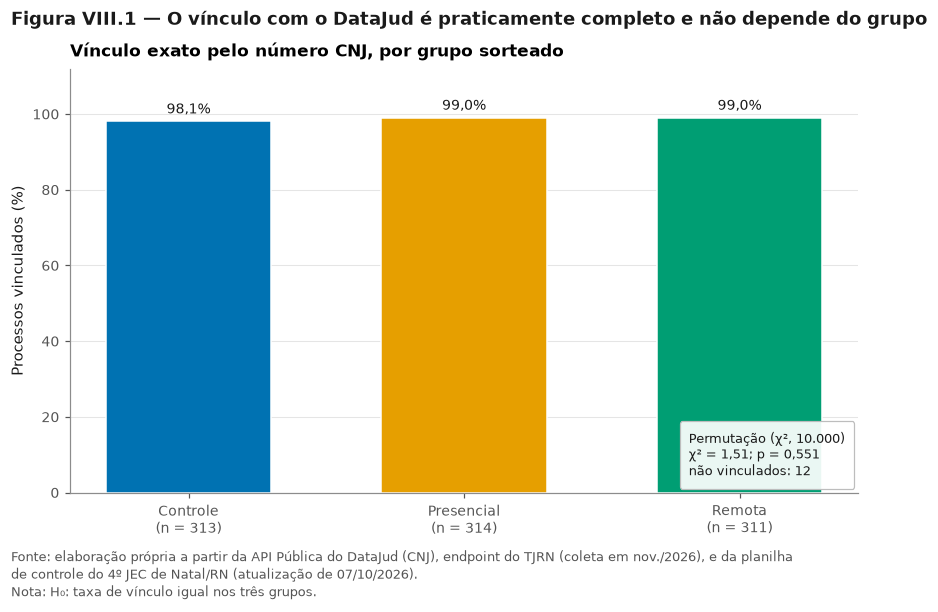

Tipo de registro,Registros,Números
"Juizado, com passagem pelo 4º JEC",926,926
Turma Recursal (recurso inominado),134,134
Outro órgão (sem passagem pelo 4º JEC),6,6


Processo,Grupo,Desfecho (planilha),Distribuição,Origem externa,Registros,Registros encontrados (grau e órgão)
0808292-43.2025.8.20.5300,Controle,Sem mérito,06/01/2026,Sim,1,G1 4709
0800198-87.2026.8.20.5004,Controle,Sem mérito,10/01/2026,Não,0,—
0803118-34.2026.8.20.5004,Remota,Mérito,02/03/2026,Não,0,—
0807174-13.2026.8.20.5004,Controle,Mérito,27/04/2026,Não,0,—
0807739-74.2026.8.20.5004,Presencial,Ativo,05/05/2026,Não,0,—
0808165-86.2026.8.20.5004,Remota,Redistribuição,11/05/2026,Não,1,G1 4726
0803458-60.2026.8.20.5300,Presencial,Redistribuição,12/05/2026,Sim,1,G1 4709
0808692-38.2026.8.20.5004,Controle,Mérito,18/05/2026,Não,0,—
0809595-73.2026.8.20.5004,Controle,Mérito,29/05/2026,Não,0,—
0812434-71.2026.8.20.5004,Remota,Redistribuição,09/07/2026,Não,0,—


In [36]:
dj_por_num = defaultdict(list)
for x in dj_regs:
    dj_por_num[x['numeroProcesso']].append(x)


def dj_passou_4jec(x):
    return any(dj_oj(m) == COD_4JEC for m in x.get('movimentos') or [])


def dj_tipo_registro(x):
    if x.get('grau') == 'TR':
        return 'Turma Recursal (recurso inominado)'
    if x.get('grau') == 'JE' and dj_passou_4jec(x):
        return 'Juizado, com passagem pelo 4º JEC'
    return 'Outro órgão (sem passagem pelo 4º JEC)'


dj = dados.copy()
dj['numero'] = dj['processo'].astype(str).str.replace(r'\D', '', regex=True)
dj['consultado'] = dj['numero'].isin(dj_consultados)
dj['n_registros'] = dj['numero'].map(lambda n: len(dj_por_num.get(n, [])))
dj['encontrado'] = dj['n_registros'] > 0
_principal = {}
for n, lst in dj_por_num.items():
    cand = [x for x in lst if dj_tipo_registro(x).startswith('Juizado')]
    if cand:
        _principal[n] = max(cand, key=lambda x: len(x.get('movimentos') or []))
dj['vinculado'] = dj['numero'].isin(_principal)
dj['n_principais'] = dj['numero'].map(lambda n: sum(dj_tipo_registro(x).startswith('Juizado') for x in dj_por_num.get(n, [])))
dj['tem_recurso'] = dj['numero'].map(lambda n: any(x.get('grau') == 'TR' for x in dj_por_num.get(n, [])))
dj_c = dj[dj['consultado']].copy()

# variáveis derivadas do registro principal
_der = pd.DataFrame([dj_derivar(_principal[n], COD_4JEC, desde=d0 - pd.Timedelta(days=30))
                     for n, d0 in zip(dj_c.loc[dj_c.vinculado, 'numero'], dj_c.loc[dj_c.vinculado, 'dt_distribuicao'])],
                    index=dj_c.index[dj_c.vinculado])
dj_c = dj_c.join(_der.add_prefix('dj_'))

# tabela de vínculo por grupo
vinc = (dj_c.groupby('grupo', observed=True)
        .agg(Consultados=('numero', 'size'), Encontrados=('encontrado', 'sum'), Vinculados=('vinculado', 'sum'))
        .reindex(ORDEM_GRUPO))
vinc.loc['Total'] = vinc.sum()
vinc['Vínculo (%)'] = vinc['Vinculados'] / vinc['Consultados']
tabela(vinc.rename_axis('Grupo'), 'dj_vinculo', 'Quase todos os processos da planilha são encontrados no DataJud, com a mesma taxa nos três grupos',
       secao='8.3.1', fonte=FONTE_DJ, formatos={'Vínculo (%)': 'pct'},
       nota='Encontrado = algum registro com o número; vinculado = registro de juizado com movimento no 4º JEC (registro principal).'
            + ('' if DJ_AMOSTRA_COMPLETA else f' Coleta parcial: {len(dj_lotes_feitos)} de {len(dj_lotes)} lotes.'))


def dj_perm_chi2(x, g, B=10000, rng=None):
    """Teste de permutação da estatística qui-quadrado de independência (x binária × g categórica)."""
    rng = rng or np.random.default_rng(SEMENTE)
    x, g = np.asarray(x).astype(int), np.asarray(g)
    cats = np.unique(g)
    def chi(gg):
        tab = np.array([[np.sum((gg == c) & (x == v)) for v in (0, 1)] for c in cats], float)
        esp = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / tab.sum()
        with np.errstate(divide='ignore', invalid='ignore'):
            return np.nansum(np.where(esp > 0, (tab - esp) ** 2 / esp, 0))
    obs = chi(g)
    perm = np.array([chi(rng.permutation(g)) for _ in range(B)])
    return obs, (1 + np.sum(perm >= obs - 1e-12)) / (B + 1)


chi_v, p_v = dj_perm_chi2(dj_c['vinculado'], dj_c['grupo'].astype(str))
fig, ax = plt.subplots(figsize=(8, 4.8))
vv = vinc.loc[ORDEM_GRUPO]
barras_verticais(ax, ORDEM_GRUPO, 100 * vv['Vínculo (%)'], cores=CORES_GRUPO, ns=vv['Consultados'],
                 fmt=lambda v: pct_br(v / 100), ylabel='Processos vinculados (%)', ymax=112)
ax.set_title('Vínculo exato pelo número CNJ, por grupo sorteado')
anotar_teste(ax, texto_teste('Permutação (χ², 10.000)', f'χ² = {fmt_br(chi_v, 2)}', p_v,
                             f'não vinculados: {fmt_int((~dj_c.vinculado).sum())}'), loc='lower right')
figura(fig, 'dj_vinculo', 'O vínculo com o DataJud é praticamente completo e não depende do grupo', secao='8.3.1', fonte=FONTE_DJ,
       nota='H₀: taxa de vínculo igual nos três grupos.')

# composição dos registros
comp = Counter(dj_tipo_registro(x) for n in dj_c['numero'] for x in dj_por_num.get(n, []))
comp_tab = pd.DataFrame({'Registros': pd.Series(comp)}).rename_axis('Tipo de registro')
comp_tab['Números'] = [sum(any(dj_tipo_registro(x) == t for x in dj_por_num.get(n, [])) for n in dj_c['numero'])
                       for t in comp_tab.index]
tabela(comp_tab.sort_values('Registros', ascending=False), 'dj_registros',
       'Um número, vários registros: o recurso na Turma Recursal e a origem em outro órgão são o mesmo processo em outra instância',
       secao='8.3.1', fonte=FONTE_DJ,
       nota=f'Números com mais de um registro principal (duplicidade no índice): {fmt_int((dj_c.n_principais > 1).sum())}. '
            f'Números com recurso inominado (registro TR): {fmt_int(dj_c.tem_recurso.sum())}.')
nv = dj_c[~dj_c['vinculado']]
tabela(nv[['processo', 'grupo', 'tipo_desfecho', 'dt_distribuicao', 'origem_externa', 'n_registros']].assign(
    registros=nv['numero'].map(lambda n: '; '.join(sorted({f"{x.get('grau')} {x['orgaoJulgador'].get('codigo')}" for x in dj_por_num.get(n, [])})) or '—'))
    .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'tipo_desfecho': 'Desfecho (planilha)', 'dt_distribuicao': 'Distribuição',
                     'origem_externa': 'Origem externa', 'n_registros': 'Registros', 'registros': 'Registros encontrados (grau e órgão)'})
    .reset_index(drop=True),
    'dj_nao_vinculados', 'Processos da planilha sem registro de juizado com passagem pelo 4º JEC', secao='8.3.1', fonte=FONTE_DJ,
    formatos={'Registros': 'int'})

**Leitura.** Dos 938 números da planilha, **930 (99,1%)** foram encontrados na API e **926 (98,7%)** têm o registro principal (juizado, com passagem pelo 4º JEC). A taxa é praticamente igual nos três grupos (98,1%, 99,0% e 99,0%; teste de permutação sem evidência de diferença), de modo que o vínculo **não introduz viés diferencial** nas comparações das seções seguintes. Os 12 não vinculados são de dois tipos: (i) **oito números não encontrados** em nenhum grau (seis já encerrados na planilha e dois ativos): o índice público não é exaustivo (há processos sob sigilo e registros não enviados pelo tribunal); (ii) **quatro números encontrados só em outro órgão** (justiça comum, G1), dois deles de **origem externa** (numeração 5300, vindos de outro órgão), cuja passagem pelo 4º JEC não aparece no registro daquele número.

O "mesmo número em outra instância" é frequente e foi tratado sem duplicar: 134 processos (14%) têm também um registro na **Turma Recursal** (recurso inominado). Nenhum número tem mais de um registro de juizado no 4º JEC, e o cumprimento de sentença aparece no **mesmo** registro, por evolução de classe (436 → 156), e não como processo novo.

### 8.3.2 Concordância processo a processo

Para cada processo vinculado comparam-se cinco informações da planilha com a reconstrução pelas regras de 8.2, **na mesma data de corte (07/10/2026)**:

1. **data de distribuição**: `dt_distribuicao` × 1º movimento no 4º JEC (e × `dataAjuizamento`);
2. **data da sentença**: `dt_sentenca` × data do julgamento (R1 e R2), entre os que têm sentença nas duas fontes;
3. **tipo de desfecho** em 07/10/2026 (Homologação, Mérito, Sem mérito, Redistribuição, Ativo);
4. **AC realizada** (`ac_realizada`) × audiência de conciliação "realizada" até 07/10/2026;
5. **redistribuição** (saída da unidade) até 07/10/2026.

**Medidas.** Para as datas, a diferença em dias (DataJud − planilha) e o percentual de coincidência exata. Para as categorias, a **concordância observada** e o **kappa de Cohen**, κ = (p_o − p_e)/(1 − p_e), que desconta a concordância esperada por acaso; IC 95% por *bootstrap* (2.000 reamostras de processos). Leitura usual de κ: > 0,80 quase perfeita; 0,61–0,80 substancial (LANDIS; KOCH, 1977).

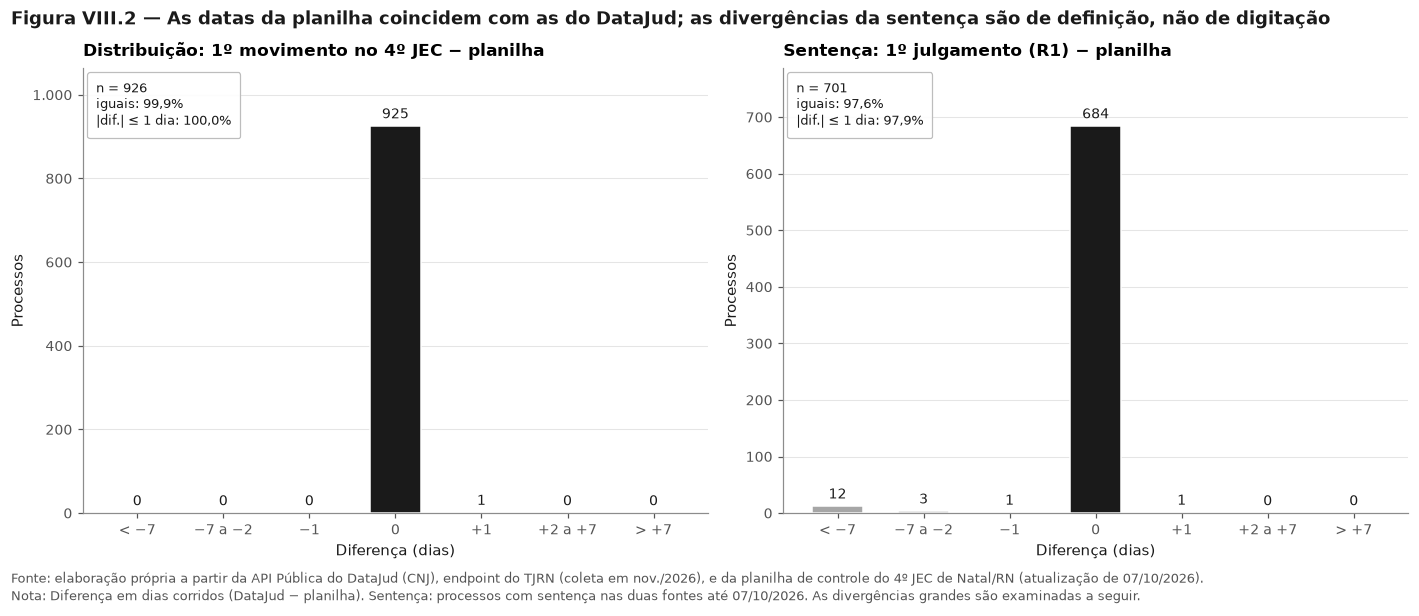

Comparação,n,Iguais,|dif.| ≤ 1 dia,Mediana da dif. (dias)
Distribuição × 1º movimento no 4º JEC,926,"99,9%","100,0%",0
Distribuição × dataAjuizamento,926,"96,4%","97,2%",0
Sentença × julgamento (R1),701,"97,6%","97,9%",0
Sentença × julgamento (R2),701,"99,1%","99,3%",0


In [37]:
CORTE_PLANILHA = DATA_CORTE
v = dj_c[dj_c['vinculado']].copy()
for regra in ('R1', 'R2'):
    _res = [dj_desfecho_em({k[3:]: r[k] for k in r.index if k.startswith('dj_')}, CORTE_PLANILHA, regra) for _, r in v.iterrows()]
    v[f'dj_desf_{regra}'] = [a for a, _ in _res]
    v[f'dj_data_{regra}'] = pd.to_datetime([b for _, b in _res])
v['tipo_pl'] = v['tipo_desfecho'].astype(str)
v['dif_dist'] = (v['dj_entrada'].dt.normalize() - v['dt_distribuicao']).dt.days
v['dif_ajuiz'] = (v['dj_ajuizamento'] - v['dt_distribuicao']).dt.days
_sent_pl = v['tipo_pl'].isin(['Homologação', 'Mérito', 'Sem mérito'])
for regra in ('R1', 'R2'):
    v[f'dif_sent_{regra}'] = np.where(_sent_pl & v[f'dj_desf_{regra}'].isin(['Homologação', 'Mérito', 'Sem mérito']),
                                      (v[f'dj_data_{regra}'] - v['dt_sentenca']).dt.days, np.nan)
v['ac_dj'] = v['dj_ac_realizada_dt'].notna() & (v['dj_ac_realizada_dt'].dt.normalize() <= CORTE_PLANILHA)
v['red_pl'] = v['tipo_pl'] == 'Redistribuição'
v['red_dj'] = v['dj_desf_R1'] == 'Redistribuição'

FAIXAS_DIF = ['< −7', '−7 a −2', '−1', '0', '+1', '+2 a +7', '> +7']


def dj_faixa(d):
    d = pd.Series(d).dropna()
    cat = pd.cut(d, [-1e9, -8, -2, -1, 0, 1, 7, 1e9], right=True, labels=FAIXAS_DIF)
    return cat.value_counts().reindex(FAIXAS_DIF, fill_value=0)


rng_k = np.random.default_rng(SEMENTE + 81)


def dj_kappa(a, b, B=2000):
    a, b = np.asarray(a, dtype=str), np.asarray(b, dtype=str)
    k = cohen_kappa_score(a, b)
    idx = [rng_k.integers(0, len(a), len(a)) for _ in range(B)]
    bs = np.array([cohen_kappa_score(a[i], b[i]) if len(set(a[i]) | set(b[i])) > 1 else np.nan for i in idx])
    return k, np.nanpercentile(bs, 2.5), np.nanpercentile(bs, 97.5), np.mean(a == b)


# ---- datas: distribuição e sentença
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (col, tit, n_) in zip(axs, [('dif_dist', 'Distribuição: 1º movimento no 4º JEC − planilha', None),
                                     ('dif_sent_R1', 'Sentença: 1º julgamento (R1) − planilha', None)]):
    fx = dj_faixa(v[col])
    cores = [TINTA if f == '0' else CINZA for f in FAIXAS_DIF]
    barras_verticais(ax, FAIXAS_DIF, fx.values, cores=cores, ylabel='Processos', xlabel='Diferença (dias)')
    ax.set_title(tit)
    d = v[col].dropna()
    anotar_teste(ax, texto_teste(f'n = {fmt_int(len(d))}', f'iguais: {pct_br((d == 0).mean())}',
                                 extra=f'|dif.| ≤ 1 dia: {pct_br((d.abs() <= 1).mean())}'), loc='upper left')
figura(fig, 'dj_datas', 'As datas da planilha coincidem com as do DataJud; as divergências da sentença são de definição, não de digitação',
       secao='8.3.2', fonte=FONTE_DJ, nota='Diferença em dias corridos (DataJud − planilha). Sentença: processos com sentença '
       'nas duas fontes até 07/10/2026. As divergências grandes são examinadas a seguir.')

datas_tab = pd.DataFrame([
    {'Comparação': 'Distribuição × 1º movimento no 4º JEC', 'n': v['dif_dist'].notna().sum(), 'Iguais': (v['dif_dist'] == 0).mean(),
     '|dif.| ≤ 1 dia': (v['dif_dist'].abs() <= 1).mean(), 'Mediana da dif. (dias)': v['dif_dist'].median()},
    {'Comparação': 'Distribuição × dataAjuizamento', 'n': v['dif_ajuiz'].notna().sum(), 'Iguais': (v['dif_ajuiz'] == 0).mean(),
     '|dif.| ≤ 1 dia': (v['dif_ajuiz'].abs() <= 1).mean(), 'Mediana da dif. (dias)': v['dif_ajuiz'].median()},
] + [{'Comparação': f'Sentença × julgamento ({regra})', 'n': v[f'dif_sent_{regra}'].notna().sum(),
      'Iguais': (v[f'dif_sent_{regra}'].dropna() == 0).mean(), '|dif.| ≤ 1 dia': (v[f'dif_sent_{regra}'].dropna().abs() <= 1).mean(),
      'Mediana da dif. (dias)': v[f'dif_sent_{regra}'].median()} for regra in ('R1', 'R2')])
tabela(datas_tab, 'dj_datas', 'Concordância das datas: planilha × DataJud', secao='8.3.2', fonte=FONTE_DJ,
       formatos={'Iguais': 'pct', '|dif.| ≤ 1 dia': 'pct', 'Mediana da dif. (dias)': 0, 'n': 'int'},
       nota='R1 = 1º julgamento; R2 = acordo homologado depois da sentença prevalece (8.2).')

**Leitura.** A **data de distribuição** da planilha é, em 99,9% dos casos, o dia do 1º movimento no 4º JEC; a diferença para `dataAjuizamento` (96,4% iguais) aparece só nos processos que chegaram de outro órgão ou foram redistribuídos para o 4º JEC: a planilha mede, corretamente, a entrada **na unidade**, que é o tempo zero adequado ao experimento. A **data da sentença** coincide em **97,6%** dos casos com o 1º julgamento (R1) e em **99,1%** com a regra R2. A diferença entre as duas regras não é erro de digitação: quando um acordo é homologado **depois** da sentença de mérito (no cumprimento de sentença ou na pendência do recurso), a planilha registra a homologação, com a data dela. Isso tem uma consequência para a Parte IV: nesses poucos processos (11), o "tempo até a sentença" da planilha é, na verdade, o tempo até o **acordo posterior**, maior que o tempo até a primeira sentença. O efeito sobre os resultados é desprezível (a seção 8.5 refaz as análises pela R1), mas a definição do evento deve ser explicitada.

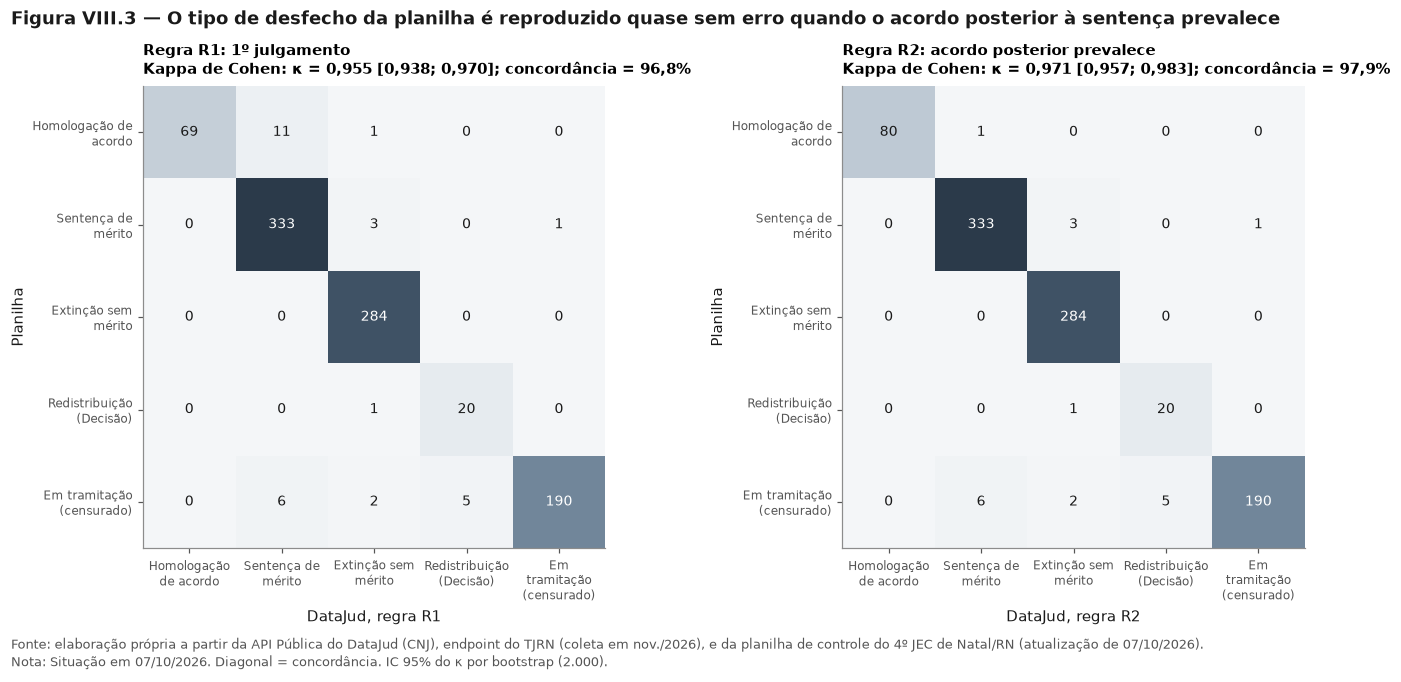

processo,grupo,Planilha,Data (planilha),DataJud R1,Data R1,DataJud R2,Data R2,Código do 1º julgamento
0812353-25.2026.8.20.5004,Remota,Ativo,–,Redistribuição,04/08/2026,Redistribuição,04/08/2026,–
0821262-90.2025.8.20.5004,Presencial,Ativo,–,Redistribuição,24/07/2026,Redistribuição,24/07/2026,–
0812022-43.2026.8.20.5004,Controle,Ativo,–,Redistribuição,02/10/2026,Redistribuição,02/10/2026,–
0804094-41.2026.8.20.5004,Remota,Ativo,–,Redistribuição,11/09/2026,Redistribuição,11/09/2026,–
0812008-59.2026.8.20.5004,Presencial,Ativo,–,Sem mérito,06/07/2026,Sem mérito,06/07/2026,459 Ausência de pressupostos processuais
0810834-15.2026.8.20.5004,Remota,Ativo,–,Mérito,03/10/2026,Mérito,03/10/2026,221 Procedência em Parte
0806960-22.2026.8.20.5004,Controle,Ativo,–,Redistribuição,04/08/2026,Redistribuição,04/08/2026,–
0807126-54.2026.8.20.5004,Remota,Ativo,–,Mérito,28/08/2026,Mérito,28/08/2026,220 Improcedência
0813453-15.2026.8.20.5004,Controle,Ativo,–,Mérito,03/10/2026,Mérito,03/10/2026,221 Procedência em Parte
0808315-67.2026.8.20.5004,Remota,Ativo,–,Sem mérito,13/05/2026,Sem mérito,13/05/2026,"460 Perempção, litispendência ou coisa julgada"


In [38]:
# ---- tipo de desfecho: matriz de confusão (R1 e R2)
ORD5 = ORDEM_DESFECHO
fig, axs = plt.subplots(1, 2, figsize=(13, 5.6))
kap_desf = {}
for ax, regra in zip(axs, ('R1', 'R2')):
    m = pd.crosstab(v['tipo_pl'], v[f'dj_desf_{regra}']).reindex(index=ORD5, columns=ORD5, fill_value=0)
    ax.imshow(m.values, cmap=SEQ, vmin=0, vmax=max(1, m.values.max()))
    for i in range(5):
        for j in range(5):
            val = m.values[i, j]
            ax.text(j, i, fmt_int(val), ha='center', va='center', fontsize=9,
                    color='white' if val > 0.55 * m.values.max() else TINTA)
    ax.set_xticks(range(5), [quebra(ROTULO_DESFECHO[c], 12) for c in ORD5], fontsize=8)
    ax.set_yticks(range(5), [quebra(ROTULO_DESFECHO[c], 14) for c in ORD5], fontsize=8)
    ax.set_xlabel(f'DataJud, regra {regra}')
    ax.set_ylabel('Planilha')
    ax.grid(False)
    k, lo, hi, po = dj_kappa(v['tipo_pl'], v[f'dj_desf_{regra}'])
    kap_desf[regra] = (k, lo, hi, po)
    ax.set_title(f'Regra {regra}: ' + ('1º julgamento' if regra == 'R1' else 'acordo posterior prevalece')
                 + f'\nKappa de Cohen: κ = {fmt_br(k, 3)} [{fmt_br(lo, 3)}; {fmt_br(hi, 3)}]; concordância = {pct_br(po)}', fontsize=10)
figura(fig, 'dj_desfecho_confusao', 'O tipo de desfecho da planilha é reproduzido quase sem erro quando o acordo posterior à sentença prevalece',
       secao='8.3.2', fonte=FONTE_DJ, nota='Situação em 07/10/2026. Diagonal = concordância. IC 95% do κ por bootstrap (2.000).')

div = v[v['tipo_pl'] != v['dj_desf_R2']]
tabela(div[['processo', 'grupo', 'tipo_pl', 'dt_sentenca', 'dj_desf_R1', 'dj_data_R1', 'dj_desf_R2', 'dj_data_R2', 'dj_sent_cod']]
       .rename(columns={'tipo_pl': 'Planilha', 'dt_sentenca': 'Data (planilha)', 'dj_desf_R1': 'DataJud R1', 'dj_data_R1': 'Data R1',
                        'dj_desf_R2': 'DataJud R2', 'dj_data_R2': 'Data R2', 'dj_sent_cod': 'Código do 1º julgamento'})
       .assign(**{'Código do 1º julgamento': lambda d: d['Código do 1º julgamento'].map(lambda c: '–' if pd.isna(c) else f'{int(c)} {dj_nome(c)}')})
       .sort_values('Planilha').reset_index(drop=True),
       'dj_divergencias', 'Processos em que a planilha e o DataJud (R2) discordam quanto ao desfecho em 07/10/2026', secao='8.3.2',
       fonte=FONTE_DJ, formatos={'Código do 1º julgamento': 'texto'})

**Leitura.** O tipo de desfecho concorda em **96,8%** dos processos pela R1 (κ = 0,955) e em **97,9%** pela R2 (κ = 0,971 [0,957; 0,983]): concordância **quase perfeita**. A matriz da R1 mostra onde estão as diferenças: 11 "Homologações" da planilha são, no DataJud, sentenças de mérito seguidas de acordo homologado (a convenção descrita acima); com a R2, resta uma.

As divergências que sobram (tabela acima) são de três naturezas:

1. **Atraso de alimentação da planilha**: 13 processos marcados como "Ativo" em 07/10 já tinham sentença ou saída no DataJud, várias com data muito próxima do corte (quatro sentenças de 03/10/2026, um sábado; outras de maio a agosto; saídas de julho a outubro). A planilha, alimentada à mão, estava alguns dias atrasada; o efeito é censurar como ativos processos já encerrados (corrigido na extensão de 8.4).
2. **Mérito na planilha × extinção sem mérito no DataJud** (três casos: abandono da causa, ausência de pressupostos, inadmissibilidade do rito): diferença de classificação jurídica do mesmo ato, ou lançamento do código TPU errado.
3. Casos isolados: um "Mérito" sem nenhum julgamento lançado no DataJud; uma "Redistribuição" que, no DataJud, é extinção por inadmissibilidade do procedimento seguida de envio a outro órgão; e uma homologação lançada pela Turma Recursal (fora da unidade).

Nenhuma dessas divergências se concentra num grupo: elas não ameaçam a comparação entre os ritos.

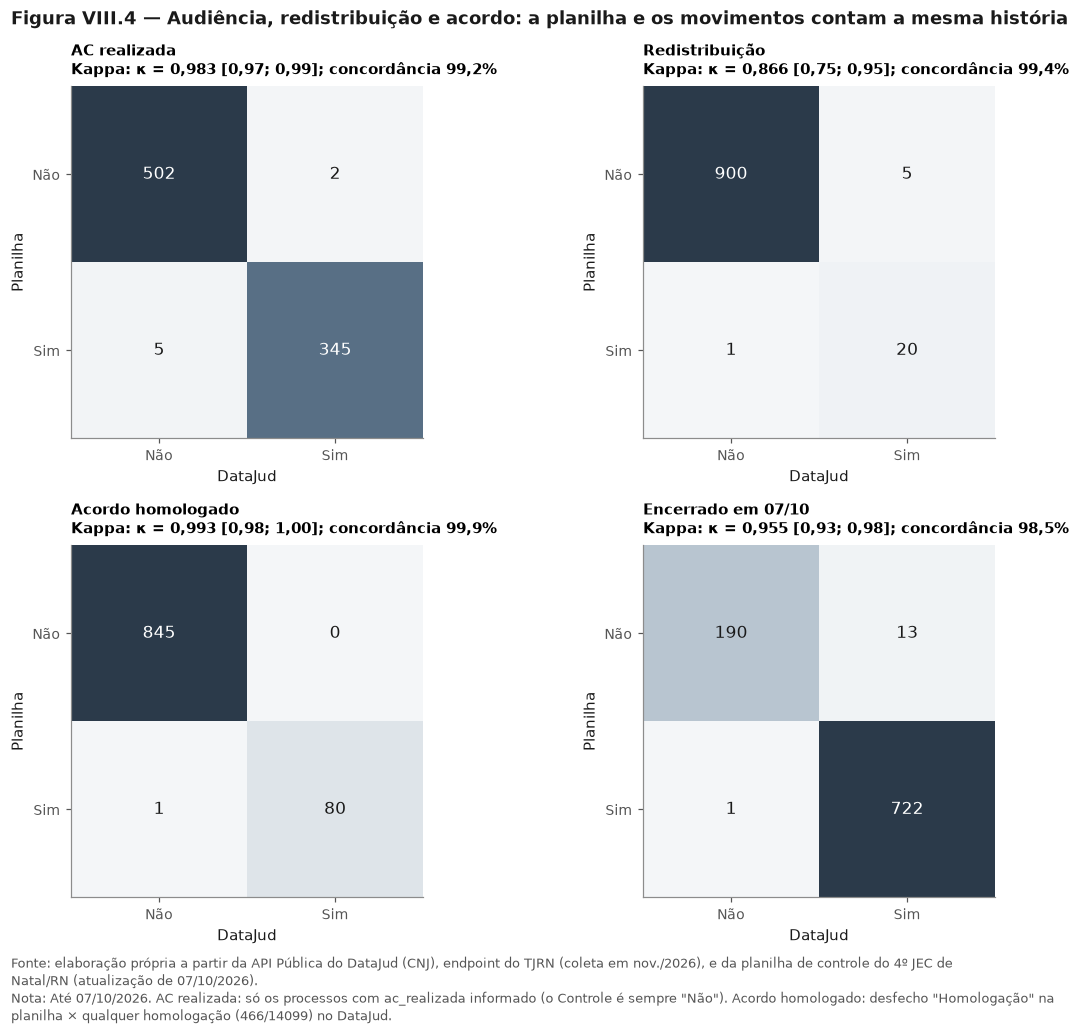

Variável,n,Concordância,κ,IC 95% inf.,IC 95% sup.,Só na planilha,Só no DataJud
Tipo de desfecho (R2),926,"97,9%","0,971","0,957","0,983",–,–
Tipo de desfecho (R1),926,"96,8%","0,955","0,938","0,970",–,–
AC realizada,854,"99,2%","0,983","0,969","0,993",5,2
Redistribuição,926,"99,4%","0,866","0,746","0,953",1,5
Acordo homologado,926,"99,9%","0,993","0,978","1,000",1,0
Encerrado em 07/10,926,"98,5%","0,955","0,930","0,977",1,13


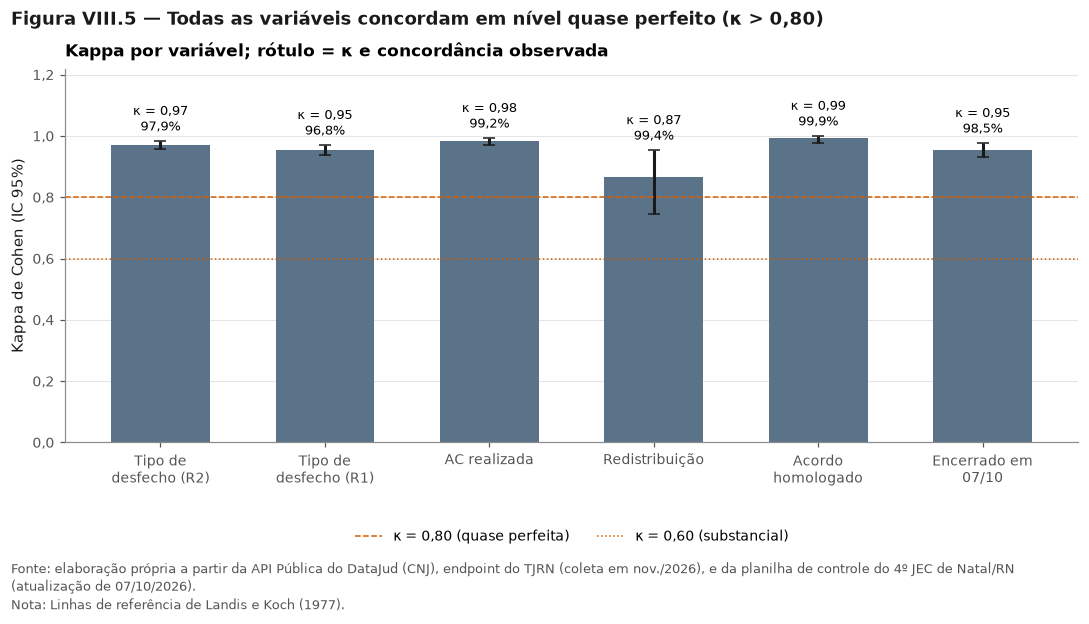

In [39]:
# ---- AC realizada, redistribuição e acordo: concordância e kappa
v_ac = v[v['ac_realizada'].notna()].copy()
v['acordo_dj'] = v['dj_homolog_dt'].notna() & (v['dj_homolog_dt'].dt.normalize() <= CORTE_PLANILHA)
comparacoes = {
    'AC realizada': (v_ac['ac_realizada'].astype(bool), v_ac['ac_dj']),
    'Redistribuição': (v['red_pl'], v['red_dj']),
    'Acordo homologado': (v['tipo_pl'] == 'Homologação', v['acordo_dj']),
    'Encerrado em 07/10': (v['tipo_pl'] != 'Ativo', v['dj_desf_R2'] != 'Ativo'),
}
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5))
linhas_k = []
for ax, (nome, (a, b)) in zip(axs.flat, comparacoes.items()):
    a, b = pd.Series(a).astype(bool).values, pd.Series(b).astype(bool).values
    m = pd.crosstab(pd.Categorical(a, [False, True]), pd.Categorical(b, [False, True]), dropna=False).values
    ax.imshow(m, cmap=SEQ, vmin=0, vmax=max(1, m.max()))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, fmt_int(m[i, j]), ha='center', va='center', fontsize=11,
                    color='white' if m[i, j] > 0.55 * m.max() else TINTA)
    ax.set_xticks([0, 1], ['Não', 'Sim'])
    ax.set_yticks([0, 1], ['Não', 'Sim'])
    ax.set_xlabel('DataJud')
    ax.set_ylabel('Planilha')
    ax.grid(False)
    k, lo, hi, po = dj_kappa(a, b)
    ax.set_title(f'{nome}\nKappa: κ = {fmt_br(k, 3)} [{fmt_br(lo, 2)}; {fmt_br(hi, 2)}]; concordância {pct_br(po)}', fontsize=10)
    linhas_k.append({'Variável': nome, 'n': len(a), 'Concordância': po, 'κ': k, 'IC 95% inf.': lo, 'IC 95% sup.': hi,
                     'Só na planilha': int(m[1, 0]), 'Só no DataJud': int(m[0, 1])})
figura(fig, 'dj_binarias', 'Audiência, redistribuição e acordo: a planilha e os movimentos contam a mesma história', secao='8.3.2',
       fonte=FONTE_DJ, nota='Até 07/10/2026. AC realizada: só os processos com ac_realizada informado (o Controle é sempre "Não"). '
       'Acordo homologado: desfecho "Homologação" na planilha × qualquer homologação (466/14099) no DataJud.')
for regra in ('R1', 'R2'):
    k, lo, hi, po = kap_desf[regra]
    linhas_k.insert(0, {'Variável': f'Tipo de desfecho ({regra})', 'n': len(v), 'Concordância': po, 'κ': k, 'IC 95% inf.': lo,
                        'IC 95% sup.': hi, 'Só na planilha': np.nan, 'Só no DataJud': np.nan})
kap_tab = pd.DataFrame(linhas_k)
tabela(kap_tab, 'dj_concordancia', 'Resumo da concordância planilha × DataJud (kappa de Cohen, IC 95% bootstrap)', secao='8.3.2',
       fonte=FONTE_DJ, formatos={'Concordância': 'pct', 'κ': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3, 'n': 'int',
                                 'Só na planilha': 'int', 'Só no DataJud': 'int'})

fig, ax = plt.subplots(figsize=(10, 5))
xk = np.arange(len(kap_tab))
ax.bar(xk, kap_tab['κ'], color='#5B7389', width=0.6)
ax.errorbar(xk, kap_tab['κ'], yerr=[kap_tab['κ'] - kap_tab['IC 95% inf.'], kap_tab['IC 95% sup.'] - kap_tab['κ']], fmt='none',
            ecolor=TINTA, capsize=4)
for xi, (k, po, hi_) in enumerate(zip(kap_tab['κ'], kap_tab['Concordância'], kap_tab['IC 95% sup.'])):
    ax.annotate(f'κ = {fmt_br(k, 2)}\n{pct_br(po)}', (xi, hi_ + 0.02), ha='center', va='bottom', fontsize=8.5)
ax.axhline(0.8, color=DESTAQUE, ls='--', lw=1, label='κ = 0,80 (quase perfeita)')
ax.axhline(0.6, color=DESTAQUE, ls=':', lw=1, label='κ = 0,60 (substancial)')
legenda_abaixo(ax, ncol=2, dy=-0.2)
ax.set_xticks(xk, [quebra(t, 14) for t in kap_tab['Variável']])
ax.set_ylim(0, 1.22)
ax.set_ylabel('Kappa de Cohen (IC 95%)')
ax.set_title('Kappa por variável; rótulo = κ e concordância observada')
ax.grid(axis='x', visible=False)
figura(fig, 'dj_kappa', ('Todas as variáveis concordam em nível quase perfeito (κ > 0,80)' if (kap_tab['κ'] > 0.8).all()
                        else 'Todas as variáveis concordam além do acaso; a maioria em nível quase perfeito'), secao='8.3.2',
       fonte=FONTE_DJ, nota='Linhas de referência de Landis e Koch (1977).')

**Leitura.** Todas as variáveis concordam em nível **quase perfeito** (κ > 0,80), inclusive as que só a planilha distinguia: a **AC realizada** (κ = 0,983; 345 audiências realizadas nas duas fontes, cinco só na planilha e duas só no DataJud) e o **acordo homologado** (κ = 0,993). A **redistribuição** tem o κ mais baixo (0,866), por ser rara (21 casos): cinco saídas registradas no DataJud não constavam da planilha em 07/10, de novo pelo atraso de alimentação. A variável "encerrado em 07/10" resume o padrão: só **uma** discordância no sentido "encerrado na planilha, ativo no DataJud" e **13** no sentido oposto, isto é, a planilha **subestima** levemente os encerramentos perto do corte, mas não inventa nenhum.

**Conclusão de VIII-A.** A planilha é uma medida **válida** das variáveis do experimento. O principal problema que ela tem não é de digitação, e sim de **definição** (o acordo posterior à sentença substitui a sentença) e de **defasagem** perto da data de corte. As duas coisas são pequenas e não diferenciais entre os grupos.

### 8.3.3 As sentenças em fim de semana

A auditoria (A16; seção 2.5.4) encontrou **135 sentenças datadas em sábado ou domingo** na planilha (18,4% das sentenças), o que levantou a suspeita de digitação errada. O DataJud permite separar duas hipóteses: (a) a data da planilha está errada (o ato é de um dia útil); (b) o ato foi mesmo **registrado** no fim de semana. O movimento de julgamento no PJe é gerado quando o magistrado **assina eletronicamente** a sentença, e é essa data e hora que o DataJud reproduz; a publicação no Diário (movimentos 1061/92) é posterior e cai em dia útil. Se as datas de fim de semana da planilha coincidem com as do movimento, a planilha registrou a data da **assinatura**, e o fim de semana é real.

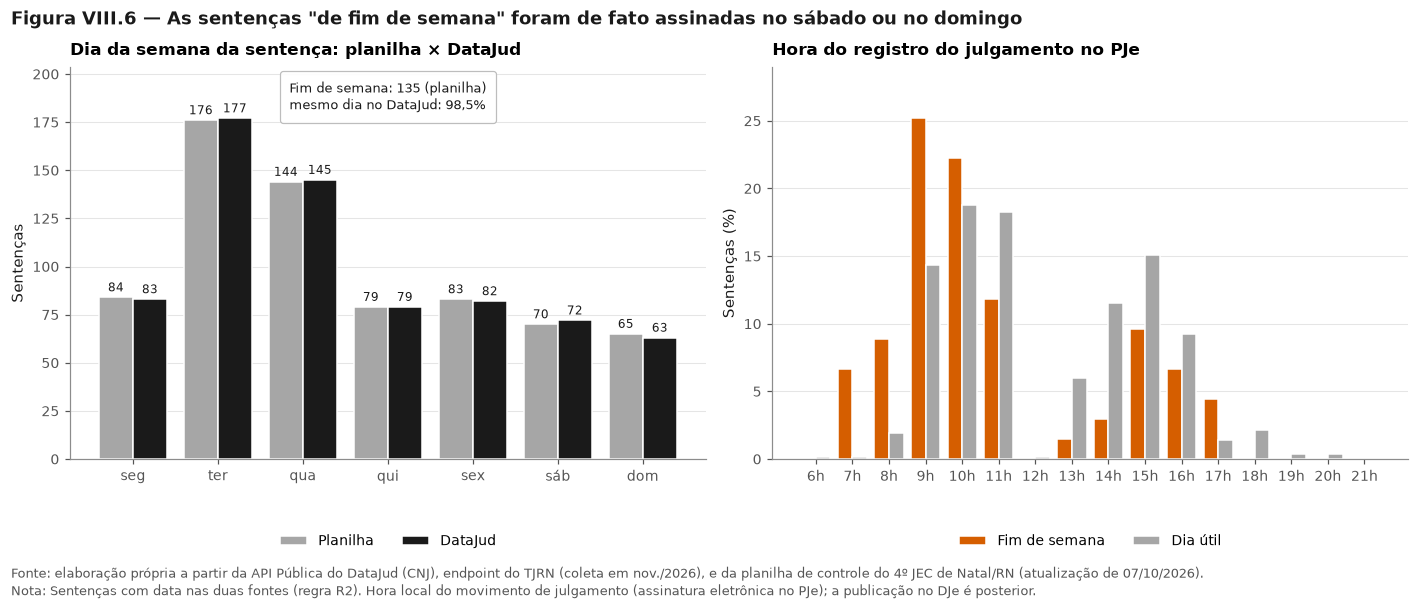

In [40]:
DIAS_PT = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
fs = v[_sent_pl & v['dif_sent_R2'].notna()].copy()
fs['dia_pl'] = fs['dt_sentenca'].dt.dayofweek
fs['dia_dj'] = fs['dj_data_R2'].dt.dayofweek
_dt_julg = np.where(fs['dif_sent_R1'] == fs['dif_sent_R2'], fs['dj_sent_dt'], fs['dj_homolog_pos_dt'])
fs['hora_dj'] = pd.to_datetime(_dt_julg).hour
fs['fds_pl'] = fs['dia_pl'] >= 5
fds = fs[fs['fds_pl']]
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
tab_d = pd.DataFrame({'Planilha': fs['dia_pl'].value_counts().reindex(range(7), fill_value=0).values,
                      'DataJud': fs['dia_dj'].value_counts().reindex(range(7), fill_value=0).values}, index=DIAS_PT)
barras_agrupadas(axs[0], tab_d, cores={'Planilha': CINZA, 'DataJud': TINTA}, ylabel='Sentenças', rotular=True)
axs[0].set_title('Dia da semana da sentença: planilha × DataJud')
anotar_teste(axs[0], texto_teste(f'Fim de semana: {fmt_int(fds.shape[0])} (planilha)',
                                 f'mesmo dia no DataJud: {pct_br((fds["dif_sent_R2"] == 0).mean())}'), loc='upper center')
legenda_abaixo(axs[0], ncol=2)
hrs = fds['hora_dj'].value_counts().reindex(range(6, 22), fill_value=0)
hru = fs.loc[~fs['fds_pl'], 'hora_dj'].value_counts().reindex(range(6, 22), fill_value=0)
tab_h = pd.DataFrame({'Fim de semana': hrs.values / max(1, hrs.sum()), 'Dia útil': hru.values / max(1, hru.sum())},
                     index=[f'{h}h' for h in range(6, 22)])
barras_agrupadas(axs[1], 100 * tab_h, cores={'Fim de semana': DESTAQUE, 'Dia útil': CINZA}, ylabel='Sentenças (%)')
axs[1].set_title('Hora do registro do julgamento no PJe')
legenda_abaixo(axs[1], ncol=2)
figura(fig, 'dj_fim_semana', 'As sentenças "de fim de semana" foram de fato assinadas no sábado ou no domingo',
       secao='8.3.3', fonte=FONTE_DJ, nota='Sentenças com data nas duas fontes (regra R2). Hora local do movimento de julgamento '
       '(assinatura eletrônica no PJe); a publicação no DJe é posterior.')

**Leitura.** A suspeita da auditoria (A16) **não se confirma**. As **135 sentenças** datadas em sábado ou domingo na planilha estão no DataJud **no mesmo dia** em 98,5% dos casos, e a distribuição dos dias da semana é praticamente idêntica nas duas fontes (72 sábados e 63 domingos no DataJud). O movimento de julgamento é gerado quando o magistrado **assina eletronicamente** a sentença no PJe; a publicação no Diário vem depois, em dia útil. A hora do registro ajuda a ler o padrão: as sentenças de fim de semana concentram-se **de manhã** (7h às 11h), enquanto as de dia útil se dividem entre manhã e tarde, o perfil de quem despacha remotamente fora do expediente. As datas de fim de semana são, portanto, as datas **reais da assinatura**, e não erro de lançamento. O que a planilha registra é a data em que a sentença passou a existir nos autos; a "data de lançamento" e a "data de assinatura" coincidem no PJe.

Para o estudo, isso fecha a questão da seção 2.5.4 e da sensibilidade da seção 4.9: **nenhuma correção** das datas de fim de semana é necessária. Para a gestão, o dado é relevante por si: quase um quinto das sentenças do período foi assinado em fins de semana.

## 8.4 VIII-B — Seguimento estendido dos censurados

Em 07/10/2026, 206 processos estavam sem sentença (censurados) e 24 haviam saído da unidade. O DataJud foi consultado em novembro de 2026: os processos que receberam sentença depois de 07/10 passam a ter o **evento observado**, e os demais ficam censurados numa data posterior. Isso **reduz a censura** sem mudar o desenho, e permite verificar se as conclusões da Parte IV dependiam do seguimento curto (mínimo de 65 dias).

### 8.4.1 Até quando o DataJud é confiável?

O índice do DataJud é alimentado pelos tribunais **com defasagem**: um movimento lançado hoje no PJe pode levar dias para aparecer na API. Usar como corte a data da coleta trataria como "sem sentença" processos cuja sentença ainda não chegou ao índice, e enviesaria a extensão para baixo. Também não se usa a última atualização de cada registro como corte individual: os registros atualizados recentemente são justamente os que tiveram movimento (por exemplo, uma sentença), e a censura passaria a depender do desfecho (censura informativa). Adota-se, portanto, um **corte único**: o último dia em que o volume diário de movimentos ainda está no nível habitual, definido pela regra abaixo e conferido no gráfico.

**Regra.** Para cada dia útil depois de 07/10/2026, compara-se o número de movimentos dos processos da amostra com a mediana dos dias úteis das quatro semanas anteriores a 07/10; o corte é o último dia útil antes do primeiro dia em que o volume cai abaixo de **50%** desse nível e não se recupera.

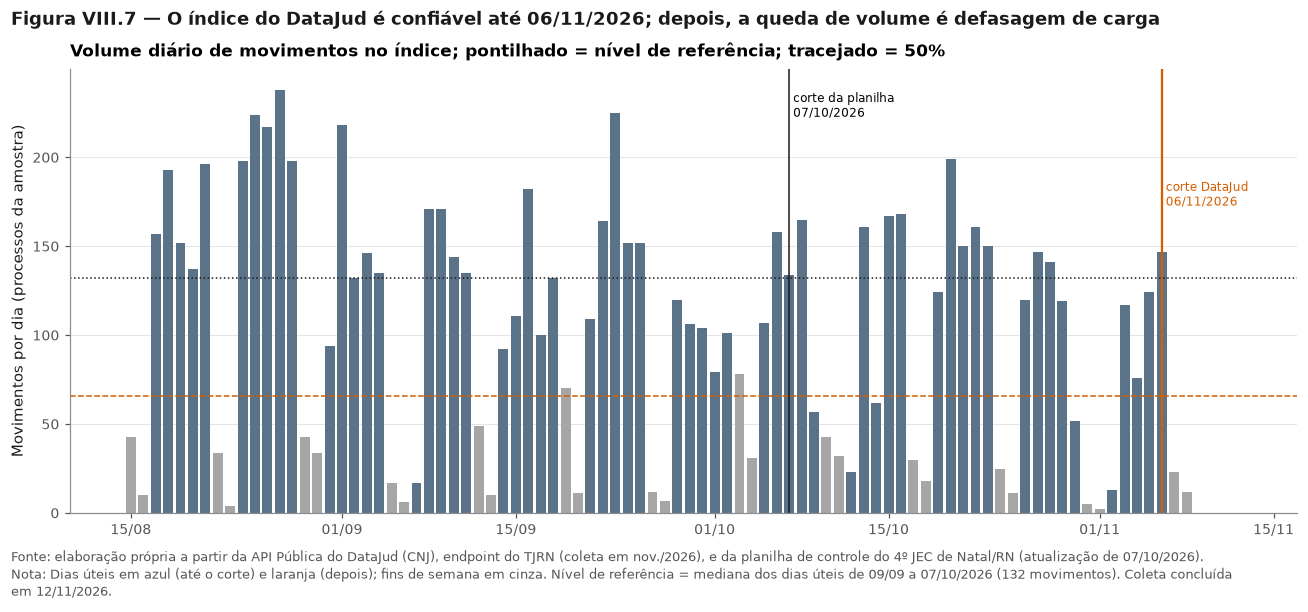

Corte confiável do DataJud (amostra): 2026-11-06 | 1º dia da queda: 2026-11-09 00:00:00


In [41]:
def dj_volume_diario(regs_iter, desde, ate):
    cont = Counter()
    for x in regs_iter:
        for m in x.get('movimentos') or []:
            d = str(m['dataHora'])[:10]
            if desde <= d <= ate:
                cont[d] += 1
    s = pd.Series(cont, dtype=float)
    s.index = pd.to_datetime(s.index)
    return s.reindex(pd.date_range(desde, ate), fill_value=0)


def dj_corte_confiavel(vol, ref_ini, ref_fim, limiar=0.5):
    uteis = vol[vol.index.dayofweek < 5]
    nivel = uteis[(uteis.index >= ref_ini) & (uteis.index <= ref_fim)].median()
    depois = uteis[uteis.index > ref_fim]
    baixo = depois < limiar * nivel
    # primeiro dia útil a partir do qual o volume fica abaixo do limiar até o fim da série
    queda = None
    for d in depois.index:
        if baixo.loc[d:].all():
            queda = d
            break
    corte = (depois.index[depois.index < queda].max() if queda is not None and (depois.index < queda).any()
             else depois.index.max())
    return corte, nivel, queda


_ate = DJ_DATA_COLETA.strftime('%Y-%m-%d')
vol_am = dj_volume_diario([_principal[n] for n in v['numero']], '2026-08-15', _ate)
DJ_CORTE, nivel_am, queda_am = dj_corte_confiavel(vol_am, DATA_CORTE - pd.Timedelta(days=28), DATA_CORTE)

fig, ax = plt.subplots(figsize=(12, 4.8))
cores_v = [CINZA if d.dayofweek >= 5 else ('#5B7389' if d <= DJ_CORTE else DESTAQUE) for d in vol_am.index]
ax.bar(vol_am.index, vol_am.values, color=cores_v, width=0.8)
ax.axhline(nivel_am, color=TINTA, ls=':', lw=1)
ax.axhline(0.5 * nivel_am, color=DESTAQUE, ls='--', lw=1)
ax.axvline(DATA_CORTE, color=TINTA, lw=1)
ax.axvline(DJ_CORTE, color=DESTAQUE, lw=1.5)
ax.text(DATA_CORTE, ax.get_ylim()[1] * 0.95, ' corte da planilha\n 07/10/2026', fontsize=8, va='top')
ax.text(DJ_CORTE, ax.get_ylim()[1] * 0.75, f' corte DataJud\n {DJ_CORTE:%d/%m/%Y}', fontsize=8, va='top', color=DESTAQUE)
ax.set_ylabel('Movimentos por dia (processos da amostra)')
ax.set_title('Volume diário de movimentos no índice; pontilhado = nível de referência; tracejado = 50%')
eixo_meses(ax, formato='dia')
figura(fig, 'dj_corte', f'O índice do DataJud é confiável até {DJ_CORTE:%d/%m/%Y}; depois, a queda de volume é defasagem de carga',
       secao='8.4.1', fonte=FONTE_DJ, nota=f'Dias úteis em azul (até o corte) e laranja (depois); fins de semana em cinza. Nível de '
       f'referência = mediana dos dias úteis de 09/09 a 07/10/2026 ({fmt_br(nivel_am, 0)} movimentos). Coleta concluída em {DJ_DATA_COLETA:%d/%m/%Y}.')
print('Corte confiável do DataJud (amostra):', DJ_CORTE.date(), '| 1º dia da queda:', queda_am)

**Leitura.** O volume diário de movimentos dos processos da amostra oscila, nos dias úteis, em torno do nível de referência até a primeira semana de novembro e cai a **zero a partir de 09/11/2026**, embora a coleta tenha terminado em 12/11. Essa queda abrupta não é a de um acervo que se encerra (que seria gradual): é a **defasagem de carga** do índice, cuja última atualização é de 09/11. O corte confiável adotado é **06/11/2026** (sexta-feira), o último dia útil com volume no nível habitual, um mês depois do corte da planilha.

### 8.4.2 Os censurados que receberam sentença depois de 07/10/2026

**Regra da extensão.** Os 708 processos com sentença e os 24 redistribuídos mantêm o tempo e o evento da planilha (a análise principal). Para os 206 censurados: se o DataJud registra o 1º julgamento (R1) até o corte confiável, o evento passa a 1 com o tempo até essa data; se registra a saída da unidade, o processo fica censurado na data da saída; caso contrário, fica censurado no corte do DataJud (ou em 07/10/2026, se o processo não foi vinculado ou não foi consultado). Nenhuma data da planilha é alterada.

Grupo,ainda sem sentença,não vinculado / não consultado,saída da unidade,sentença antes de 07/10 (omitida na planilha),sentença depois de 07/10,Censurados em 07/10
Controle,15,1,2,3,25,46
Presencial,35,2,1,2,34,74
Remota,59,0,2,3,22,86
Total,109,3,5,8,81,206


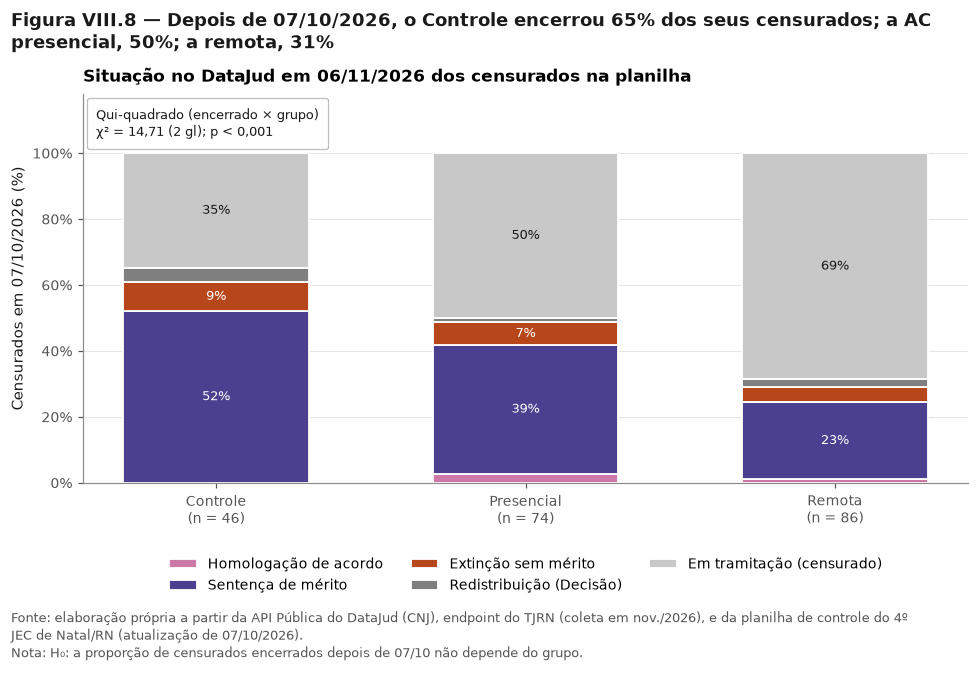

In [42]:
ext = dj[['processo', 'numero', 'grupo', 'dt_distribuicao', 'tempo', 'evento', 'evento_cr', 'tipo_desfecho', 'mes_distribuicao',
          'origem_externa']].copy()
ext = ext.join(v[['dj_sent_dt', 'dj_sent_tipo', 'dj_saida_dt']], how='left')
ext['T_ext'] = ext['tempo'].astype(float)
ext['E_ext'] = ext['evento'].astype(int)
ext['tipo_ext'] = ext['tipo_desfecho'].astype(str)
cens = ext['evento_cr'].astype(int) == 0
_vinc = ext.index.isin(v.index)
_sd = ext['dj_sent_dt'].dt.normalize()
_xd = ext['dj_saida_dt'].dt.normalize()
com_sent = cens & _sd.notna() & (_sd <= DJ_CORTE) & (_xd.isna() | (_sd < _xd))
com_saida = cens & ~com_sent & _xd.notna() & (_xd <= DJ_CORTE)
sem_nada = cens & ~com_sent & ~com_saida & _vinc
ext.loc[com_sent, 'T_ext'] = (_sd[com_sent] - ext.loc[com_sent, 'dt_distribuicao']).dt.days
ext.loc[com_sent, 'E_ext'] = 1
ext.loc[com_sent, 'tipo_ext'] = ext.loc[com_sent, 'dj_sent_tipo']
ext.loc[com_saida, 'T_ext'] = (_xd[com_saida] - ext.loc[com_saida, 'dt_distribuicao']).dt.days
ext.loc[com_saida, 'tipo_ext'] = 'Redistribuição'
ext.loc[sem_nada, 'T_ext'] = (DJ_CORTE - ext.loc[sem_nada, 'dt_distribuicao']).dt.days
ext['sit_ext'] = np.select([~cens, com_sent & (_sd <= DATA_CORTE), com_sent, com_saida, sem_nada],
                           ['sem alteração', 'sentença antes de 07/10 (omitida na planilha)', 'sentença depois de 07/10',
                            'saída da unidade', 'ainda sem sentença'], 'não vinculado / não consultado')

cens_tab = (ext[cens].groupby(['grupo', 'sit_ext'], observed=True).size().unstack(fill_value=0).reindex(ORDEM_GRUPO))
cens_tab['Censurados em 07/10'] = cens_tab.sum(axis=1)
cens_tab.loc['Total'] = cens_tab.sum()
tabela(cens_tab.rename_axis('Grupo'), 'dj_censurados', 'O que aconteceu, no DataJud, com os processos censurados em 07/10/2026',
       secao='8.4.2', fonte=FONTE_DJ, nota=f'Corte do DataJud: {DJ_CORTE:%d/%m/%Y}.')

tipos_ext = ext[cens].assign(cat=np.where(com_sent[cens], ext.loc[cens, 'tipo_ext'],
                                          np.where(com_saida[cens], 'Redistribuição', 'Ativo')))
tab_pc = pd.crosstab(tipos_ext['grupo'], tipos_ext['cat']).reindex(index=ORDEM_GRUPO, columns=ORDEM_DESFECHO, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 5.2))
barras_empilhadas(ax, tab_pc.div(tab_pc.sum(axis=1), axis=0), cores=CORES_DESFECHO, ns=tab_pc.sum(axis=1).values,
                  rotulos_serie=ROTULO_DESFECHO)
eixo_pct(ax)
ax.set_ylabel('Censurados em 07/10/2026 (%)')
ax.set_title(f'Situação no DataJud em {DJ_CORTE:%d/%m/%Y} dos censurados na planilha')
_tc = pd.crosstab(tipos_ext['grupo'], tipos_ext['cat'] != 'Ativo').reindex(ORDEM_GRUPO)
chi_c, p_c, gl_c, _ = stats.chi2_contingency(_tc.values)
anotar_teste(ax, texto_teste('Qui-quadrado (encerrado × grupo)', f'χ² = {fmt_br(chi_c, 2)} ({gl_c} gl)', p_c), loc='upper left')
ax.set_ylim(0, 1.18)
legenda_abaixo(ax, ncol=3)
_enc = 1 - tab_pc['Ativo'] / tab_pc.sum(axis=1)
figura(fig, 'dj_censurados', f"Depois de 07/10/2026, o Controle encerrou {pct_br(_enc['Controle'], 0)} dos seus censurados; "
       f"a AC presencial, {pct_br(_enc['Presencial'], 0)}; a remota, {pct_br(_enc['Remota'], 0)}",
       secao='8.4.2', fonte=FONTE_DJ, nota='H₀: a proporção de censurados encerrados depois de 07/10 não depende do grupo.')

**Leitura.** Dos 206 processos censurados em 07/10/2026, o DataJud registra até 06/11/2026: **81 sentenças posteriores a 07/10**, **8 sentenças anteriores a 07/10 que a planilha não registrou** (o atraso de alimentação de 8.3), 5 saídas da unidade e 109 processos ainda sem sentença; 3 não puderam ser seguidos (sem vínculo). A extensão **não é neutra entre os grupos**: o Controle encerrou cerca de dois terços dos seus censurados nesse mês, a AC presencial metade e a AC remota menos de um terço (χ² = 14,7; 2 gl; p < 0,001). Os processos com AC obrigatória que estavam pendentes em outubro continuavam, em sua maioria, pendentes um mês depois, o que é coerente com o atraso causado pela espera da audiência (Parte IV). A censura de 07/10 não escondia, portanto, uma "recuperação" dos grupos com AC; ao contrário, escondia parte da vantagem do Controle.

### 8.4.3 Kaplan-Meier, log-rank, Cox e RMST com o seguimento estendido

Refazem-se, com o seguimento estendido, as quatro análises centrais da Parte IV, com a **mesma especificação**: Kaplan-Meier por grupo; log-rank de 3 grupos (H₀: S_Controle = S_Presencial = S_Remota); Cox (b) com grupo + mês de distribuição (julho e agosto juntos) + origem externa (Efron); e diferenças de RMST até 180 dias com IC por *bootstrap* estratificado por grupo (2.000 reamostras). As mesmas funções são aplicadas à base original, para que a comparação seja entre estimativas calculadas do mesmo modo (elas reproduzem os números da Parte IV).

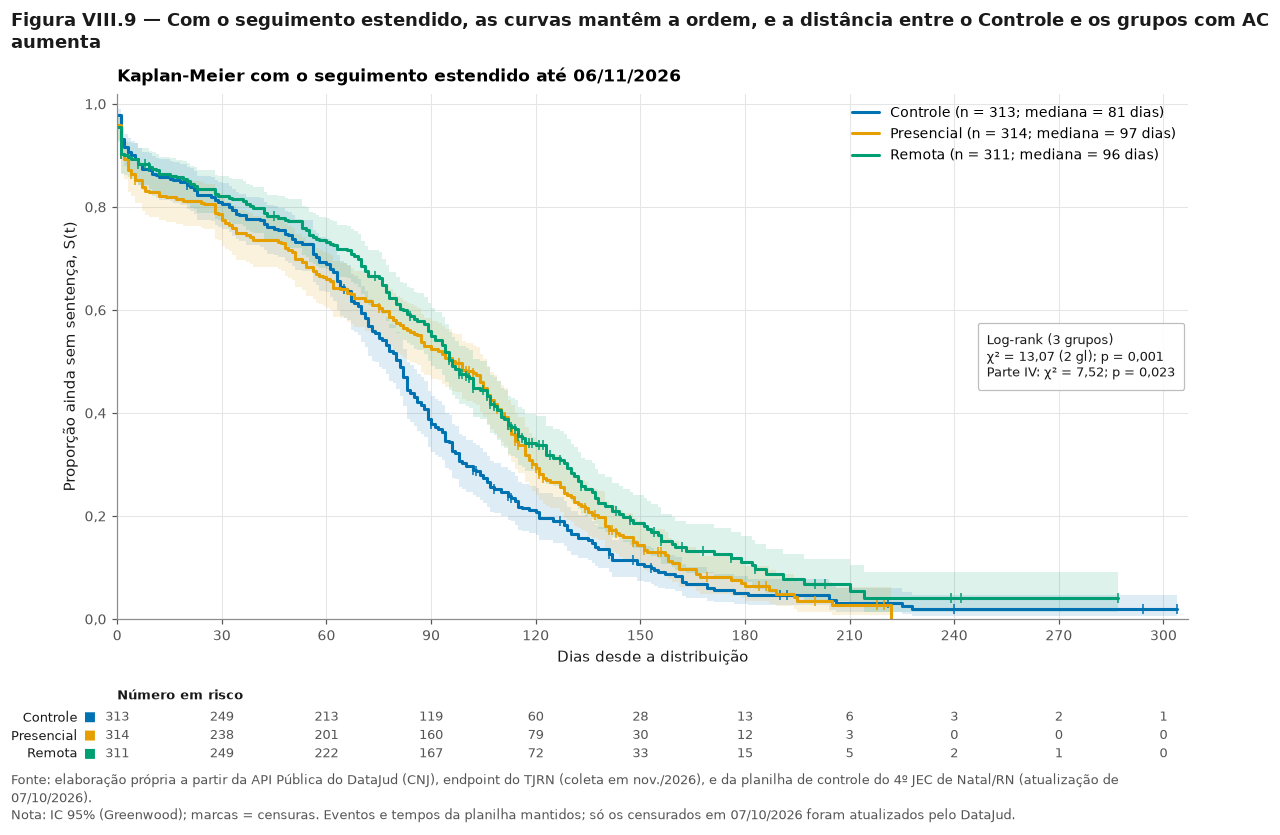

In [43]:
DJ_MESES = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul-ago']
DJ_COLS_MES = ['mes_fev', 'mes_mar', 'mes_abr', 'mes_mai', 'mes_jun', 'mes_julago']
DJ_X = ['Presencial', 'Remota'] + DJ_COLS_MES + ['origem_ext']


def dj_base_sob(df, T, E):
    s = pd.DataFrame({'T': df[T].astype(float).values, 'E': df[E].astype(int).values, 'grupo': df['grupo'].astype(str).values})
    s['Presencial'] = (s['grupo'] == 'Presencial').astype(int)
    s['Remota'] = (s['grupo'] == 'Remota').astype(int)
    mes = df['mes_distribuicao'].astype(str).replace({'jul': 'jul-ago', 'ago': 'jul-ago'}).values
    for c, m in zip(DJ_COLS_MES, DJ_MESES[1:]):
        s[c] = (mes == m).astype(int)
    s['origem_ext'] = df['origem_externa'].astype(int).values
    return s


def dj_km_grade(T, E, H):
    """S(t) de Kaplan-Meier nos dias inteiros t = 0..H (S[t] = P(T > t))."""
    T = np.asarray(T, dtype=int); E = np.asarray(E, dtype=int)
    n_sai = np.bincount(np.minimum(T, H + 1), minlength=H + 2)[:H + 1]
    risco = len(T) - np.concatenate([[0], np.cumsum(n_sai)[:-1]])
    d = np.bincount(np.minimum(T[E == 1], H + 1), minlength=H + 2)[:H + 1]
    with np.errstate(divide='ignore', invalid='ignore'):
        haz = np.where(risco > 0, d / risco, 0.0)
    return np.cumprod(1 - haz)


def dj_rmst(T, E, tau):
    return dj_km_grade(T, E, tau)[:tau].sum()


def dj_analise_sob(s, rotulo, B=2000, tau=180, semente=SEMENTE + 82):
    """Medianas, log-rank, Cox (b) e ΔRMST(tau) com bootstrap — a especificação da Parte IV."""
    out = {'rotulo': rotulo}
    for g in ORDEM_GRUPO:
        sg = s[s.grupo == g]
        out[f'mediana_{g}'] = KaplanMeierFitter().fit(sg['T'], sg['E']).median_survival_time_
        out[f'eventos_{g}'] = int(sg['E'].sum())
    lr = multivariate_logrank_test(s['T'], s['grupo'], s['E'])
    out['lr_chi2'], out['lr_p'] = lr.test_statistic, lr.p_value
    xs = [c for c in DJ_X if s[c].nunique() > 1]          # covariável constante no subconjunto sai do modelo
    out['X'] = xs
    cox = CoxPHFitter().fit(s[['T', 'E'] + xs], 'T', 'E')
    out['cox'] = cox
    for g in ('Presencial', 'Remota'):
        out[f'HR_{g}'] = np.exp(cox.params_[g])
        lo, hi = np.exp(cox.confidence_intervals_.loc[g].values)
        out[f'HR_{g}_ic'] = (lo, hi)
        out[f'HR_{g}_p'] = cox.summary.loc[g, 'p']
    rng = np.random.default_rng(semente)
    idx = {g: np.where(s.grupo.values == g)[0] for g in ORDEM_GRUPO}
    T_, E_ = s['T'].values.astype(int), s['E'].values.astype(int)
    est = {g: dj_rmst(T_[idx[g]], E_[idx[g]], tau) for g in ORDEM_GRUPO}
    bs = {g: np.array([dj_rmst(T_[ii], E_[ii], tau) for ii in (rng.choice(idx[g], len(idx[g])) for _ in range(B))])
          for g in ORDEM_GRUPO}
    for g in ORDEM_GRUPO:
        out[f'RMST_{g}'] = est[g]
    for g in ('Presencial', 'Remota'):
        dist = bs[g] - bs['Controle']
        dd = est[g] - est['Controle']
        out[f'dRMST_{g}'] = dd
        out[f'dRMST_{g}_ic'] = (np.percentile(dist, 2.5), np.percentile(dist, 97.5))
        out[f'dRMST_{g}_p'] = 2 * stats.norm.sf(abs(dd / dist.std(ddof=1)))
    out['n_eventos'] = int(s['E'].sum())
    out['n_censurados'] = int((s['E'] == 0).sum())
    return out


sob_base = dj_base_sob(ext, 'tempo', 'evento')
sob_ext = dj_base_sob(ext, 'T_ext', 'E_ext')
res_base = dj_analise_sob(sob_base, 'Parte IV (planilha, corte 07/10/2026)')
res_ext = dj_analise_sob(sob_ext, f'Estendido (DataJud, corte {DJ_CORTE:%d/%m/%Y})')

fig, ax = plt.subplots(figsize=(11, 6.6))
plot_km(ax, sob_ext, tempo='T', evento='E', grupo='grupo', passo=30)
ax.set_title(f'Kaplan-Meier com o seguimento estendido até {DJ_CORTE:%d/%m/%Y}')
anotar_teste(ax, texto_teste('Log-rank (3 grupos)', f'χ² = {fmt_br(res_ext["lr_chi2"], 2)} (2 gl)', res_ext['lr_p'],
                             f'Parte IV: χ² = {fmt_br(res_base["lr_chi2"], 2)}; p = {fmt_p(res_base["lr_p"])}'), loc='center right')
figura(fig, 'dj_km_estendido', 'Com o seguimento estendido, as curvas mantêm a ordem, e a distância entre o Controle e os grupos com AC aumenta',
       secao='8.4.3', fonte=FONTE_DJ, nota='IC 95% (Greenwood); marcas = censuras. Eventos e tempos da planilha mantidos; '
       'só os censurados em 07/10/2026 foram atualizados pelo DataJud.')

Medida,"Parte IV (planilha, corte 07/10/2026)","Estendido (DataJud, corte 06/11/2026)"
Sentenças,708,797
Censurados,230,141
Mediana Controle (dias),81,81
Mediana Presencial (dias),96,97
Mediana Remota (dias),95,96
HR Presencial (IC 95%),"0,87 (0,72–1,04); p = 0,117","0,85 (0,72–1,01); p = 0,059"
HR Remota (IC 95%),"0,81 (0,67–0,97); p = 0,022","0,76 (0,64–0,90); p = 0,002"
ΔRMST180 Presencial (dias),"6,5 (-1,9 a 15,6); p = 0,141","6,9 (-1,0 a 15,5); p = 0,098"
ΔRMST180 Remota (dias),"10,7 (1,8 a 19,4); p = 0,018","14,0 (5,0 a 22,1); p = 0,001"
Log-rank (3 grupos),"χ² = 7,52; p = 0,023","χ² = 13,07; p = 0,001"


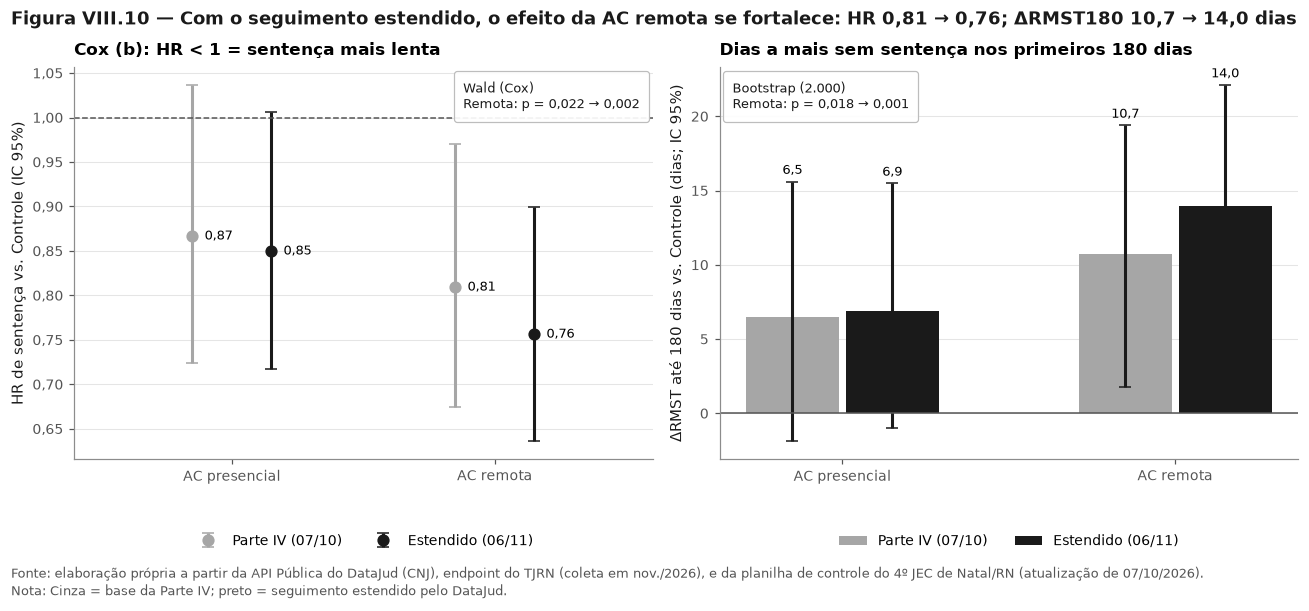

In [44]:
def dj_linha_res(r):
    lin = {'Análise': r['rotulo'], 'Sentenças': r['n_eventos'], 'Censurados': r['n_censurados']}
    for g in ORDEM_GRUPO:
        lin[f'Mediana {g} (dias)'] = r[f'mediana_{g}']
    for g in ('Presencial', 'Remota'):
        lo, hi = r[f'HR_{g}_ic']
        lin[f'HR {g} (IC 95%)'] = f"{fmt_br(r[f'HR_{g}'], 2)} ({fmt_br(lo, 2)}–{fmt_br(hi, 2)}); p = {fmt_p(r[f'HR_{g}_p'])}"
    for g in ('Presencial', 'Remota'):
        lo, hi = r[f'dRMST_{g}_ic']
        lin[f'ΔRMST180 {g} (dias)'] = f"{fmt_br(r[f'dRMST_{g}'], 1)} ({fmt_br(lo, 1)} a {fmt_br(hi, 1)}); p = {fmt_p(r[f'dRMST_{g}_p'])}"
    lin['Log-rank (3 grupos)'] = f"χ² = {fmt_br(r['lr_chi2'], 2)}; p = {fmt_p(r['lr_p'])}"
    return lin


comp_ext = pd.DataFrame([dj_linha_res(res_base), dj_linha_res(res_ext)]).set_index('Análise').T
tabela(comp_ext.rename_axis('Medida'), 'dj_comparacao_estendido',
       'Parte IV × seguimento estendido: medianas, Cox (b) e ΔRMST(180) por grupo (Controle = referência)', secao='8.4.3',
       fonte=FONTE_DJ, nota='Cox (b): grupo + mês de distribuição + origem externa (Efron). ΔRMST: IC percentil bootstrap estratificado '
       '(2.000); p pela aproximação normal. Valores divulgados na Parte IV: medianas 81/96/95 dias; HR 0,87 e 0,81; ΔRMST180 6,5 e 10,7 dias.')

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
pos = np.arange(2)
for j, (r, cor_r, nome) in enumerate([(res_base, CINZA, 'Parte IV (07/10)'), (res_ext, TINTA, f'Estendido ({DJ_CORTE:%d/%m})')]):
    hr = [r[f'HR_{g}'] for g in ('Presencial', 'Remota')]
    lo = [r[f'HR_{g}_ic'][0] for g in ('Presencial', 'Remota')]
    hi = [r[f'HR_{g}_ic'][1] for g in ('Presencial', 'Remota')]
    xx = pos + (j - 0.5) * 0.3
    axs[0].errorbar(xx, hr, yerr=[np.subtract(hr, lo), np.subtract(hi, hr)], fmt='o', color=cor_r, capsize=4, label=nome, ms=7)
    for xi, h in zip(xx, hr):
        axs[0].annotate(fmt_br(h, 2), (xi, h), xytext=(8, 0), textcoords='offset points', va='center', fontsize=8.5)
    dr = [r[f'dRMST_{g}'] for g in ('Presencial', 'Remota')]
    dlo = [r[f'dRMST_{g}_ic'][0] for g in ('Presencial', 'Remota')]
    dhi = [r[f'dRMST_{g}_ic'][1] for g in ('Presencial', 'Remota')]
    axs[1].bar(xx, dr, width=0.28, color=cor_r, label=nome)
    axs[1].errorbar(xx, dr, yerr=[np.subtract(dr, dlo), np.subtract(dhi, dr)], fmt='none', ecolor=TINTA, capsize=4)
    for xi, d, h_ in zip(xx, dr, dhi):
        axs[1].annotate(fmt_br(d, 1), (xi, h_), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
axs[0].axhline(1, color=TINTA_2, lw=1, ls='--')
axs[0].set_xticks(pos, ['AC presencial', 'AC remota'])
axs[0].set_xlim(-0.6, 1.6)
axs[0].set_ylabel('HR de sentença vs. Controle (IC 95%)')
axs[0].set_title('Cox (b): HR < 1 = sentença mais lenta')
axs[1].axhline(0, color=TINTA_2, lw=1)
axs[1].set_xticks(pos, ['AC presencial', 'AC remota'])
axs[1].set_ylabel('ΔRMST até 180 dias vs. Controle (dias; IC 95%)')
axs[1].set_title('Dias a mais sem sentença nos primeiros 180 dias')
for ax in axs:
    ax.grid(axis='x', visible=False)
    legenda_abaixo(ax, ncol=2)
anotar_teste(axs[0], texto_teste('Wald (Cox)', extra=f"Remota: p = {fmt_p(res_base['HR_Remota_p'])} → {fmt_p(res_ext['HR_Remota_p'])}"),
             loc='upper right')
anotar_teste(axs[1], texto_teste('Bootstrap (2.000)', extra=f"Remota: p = {fmt_p(res_base['dRMST_Remota_p'])} → {fmt_p(res_ext['dRMST_Remota_p'])}"),
             loc='upper left')
figura(fig, 'dj_efeitos_estendido', f"Com o seguimento estendido, o efeito da AC remota se fortalece: HR {fmt_br(res_base['HR_Remota'], 2)} → "
       f"{fmt_br(res_ext['HR_Remota'], 2)}; ΔRMST180 {fmt_br(res_base['dRMST_Remota'], 1)} → {fmt_br(res_ext['dRMST_Remota'], 1)} dias", secao='8.4.3',
       fonte=FONTE_DJ, nota='Cinza = base da Parte IV; preto = seguimento estendido pelo DataJud.')

**Leitura.** As funções desta seção reproduzem exatamente os números da Parte IV na base original (medianas de 81, 96 e 95 dias; HR 0,87 e 0,81; ΔRMST180 de 6,5 e 10,7 dias), o que garante que a comparação mede só o efeito do seguimento. Com o seguimento estendido até 06/11/2026, o número de sentenças passa de 708 para **797** e o de censurados cai de 230 para 141:

- as **medianas** quase não mudam (81, 97 e 96 dias): a mediana já era bem estimada em 07/10;
- o **log-rank** passa de χ² = 7,5 (p = 0,023) para **χ² = 13,1 (p = 0,001)**;
- o **HR da AC remota** passa de 0,81 (0,67–0,97) para **0,76 (0,64–0,90; p = 0,002)**, e o da presencial de 0,87 para 0,85 (0,72–1,01; p = 0,059);
- o **ΔRMST180 da AC remota** sobe de 10,7 para **14,0 dias (5,0 a 22,1)**; o da presencial fica em 6,9 dias (−1,0 a 15,5).

**Conclusão de VIII-B.** O seguimento curto **não** produzia o efeito; ao contrário, a análise principal era **conservadora**: com mais um mês de observação, a desvantagem de tempo da AC obrigatória, sobretudo da remota, aumenta e fica mais precisa, e a direção e a ordem dos grupos não mudam. A análise estendida é uma **sensibilidade**: usa uma fonte diferente para os censurados e um corte diferente, e por isso não substitui a análise principal, mas reforça a sua conclusão.

## 8.5 VIII-C — As regras TPU reproduzem as variáveis da pesquisa?

A seção 8.3 validou a planilha **variável por variável**. A pergunta agora é outra: se o estudo tivesse sido feito **só com o DataJud**, sem a planilha, as variáveis de análise (tempo, evento, tipo de desfecho, AC) e os **resultados** seriam os mesmos? Essa é a condição para aplicar as mesmas regras à população dos JECs de Natal (8.6), onde não há planilha.

**Construção.** Para os processos vinculados: tempo zero = 1º movimento no 4º JEC; evento = 1º julgamento (R1) até 07/10/2026 e antes da saída da unidade; censura na saída ou em 07/10/2026; grupo = o do sorteio (que só a planilha tem). **Critério pré-fixado** para "reproduz bem": κ ≥ 0,80 para o evento e para o tipo de desfecho; pelo menos 90% dos tempos com diferença ≤ 1 dia entre os processos com evento nas duas fontes; e HR e ΔRMST do DataJud dentro do IC 95% da planilha.

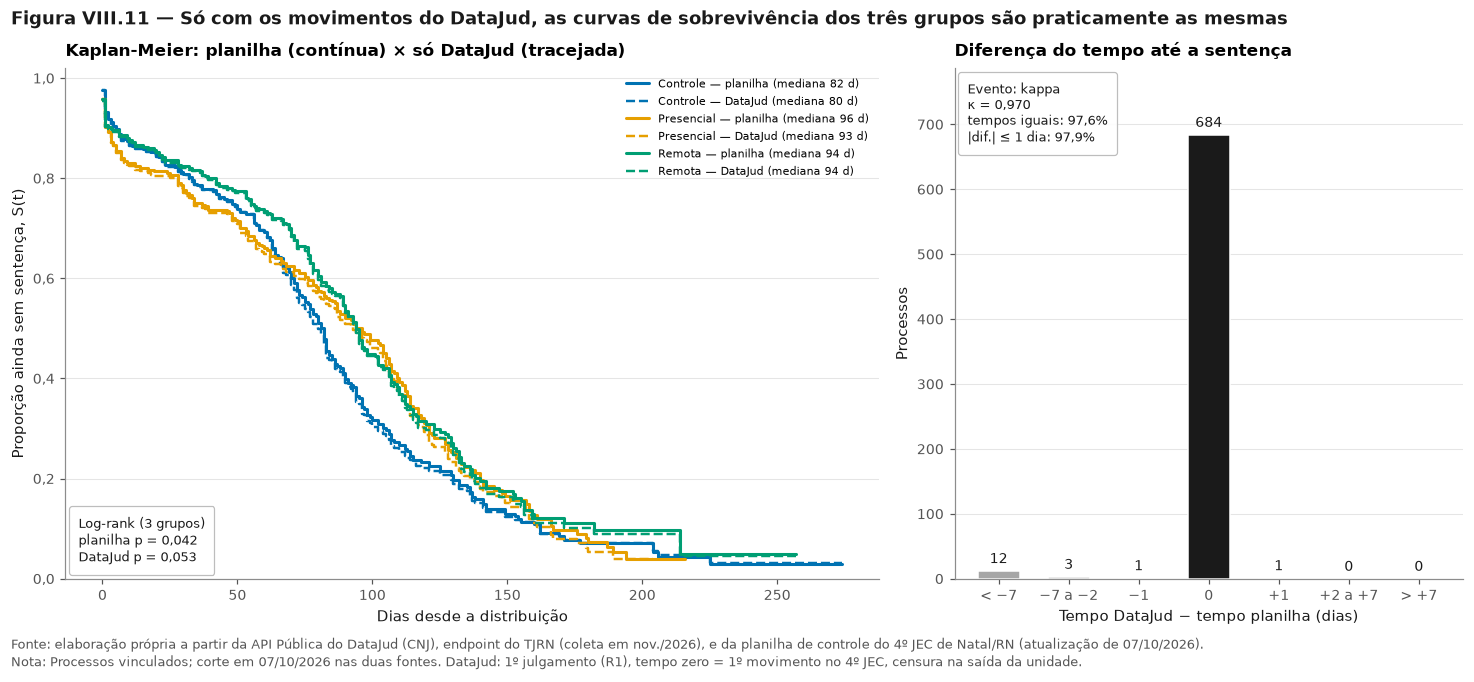

Critério,Valor,Limiar,Atende
κ do evento (sentença até 07/10),"0,970","≥ 0,80",Sim
κ do tipo de desfecho (R1),"0,955","≥ 0,80",Sim
Tempos com |dif.| ≤ 1 dia,"97,9%",≥ 90%,Sim
HR Presencial (DataJud) no IC da planilha,"0,90 vs. 0,88 (0,74–1,06)",dentro do IC,Sim
HR Remota (DataJud) no IC da planilha,"0,82 vs. 0,82 (0,68–0,98)",dentro do IC,Sim
ΔRMST180 Presencial (DataJud) no IC da planilha,"4,4 vs. 5,4 (-3,0 a 14,8)",dentro do IC,Sim
ΔRMST180 Remota (DataJud) no IC da planilha,"9,6 vs. 9,8 (1,5 a 18,4)",dentro do IC,Sim


Regras TPU reproduzem a planilha: True


In [45]:
vc = v.copy()
_s = vc['dj_sent_dt'].dt.normalize()
_x = vc['dj_saida_dt'].dt.normalize()
ev_dj = _s.notna() & (_s <= DATA_CORTE)
sai_dj = ~ev_dj & _x.notna() & (_x <= DATA_CORTE)
t0 = vc['dj_entrada'].dt.normalize()
vc['T_dj'] = np.where(ev_dj, (_s - t0).dt.days, np.where(sai_dj, (_x - t0).dt.days, (DATA_CORTE - t0).dt.days)).astype(float)
vc['E_dj'] = ev_dj.astype(int)
vc['dT'] = np.where((vc['E_dj'] == 1) & (vc['evento'].astype(int) == 1), vc['T_dj'] - vc['tempo'].astype(float), np.nan)

k_ev = dj_kappa(vc['evento'].astype(int), vc['E_dj'])
k_tp = kap_desf['R1']
dT = vc['dT'].dropna()
s_pl = dj_base_sob(vc, 'tempo', 'evento')
s_dj = dj_base_sob(vc, 'T_dj', 'E_dj')
r_pl = dj_analise_sob(s_pl, 'Planilha (vinculados)')
r_dj = dj_analise_sob(s_dj, 'Só DataJud (regras TPU)')

fig, axs = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axs[0]
for g in ORDEM_GRUPO:
    for s_, ls, rot in [(s_pl, '-', 'planilha'), (s_dj, '--', 'DataJud')]:
        sg = s_[s_.grupo == g]
        km = KaplanMeierFitter().fit(sg['T'], sg['E'])
        sf = km.survival_function_.iloc[:, 0]
        ax.step(sf.index, sf.values, where='post', color=CORES_GRUPO[g], ls=ls, lw=2 if ls == '-' else 1.6,
                label=f'{g} — {rot} (mediana {fmt_br(km.median_survival_time_, 0)} d)')
ax.set_xlabel(ROTULOS['dias'])
ax.set_ylabel(ROTULOS['S'])
ax.set_ylim(0, 1.02)
ax.set_title('Kaplan-Meier: planilha (contínua) × só DataJud (tracejada)')
ax.legend(fontsize=7.5, loc='upper right')
anotar_teste(ax, texto_teste('Log-rank (3 grupos)', f'planilha p = {fmt_p(r_pl["lr_p"])}', extra=f'DataJud p = {fmt_p(r_dj["lr_p"])}'),
             loc='lower left')
fx = dj_faixa(dT)
barras_verticais(axs[1], FAIXAS_DIF, fx.values, cores=[TINTA if f == '0' else CINZA for f in FAIXAS_DIF],
                 ylabel='Processos', xlabel='Tempo DataJud − tempo planilha (dias)')
axs[1].set_title('Diferença do tempo até a sentença')
anotar_teste(axs[1], texto_teste('Evento: kappa', f'κ = {fmt_br(k_ev[0], 3)}', efeito=f'tempos iguais: {pct_br((dT == 0).mean())}',
                                 extra=f'|dif.| ≤ 1 dia: {pct_br((dT.abs() <= 1).mean())}'), loc='upper left')
figura(fig, 'dj_regras_km', 'Só com os movimentos do DataJud, as curvas de sobrevivência dos três grupos são praticamente as mesmas',
       secao='8.5', fonte=FONTE_DJ, nota='Processos vinculados; corte em 07/10/2026 nas duas fontes. DataJud: 1º julgamento (R1), '
       'tempo zero = 1º movimento no 4º JEC, censura na saída da unidade.')

crit = pd.DataFrame([
    {'Critério': 'κ do evento (sentença até 07/10)', 'Valor': fmt_br(k_ev[0], 3), 'Limiar': '≥ 0,80', 'Atende': k_ev[0] >= 0.8},
    {'Critério': 'κ do tipo de desfecho (R1)', 'Valor': fmt_br(k_tp[0], 3), 'Limiar': '≥ 0,80', 'Atende': k_tp[0] >= 0.8},
    {'Critério': 'Tempos com |dif.| ≤ 1 dia', 'Valor': pct_br((dT.abs() <= 1).mean()), 'Limiar': '≥ 90%',
     'Atende': (dT.abs() <= 1).mean() >= 0.9},
] + [{'Critério': f'HR {g} (DataJud) no IC da planilha', 'Valor': f"{fmt_br(r_dj[f'HR_{g}'], 2)} vs. {fmt_br(r_pl[f'HR_{g}'], 2)} "
      f"({fmt_br(r_pl[f'HR_{g}_ic'][0], 2)}–{fmt_br(r_pl[f'HR_{g}_ic'][1], 2)})", 'Limiar': 'dentro do IC',
      'Atende': r_pl[f'HR_{g}_ic'][0] <= r_dj[f'HR_{g}'] <= r_pl[f'HR_{g}_ic'][1]} for g in ('Presencial', 'Remota')]
  + [{'Critério': f'ΔRMST180 {g} (DataJud) no IC da planilha', 'Valor': f"{fmt_br(r_dj[f'dRMST_{g}'], 1)} vs. {fmt_br(r_pl[f'dRMST_{g}'], 1)} "
      f"({fmt_br(r_pl[f'dRMST_{g}_ic'][0], 1)} a {fmt_br(r_pl[f'dRMST_{g}_ic'][1], 1)})", 'Limiar': 'dentro do IC',
      'Atende': r_pl[f'dRMST_{g}_ic'][0] <= r_dj[f'dRMST_{g}'] <= r_pl[f'dRMST_{g}_ic'][1]} for g in ('Presencial', 'Remota')])
DJ_REGRAS_OK = bool(crit['Atende'].all())
tabela(crit, 'dj_criterios', 'Critérios pré-fixados para aplicar as regras TPU à população', secao='8.5', fonte=FONTE_DJ,
       destaque=~crit['Atende'], nota=f'Linhas em destaque = critério não atendido. Decisão: '
       f'{"aplicar as regras à população (8.6)" if DJ_REGRAS_OK else "aplicar com ressalvas"}.')
print('Regras TPU reproduzem a planilha:', DJ_REGRAS_OK)

**Leitura.** Construídas **só com os movimentos** (sem nenhuma informação da planilha além do grupo sorteado), as variáveis reproduzem as da pesquisa: o evento concorda com κ = 0,970, o tipo de desfecho com κ = 0,955, e 97,9% dos tempos diferem em no máximo 1 dia (a maioria das diferenças grandes são os acordos posteriores à sentença, em que a planilha é que se afasta da primeira sentença). As curvas de Kaplan-Meier das duas fontes praticamente se sobrepõem em cada grupo, e os efeitos estimados ficam dentro do IC da planilha nos mesmos processos (HR da AC remota 0,82 nas duas fontes; ΔRMST180 de 9,6 × 9,8 dias). **Todos os critérios pré-fixados foram atendidos**: as regras TPU podem ser aplicadas à população dos JECs de Natal, onde não há planilha, com a garantia de que medem o mesmo que a pesquisa mediu.

## 8.6 VIII-D — O 4º JEC entre os Juizados Cíveis de Natal

### 8.6.1 A população e o desenho

**População.** Processos de **classe 436** (Procedimento do Juizado Especial Cível), ou de classe 156 (Cumprimento de sentença) com o movimento 14739 de evolução de classe (o mesmo processo, já na fase de cumprimento), cujo **1º movimento** foi lançado em um dos 14 JECs cíveis de Natal, ajuizados de 01/01 a 03/08 de **2025** (antes) e de **2026** (durante o experimento), mesma janela do calendário. A unidade de cada processo é o juizado do 1º movimento (a distribuição); quem saiu depois continua contado na unidade de origem, censurado na saída, como na Parte IV. As regras de 8.2 são as mesmas para todas as unidades.

**Desfechos com horizonte fixo, por coorte mensal.** Comparar tempos de unidades ou anos com seguimentos diferentes mistura o efeito com o tempo de observação (o artefato da entrada escalonada; seção 2.5). Por isso, cada processo é acompanhado **só nos primeiros 90 dias**, e cada coorte mensal de ajuizamento tem o mesmo horizonte:

- **P90**: proporção sentenciada até 90 dias, 1 − Ŝ(90) de Kaplan-Meier (saída da unidade = censura);
- **RMST90**: dias, em média, sem sentença nos primeiros 90 dias;
- **% sem mérito até 90 dias** e **% homologação até 90 dias**: proporções simples.

**Diferenças em diferenças (DiD).** Para cada unidade *u*, Δ_u = Y_u,2026 − Y_u,2025; o DiD do 4º JEC é Δ_4º − média de Δ dos outros 13. Com 14 unidades, a inferência não pode tratar processos como independentes (os processos de uma unidade compartilham juiz, cartório e pauta); usa-se a **inferência por permutação entre unidades** (placebo): o mesmo DiD é calculado fingindo que cada um dos outros 13 juizados foi o "tratado", e o p-valor é a posição do 4º JEC entre os 14 (o menor p possível é 1/14 ≈ 0,071). O DiD supõe **tendências paralelas** antes de 2026, verificadas no gráfico mensal de 2025.

**Leitura.** É uma comparação **observacional** do efeito do **experimento sobre a unidade** (os três braços somados, mais o que mudou na rotina por causa dele: pauta de audiências, reatividade, o juiz-pesquisador), e não do efeito do rito.

In [46]:
DJ_JAN_AGO = {2025: (pd.Timestamp('2025-01-01'), pd.Timestamp('2025-08-03')),
              2026: (pd.Timestamp('2026-01-01'), pd.Timestamp('2026-08-03'))}
H_DJ = 90
pop = pd.DataFrame()
if DJ_POP4_OK:
    _linhas = []
    for x in dj_pop_regs.values():
        if x.get('grau') != 'JE':
            continue
        movs = sorted(x.get('movimentos') or [], key=lambda m: m['dataHora'])
        if not movs:
            continue
        un = next((dj_oj(m) for m in movs if dj_oj(m)), '')
        if un not in JECS_NATAL:
            continue
        cl = (x.get('classe') or {}).get('codigo')
        evo = any(int(m['codigo']) == 14739 for m in movs)
        if not (cl == 436 or (cl == 156 and evo)):
            continue
        r = dj_derivar(x, un)
        r['numero'] = x['numeroProcesso']
        _linhas.append(r)
    pop = pd.DataFrame(_linhas).drop_duplicates('numero')
    pop['jec'] = pop['unidade'].map(JECS_NATAL)
    pop['quarto'] = pop['unidade'] == COD_4JEC
    pop['ano'] = pop['ajuizamento'].dt.year
    pop['coorte'] = pop['ajuizamento'].dt.to_period('M')
    pop['janela'] = [(a in DJ_JAN_AGO) and (DJ_JAN_AGO[a][0] <= d <= DJ_JAN_AGO[a][1]) for a, d in zip(pop['ano'], pop['ajuizamento'])]
    print(f'População: {len(pop):,} processos; por ano de ajuizamento:', pop['ano'].value_counts().sort_index().to_dict())
else:
    print('Coleta da população dos JECs de Natal ainda não disponível no cache (datajud_sondagem/natal/).')
    DJ_CORTE_POP = DJ_CORTE

População: 3,714 processos; por ano de ajuizamento: {2024: 1366, 2025: 1432, 2026: 916}


In [47]:
if DJ_POP4_OK:
    vol_pop = dj_volume_diario(dj_pop_regs.values(), '2026-08-15', max(x.get('dataHoraUltimaAtualizacao', '')[:10] for x in dj_pop_regs.values()))
    DJ_CORTE_POP, nivel_pop, queda_pop = dj_corte_confiavel(vol_pop, DATA_CORTE - pd.Timedelta(days=28), DATA_CORTE)
    t0p = pop['entrada'].dt.normalize()
    _s = pop['sent_dt'].dt.normalize()
    _x = pop['saida_dt'].dt.normalize()
    evp = _s.notna() & (_s <= DJ_CORTE_POP)
    saip = ~evp & _x.notna() & (_x <= DJ_CORTE_POP)
    pop['T'] = np.where(evp, (_s - t0p).dt.days, np.where(saip, (_x - t0p).dt.days, (DJ_CORTE_POP - t0p).dt.days)).astype(float)
    pop['E'] = evp.astype(int)
    pop['tipo'] = np.where(evp, pop['sent_tipo'], np.where(saip, 'Redistribuição', 'Ativo'))
    pop = pop[pop['T'] >= 0].copy()
    pop['sm90'] = (pop['tipo'] == 'Sem mérito') & (pop['T'] <= H_DJ)
    pop['hom90'] = (pop['tipo'] == 'Homologação') & (pop['T'] <= H_DJ)

    # cobertura da amostra
    p4 = pop[pop['quarto'] & pop['janela'] & (pop['ano'] == 2026)]
    na_pop = dj['numero'].isin(p4['numero'])
    def _motivo(n):
        x = _principal.get(n)
        if x is None:
            return 'sem registro de juizado no DataJud'
        movs = sorted(x.get('movimentos') or [], key=lambda m: m['dataHora'])
        cl = (x.get('classe') or {}).get('codigo')
        if not (cl == 436 or (cl == 156 and any(int(m['codigo']) == 14739 for m in movs))):
            return f'outra classe ({cl} {(x.get("classe") or {}).get("nome") or ""})'.strip()
        if movs and dj_oj(movs[0]) != COD_4JEC:
            return '1º movimento em outro órgão (chegou por redistribuição)'
        if not ('20260101' <= str(x.get('dataAjuizamento'))[:8] <= '20260803'):
            return 'ajuizado fora de 01/01 a 03/08/2026'
        return 'outro'
    mot = dj.loc[~na_pop, 'numero'].map(_motivo).value_counts()
    cob = pd.DataFrame([['População DataJud: 4º JEC, 2026 (01/01 a 03/08)', len(p4)],
                        ['   dos quais estão na planilha', int(p4['numero'].isin(dj['numero']).sum())],
                        ['   não estão na planilha', int((~p4['numero'].isin(dj['numero'])).sum())],
                        ['Planilha (938 processos)', len(dj)],
                        ['   dos quais estão na população DataJud', int(na_pop.sum())]]
                       + [[f'   fora da população: {k}', int(v)] for k, v in mot.items()], columns=['Conjunto', 'Processos'])
    tabela(cob, 'dj_cobertura', 'A definição de população recupera quase todos os processos do experimento', secao='8.6.1', fonte=FONTE_DJ,
           nota='População = classe 436 (ou 156 com evolução de classe), 1º movimento no juizado, ajuizamento na janela. '
                'Motivos de exclusão avaliados no registro principal do processo (8.3.1).')

if DJ_POP_OK:
    npop = pop[pop['janela']].groupby(['jec', 'ano']).size().unstack().reindex([JECS_NATAL[c] for c in JECS_NATAL])
    fig, ax = plt.subplots(figsize=(12, 4.8))
    barras_agrupadas(ax, npop.rename(columns=str), cores={'2025': CINZA, '2026': TINTA}, ylabel='Processos ajuizados (01/01 a 03/08)')
    ax.set_xticks(range(len(npop)), [f'{j} JEC' for j in npop.index], fontsize=8.5)
    ax.set_title('Processos da população por juizado e ano (mesma janela do calendário)')
    legenda_abaixo(ax, ncol=2)
    _o = npop[2026].values; _e = np.full_like(_o, _o.mean(), dtype=float)
    chi_n, p_n = stats.chisquare(_o, _e)
    anotar_teste(ax, texto_teste('Qui-quadrado de aderência (2026)', f'χ² = {fmt_br(chi_n, 2)} (13 gl)', p_n,
                                 'H₀: distribuição igual entre os 14'), loc='lower right')
    figura(fig, 'dj_pop_n', 'A distribuição por sorteio divide os processos quase igualmente entre os 14 JECs', secao='8.6.1',
           fonte=FONTE_DJ_POP, nota=f'Classe 436 (ou 156 com evolução de classe); unidade = juizado do 1º movimento. Corte do índice: {DJ_CORTE_POP:%d/%m/%Y}.')

Conjunto,Processos
"População DataJud: 4º JEC, 2026 (01/01 a 03/08)",883
dos quais estão na planilha,882
não estão na planilha,1
Planilha (938 processos),938
dos quais estão na população DataJud,882
fora da população: 1º movimento em outro órgão (chegou por redistribuição),36
fora da população: sem registro de juizado no DataJud,12
fora da população: outra classe (94 Despejo por Falta de Pagamento Cumulado Com Cobrança),2
fora da população: outra classe (37 Embargos de Terceiro Cível),2
fora da população: ajuizado fora de 01/01 a 03/08/2026,1


**Leitura.** A definição de população é validada pelo próprio experimento: dos 883 processos que o DataJud atribui ao 4º JEC entre 01/01 e 03/08/2026 (classe 436, 1º movimento na unidade), **882 estão na planilha**, isto é, o sorteio do pesquisador cobriu praticamente toda a entrada de ações de conhecimento da unidade. No sentido inverso, 882 dos 938 processos da planilha estão na população; os 56 restantes não são falhas da regra, e sim processos que ela exclui por desenho: 36 chegaram ao 4º JEC por redistribuição (o 1º movimento é de outro órgão), 12 não têm registro de juizado com passagem pelo 4º JEC no índice (8.3.1), 7 têm outra classe (despejo, embargos de terceiro, execução de título, procedimento comum ou da Fazenda Pública), que a planilha incluiu e a população de classe 436 não inclui, e 1 foi ajuizado antes de 2026.

**Situação da coleta: a comparação com os outros 13 JECs ficou parcial.** A API do CNJ esteve sobrecarregada durante toda a coleta (HTTP 429, `es_rejected_execution_exception`, erros de gateway): a certa altura, rendia cerca de 100 processos em duas horas. Foram coletados, processo a processo, **todos** os processos do **4º JEC** ajuizados em 2024, 2025 e de 01/01 a 03/08/2026; dos **outros 13 JECs**, nenhuma janela pôde ser concluída. Por isso, as análises com tempos e horizonte fixo entre unidades (8.6.3 tendências, 8.6.4 DiD com 90 dias, 8.6.6 tipicidade) **não foram executadas nesta versão**. O código está pronto: `coleta_natal.py` retoma do cache (`natal/estado.json`) e o notebook passa a executá-las sozinho quando as janelas estiverem completas (só usa fatias concluídas e não acessa a rede). Em substituição, a seção 8.6.2 compara os 14 juizados por **consultas agregadas**, que a API respondeu.

### 8.6.2 Os 14 JECs por consultas agregadas (plano B)

Como a API rejeitava as consultas que devolvem documentos (a fase *fetch* do Elasticsearch), os outros 13 juizados foram consultados por **agregações** (`size: 0`), que só devolvem contagens e passaram na primeira tentativa (scripts `contagens_mensais.py` e `contagens_desfecho.py`; caches `natal_contagens_*.json`). As agregações dão duas informações por juizado:

1. o **volume mensal de ajuizamentos** (classe 436/156), de 01/2025 a 03/08/2026;
2. para as janelas de 01/01 a 03/08 de 2025 e de 2026, quantos processos têm, **na data da coleta**, algum movimento de **sentença**, de **mérito**, **sem mérito** e de **homologação**, pelos mesmos códigos TPU de 8.2.

**O que muda em relação ao desenho de 8.6.1.** Não há tempos: a medida é a proporção de processos com cada tipo de movimento **até a coleta** (novembro de 2026), e não até 90 dias. Os processos de 2025 tiveram mais tempo de observação que os de 2026, mas essa diferença é **a mesma para todos os juizados** (mesmas janelas de ajuizamento, mesma data de coleta), e por isso se cancela na diferença em diferenças. As categorias não são exclusivas (um processo pode ter extinção sem mérito e, depois, um acordo homologado), e a unidade é o órgão **atual** do registro (quem foi redistribuído conta no destino). A inferência é a mesma de 8.6.1: **permutação entre unidades** (placebo), com p mínimo de 1/14.

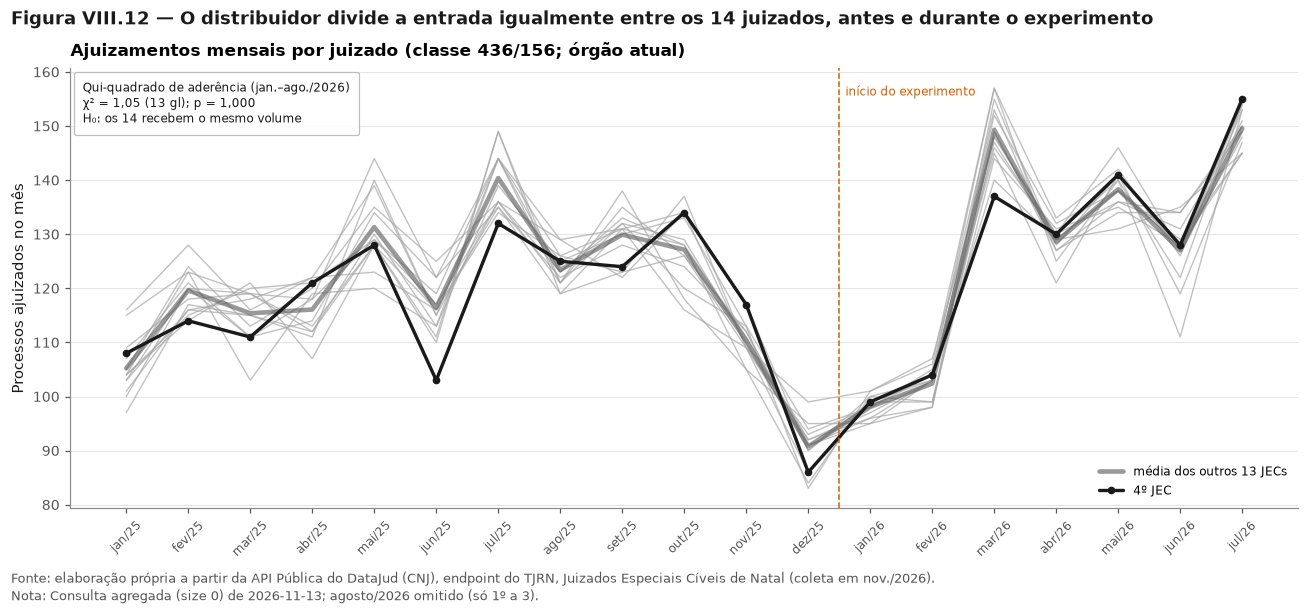

Movimento (até a coleta),4º JEC 2025,4º JEC 2026,Outros 2025,Outros 2026,DiD (p.p.),Posição |DiD| (1 = maior),p (permutação)
Sentença,"99,5","88,3","98,3","91,9","-4,9",3,"0,214"
Mérito,"61,1","47,6","68,2","66,4","-11,8",1,"0,071"
Sem mérito,"36,3","33,4","25,6","19,8","2,9",5,"0,357"
Homologação,"13,4","9,5","13,1","9,9","-0,7",8,"0,571"


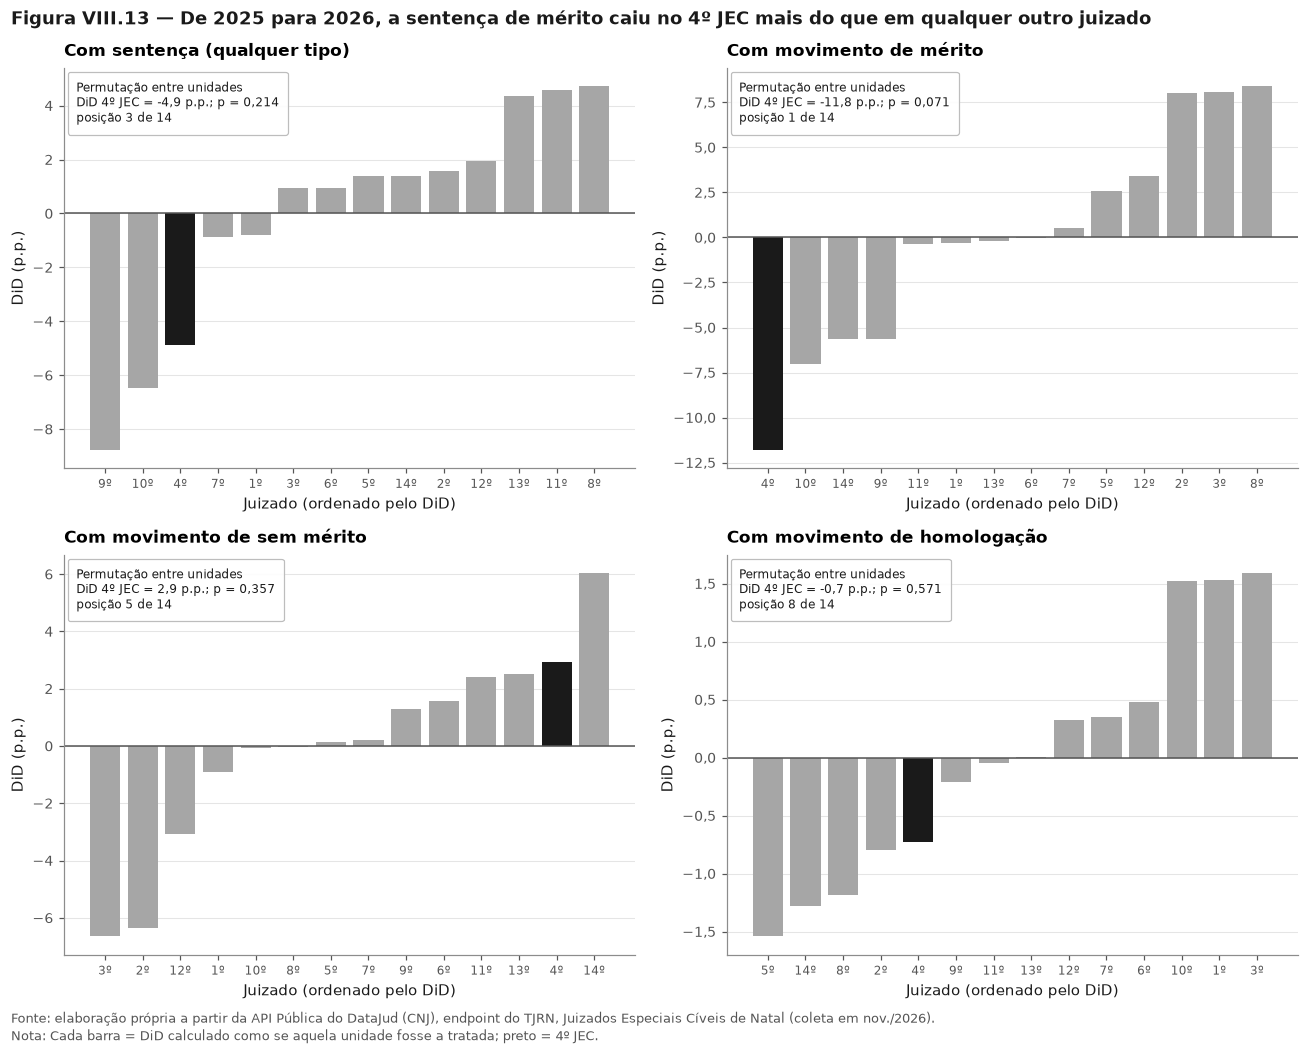

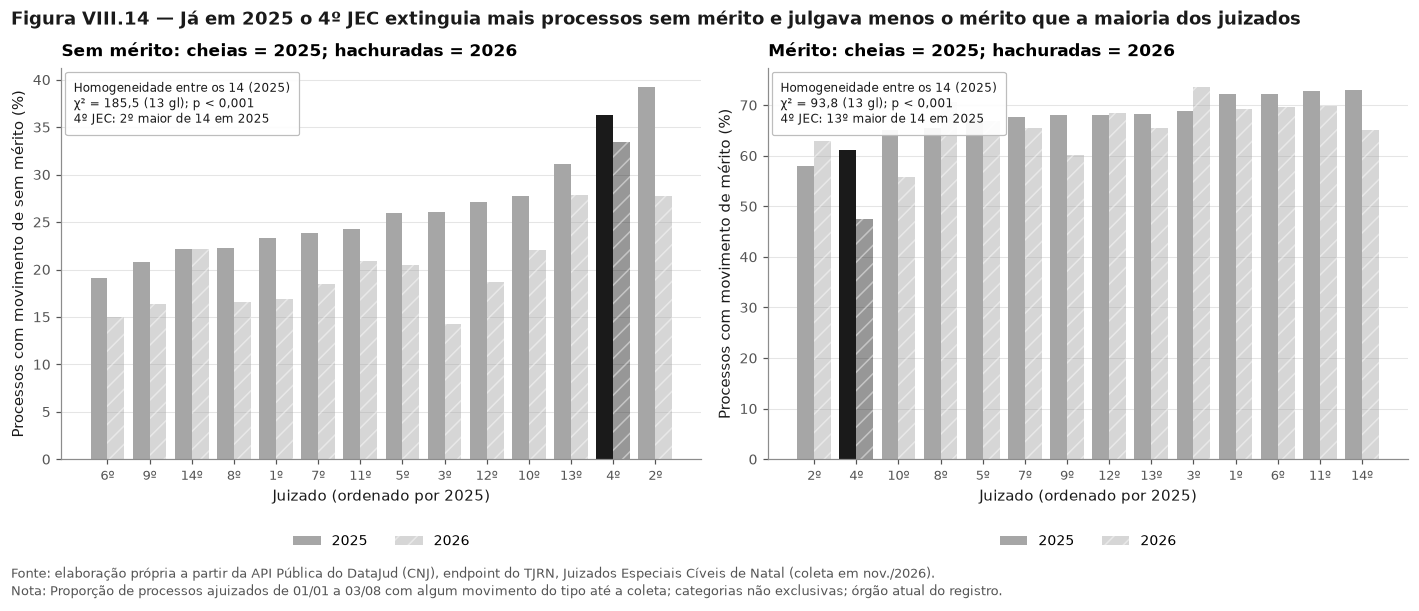

Juizado,n 2025,n 2026,Sentença 2025,Sentença 2026,Mérito 2025,Mérito 2026,Sem mérito 2025,Sem mérito 2026,Homologação 2025,Homologação 2026
1º,862,896,"98,5","91,1","72,2","69,2","23,3","16,9","13,0","11,2"
2º,841,909,"99,4","94,2","58,0","62,8","39,2","27,7","12,2","8,3"
3º,864,905,"99,0","93,1","68,8","73,6","26,0","14,3","12,4","10,6"
4º,821,898,"99,5","88,3","61,1","47,6","36,3","33,4","13,4","9,5"
5º,844,889,"98,0","92,6","67,2","66,9","25,9","20,5","12,6","7,9"
6º,846,893,"97,5","91,7","72,2","69,5","19,1","15,0","13,0","10,2"
7º,838,910,"97,7","90,2","67,7","65,5","23,9","18,5","12,1","9,1"
8º,849,909,"94,9","92,6","65,5","70,6","22,3","16,6","14,3","9,9"
9º,887,907,"97,3","82,5","68,0","60,1","20,7","16,3","11,4","7,9"
10º,852,895,"99,1","86,4","65,0","55,9","27,7","22,0","12,8","10,9"


In [48]:
DJ_AGG_VOL = DJ_PASTA / 'natal_contagens_mensais.json'
DJ_AGG_DESF = DJ_PASTA / 'natal_contagens_desfecho.json'
DJ_AGG_OK = DJ_AGG_VOL.exists() and DJ_AGG_DESF.exists()
if DJ_AGG_OK:
    agv = json.loads(DJ_AGG_VOL.read_text(encoding='utf-8'))
    agd = json.loads(DJ_AGG_DESF.read_text(encoding='utf-8'))
    # ---- volume mensal
    vol = pd.DataFrame({JECS_NATAL[o]: pd.Series(m) for o, m in agv['orgaos'].items()}).fillna(0).sort_index()
    vol = vol.loc[[k for k in vol.index if '202501' <= k <= '202607']]
    fig, ax = plt.subplots(figsize=(12, 5))
    xs = np.arange(len(vol))
    for j in vol.columns:
        if j != '4º':
            ax.plot(xs, vol[j], color=COR_OUTROS, lw=0.9, alpha=0.7)
    ax.plot(xs, vol.drop(columns='4º').mean(axis=1), color=TINTA_2, lw=3, alpha=0.6, label='média dos outros 13 JECs')
    ax.plot(xs, vol['4º'], color=COR_4JEC, lw=2.2, marker='o', ms=4, label='4º JEC')
    ax.axvline(11.5, color=DESTAQUE, ls='--', lw=1)
    ax.text(11.6, ax.get_ylim()[1] * 0.98, 'início do experimento', color=DESTAQUE, fontsize=8, va='top')
    ax.set_xticks(xs, [f"{MESES_PT[int(k[4:]) - 1]}/{k[2:4]}" for k in vol.index], rotation=45, fontsize=8)
    ax.set_ylabel('Processos ajuizados no mês')
    ax.set_title('Ajuizamentos mensais por juizado (classe 436/156; órgão atual)')
    ax.legend(loc='lower right', fontsize=8)
    j26 = pd.Series({JECS_NATAL[o]: d['2026']['n'] for o, d in agd['orgaos'].items()})
    chi_v2, p_v2 = stats.chisquare(j26.values)
    anotar_teste(ax, texto_teste('Qui-quadrado de aderência (jan.–ago./2026)', f'χ² = {fmt_br(chi_v2, 2)} (13 gl)', p_v2,
                                 'H₀: os 14 recebem o mesmo volume'), loc='upper left', tamanho=8)
    figura(fig, 'dj_agg_volume', 'O distribuidor divide a entrada igualmente entre os 14 juizados, antes e durante o experimento',
           secao='8.6.2', fonte=FONTE_DJ_POP, nota=f'Consulta agregada (size 0) de {agv["coletado_em"][:10]}; agosto/2026 omitido (só 1º a 3).')

    # ---- desfechos por juizado e ano
    linhas = []
    for o, d in agd['orgaos'].items():
        for a in ('2025', '2026'):
            r = d[a]
            linhas.append({'jec': JECS_NATAL[o], 'ano': int(a), 'n': r['n'], 'Sentença': r['sentenca'] / r['n'],
                           'Mérito': r.get('merito', 0) / r['n'], 'Sem mérito': r.get('sem_merito', 0) / r['n'],
                           'Homologação': r.get('homologacao', 0) / r['n']})
    agt = pd.DataFrame(linhas)
    DESF_AGG = ['Sentença', 'Mérito', 'Sem mérito', 'Homologação']
    wa = agt.pivot(index='jec', columns='ano', values=DESF_AGG)
    did_agg, rows = {}, []
    for y in DESF_AGG:
        delta = wa[(y, 2026)] - wa[(y, 2025)]
        did = pd.Series({u: delta[u] - delta.drop(u).mean() for u in delta.index})
        did_agg[y] = did
        obs = did['4º']
        rows.append({'Movimento (até a coleta)': y, '4º JEC 2025': 100 * wa.loc['4º', (y, 2025)], '4º JEC 2026': 100 * wa.loc['4º', (y, 2026)],
                     'Outros 2025': 100 * wa[(y, 2025)].drop('4º').mean(), 'Outros 2026': 100 * wa[(y, 2026)].drop('4º').mean(),
                     'DiD (p.p.)': 100 * obs, 'Posição |DiD| (1 = maior)': int((did.abs() >= abs(obs) - 1e-12).sum()),
                     'p (permutação)': float(np.mean(did.abs() >= abs(obs) - 1e-12))})
    did_agg_tab = pd.DataFrame(rows)
    tabela(did_agg_tab, 'dj_agg_did', 'Diferenças em diferenças por consultas agregadas: 4º JEC × outros 13 JECs, 2025 × 2026',
           secao='8.6.2', fonte=FONTE_DJ_POP, destaque='p (permutação)', casas=1,
           nota='Percentual de processos ajuizados de 01/01 a 03/08 de cada ano com algum movimento do tipo até a coleta (nov./2026). '
                '"Outros" = média simples das 13 unidades. p = proporção das 14 unidades com |DiD placebo| ≥ |DiD do 4º JEC|.')
    fig, axs = plt.subplots(2, 2, figsize=(12, 9))
    for ax, y in zip(axs.flat, DESF_AGG):
        s_ = (100 * did_agg[y]).sort_values()
        ax.bar(range(len(s_)), s_.values, color=[COR_4JEC if u == '4º' else COR_OUTROS for u in s_.index])
        ax.axhline(0, color=TINTA_2, lw=1)
        ax.set_xticks(range(len(s_)), list(s_.index), fontsize=8)
        ax.set_xlabel('Juizado (ordenado pelo DiD)')
        ax.set_ylabel('DiD (p.p.)')
        ax.set_title(f'Com movimento de {y.lower()}' if y != 'Sentença' else 'Com sentença (qualquer tipo)')
        ax.grid(axis='x', visible=False)
        lin = did_agg_tab[did_agg_tab['Movimento (até a coleta)'] == y].iloc[0]
        anotar_teste(ax, texto_teste('Permutação entre unidades', f"DiD 4º JEC = {fmt_br(lin['DiD (p.p.)'], 1)} p.p.", lin['p (permutação)'],
                                     f"posição {lin['Posição |DiD| (1 = maior)']} de 14"), loc='upper left', tamanho=8)
    figura(fig, 'dj_agg_did', ('De 2025 para 2026, a sentença de mérito caiu no 4º JEC mais do que em qualquer outro juizado'
                               if did_agg_tab.set_index('Movimento (até a coleta)').loc['Mérito', 'Posição |DiD| (1 = maior)'] == 1
                               else 'Diferenças em diferenças entre os 14 juizados (placebo por permutação)'),
           secao='8.6.2', fonte=FONTE_DJ_POP, nota='Cada barra = DiD calculado como se aquela unidade fosse a tratada; preto = 4º JEC.')

    # ---- tipicidade em 2025 (antes do experimento)
    fig, axs = plt.subplots(1, 2, figsize=(13, 5))
    for ax, y in zip(axs, ['Sem mérito', 'Mérito']):
        s25 = wa[(y, 2025)].sort_values()
        xs = np.arange(len(s25))
        cor = [COR_4JEC if u == '4º' else COR_OUTROS for u in s25.index]
        ax.bar(xs - 0.2, 100 * s25.values, width=0.4, color=cor, label='2025')
        ax.bar(xs + 0.2, 100 * wa.loc[s25.index, (y, 2026)].values, width=0.4, color=cor, alpha=0.45, hatch='//',
               edgecolor='white', label='2026')
        ax.set_xticks(xs, list(s25.index), fontsize=8.5)
        ax.set_xlabel('Juizado (ordenado por 2025)')
        ax.set_ylabel(f'Processos com movimento de {y.lower()} (%)')
        ax.set_title(f'{y}: cheias = 2025; hachuradas = 2026')
        ax.grid(axis='x', visible=False)
        ct = np.array([[agd['orgaos'][o]['2025'][{'Sem mérito': 'sem_merito', 'Mérito': 'merito'}[y]],
                        agd['orgaos'][o]['2025']['n'] - agd['orgaos'][o]['2025'][{'Sem mérito': 'sem_merito', 'Mérito': 'merito'}[y]]]
                       for o in agd['orgaos']])
        chi_t, p_t, gl_t, _ = stats.chi2_contingency(ct)
        pos = int((s25 > s25['4º']).sum()) + 1
        anotar_teste(ax, texto_teste('Homogeneidade entre os 14 (2025)', f'χ² = {fmt_br(chi_t, 1)} ({gl_t} gl)', p_t,
                                     f'4º JEC: {pos}º maior de 14 em 2025'), loc='upper left', tamanho=8)
        legenda_abaixo(ax, ncol=2)
    figura(fig, 'dj_agg_tipicidade', 'Já em 2025 o 4º JEC extinguia mais processos sem mérito e julgava menos o mérito que a maioria dos juizados',
           secao='8.6.2', fonte=FONTE_DJ_POP, nota='Proporção de processos ajuizados de 01/01 a 03/08 com algum movimento do tipo até a coleta; '
           'categorias não exclusivas; órgão atual do registro.')
    tabela((agt.assign(**{c: 100 * agt[c] for c in DESF_AGG}).pivot(index='jec', columns='ano', values=['n'] + DESF_AGG)
            .pipe(lambda t: t.set_axis([f'{a} {b}' for a, b in t.columns], axis=1))
            .loc[[JECS_NATAL[c] for c in JECS_NATAL]].rename_axis('Juizado')),
           'dj_agg_juizados', 'Volume e percentual de processos com cada tipo de movimento, por juizado e ano (consultas agregadas)',
           secao='8.6.2', fonte=FONTE_DJ_POP, casas=1, formatos={'n 2025': 'int', 'n 2026': 'int'},
           destaque=lambda df: df.index == '4º', nota='Percentuais até a coleta (nov./2026); janelas de 01/01 a 03/08.')
else:
    print('Consultas agregadas ainda não disponíveis (contagens_mensais.py, contagens_desfecho.py).')

**Leitura.**

- **Volume.** O distribuidor reparte a entrada de modo praticamente idêntico entre os 14 juizados, mês a mês, em 2025 e em 2026 (χ² de aderência = 1,05 com 13 gl em 2026; p ≈ 1). O 4º JEC não recebeu menos processos durante o experimento: a pauta extra de audiências não foi compensada por redução da distribuição.
- **O 4º JEC não era um juizado típico antes do experimento.** Em 2025, ele já era o **2º com mais extinções sem mérito** (36,3% dos processos com esse movimento, contra 25,6% na média dos outros 13) e o **2º com menos julgamentos de mérito** (61,1% contra 68,2%); a heterogeneidade entre as 14 unidades é grande (χ² = 185,5 e 93,8; 13 gl; p < 0,001). O perfil "muita extinção, pouco mérito" é, portanto, um traço da unidade (juiz, cartório, prática de extinguir pela ausência do autor e pela inadmissibilidade do rito), e não uma criação do experimento. Isso responde em parte à questão 2.10: o 4º JEC é uma unidade **atípica** dentro de Natal, o que reforça que os efeitos estimados aqui não se transportam automaticamente às demais.
- **Diferenças em diferenças.** De 2025 para 2026, a proporção de processos com **sentença de mérito** caiu 13,5 pontos no 4º JEC (61,1% → 47,6%) e só 1,8 ponto, em média, nos outros 13: o DiD de **−11,8 p.p.** é o **maior em valor absoluto entre as 14 unidades** (p de permutação = 1/14 = 0,071, o menor possível com 14 unidades). A proporção com alguma sentença caiu 4,9 p.p. a mais que nos outros (3ª maior queda; p = 0,21), a de extinção sem mérito subiu 2,9 p.p. relativamente (p = 0,36) e a de homologação não mudou (p = 0,57).

A queda do mérito é coerente com o que o sorteio mostrou dentro da unidade (Partes III e IV): nos grupos com AC obrigatória, o julgamento de mérito passa a esperar a audiência, e parte dos processos termina antes, por acordo ou extinção. Como medida, porém, ela mistura duas coisas: menos processos **chegaram** ao mérito **até a coleta** (atraso) e, possivelmente, menos chegarão (mudança de composição); com dados agregados, sem tempos, não é possível separá-las. É uma comparação **observacional**, no nível da unidade, com N = 14, e o p de 0,071 está no limite do que a permutação permite detectar: indica que a mudança do 4º JEC foi a maior da capital, não que ela seja estatisticamente certa.

### 8.6.3 Tendências mensais e o pressuposto das tendências paralelas

O gráfico mostra o P90 de cada coorte mensal: o 4º JEC em preto e os outros 13 em cinza (a linha cinza grossa é a média deles). A linha vertical marca o início do experimento. **Teste das tendências paralelas (2025):** regressão do P90 mensal de cada unidade no mês, com interação mês × 4º JEC; H₀: a inclinação do 4º JEC em 2025 é igual à dos demais.

In [49]:
def dj_resumo(sub, h=H_DJ):
    T, E = sub['T'].values, sub['E'].values
    S = dj_km_grade(T, E, h)
    return pd.Series({'n': len(sub), 'P90': 1 - S[h], 'RMST90': S[:h].sum(), 'SM90': sub['sm90'].mean(), 'HOM90': sub['hom90'].mean()})


if DJ_POP_OK:
    ult_coorte = (DJ_CORTE_POP - pd.Timedelta(days=H_DJ)).to_period('M')
    mens = (pop[(pop['coorte'] >= pd.Period('2025-01', 'M')) & (pop['coorte'] <= min(ult_coorte, pd.Period('2026-07', 'M')))]
            .groupby(['jec', 'coorte']).apply(dj_resumo).reset_index())
    mens['quarto'] = mens['jec'] == '4º'
    mens['t'] = (mens['coorte'] - pd.Period('2025-01', 'M')).apply(lambda d: d.n)
    T_GRADE = np.arange(int(mens['t'].max()) + 1)
    fig, axs = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
    for ax, (col, ylab) in zip(axs, [('P90', 'Sentenciados até 90 dias (%)'), ('SM90', 'Sem mérito até 90 dias (%)')]):
        for j, sub in mens.groupby('jec'):
            if j == '4º':
                continue
            ss = sub.set_index('t')[col].reindex(T_GRADE)          # meses sem coleta ficam em branco
            ax.plot(T_GRADE, 100 * ss.values, color=COR_OUTROS, lw=0.8, alpha=0.6)
        med = mens[~mens['quarto']].groupby('t')[col].mean().reindex(T_GRADE)
        ax.plot(T_GRADE, 100 * med.values, color=TINTA_2, lw=3, alpha=0.6, label='média dos outros 13 JECs')
        q = mens[mens['quarto']].set_index('t')[col].reindex(T_GRADE)
        ax.plot(T_GRADE, 100 * q.values, color=COR_4JEC, lw=2.2, marker='o', ms=4, label='4º JEC')
        ax.axvline(11.5, color=DESTAQUE, ls='--', lw=1)
        ax.text(11.6, ax.get_ylim()[1] * 0.97, 'início do experimento', color=DESTAQUE, fontsize=8, va='top')
        ax.set_ylabel(ylab)
        ax.legend(loc='lower left', fontsize=8)
    pre = mens[mens['coorte'].dt.year == 2025].copy()
    pre['quarto_i'] = pre['quarto'].astype(int)
    m_pt = smf.wls('P90 ~ t * quarto_i', data=pre, weights=pre['n']).fit(cov_type='HC1')
    anotar_teste(axs[0], texto_teste('Tendências paralelas (2025, WLS)', f"Δ inclinação = {fmt_br(100 * m_pt.params['t:quarto_i'], 2)} p.p./mês",
                                     m_pt.pvalues['t:quarto_i']), loc='lower right')
    rot = [f"{MESES_PT[(k) % 12]}/{25 + k // 12}" for k in range(int(mens['t'].max()) + 1)]
    axs[1].set_xticks(range(len(rot)), rot, rotation=45, fontsize=8)
    axs[0].set_title('Proporção sentenciada até 90 dias, por coorte mensal de ajuizamento')
    axs[1].set_title('Proporção extinta sem mérito até 90 dias')
    figura(fig, 'dj_tendencias', 'Antes de 2026, o 4º JEC seguia a tendência dos outros juizados; em 2026, afastou-se dela',
           secao='8.6.3', fonte=FONTE_DJ_POP, nota=f'Coortes com 90 dias completos até o corte do índice ({DJ_CORTE_POP:%d/%m/%Y}). '
           'Teste: regressão ponderada pelo n da coorte, erros HC1; H₀: mesma inclinação em 2025.')

*Não executada nesta versão: exige os processos (com datas de movimento) das janelas dos outros 13 JECs, que a API não permitiu coletar (ver 8.6.1). O volume mensal por juizado, que a API respondeu por agregação, está em 8.6.2 e não mostra mudança na entrada do 4º JEC em 2026.*

### 8.6.4 Diferenças em diferenças e permutação entre unidades

In [50]:
DJ_DESF = {'P90': ('Sentenciados até 90 dias', 'p.p.', 100), 'RMST90': ('RMST até 90 dias', 'dias', 1),
           'SM90': ('Sem mérito até 90 dias', 'p.p.', 100), 'HOM90': ('Homologação até 90 dias', 'p.p.', 100)}
if DJ_POP_OK:
    jan = pop[pop['janela']]
    up = jan.groupby(['jec', 'ano']).apply(dj_resumo).reset_index()
    wide = up.pivot(index='jec', columns='ano', values=list(DJ_DESF))
    did_rows, did_all = [], {}
    for y in DJ_DESF:
        delta = wide[(y, 2026)] - wide[(y, 2025)]
        did = {u: delta[u] - delta.drop(u).mean() for u in delta.index}
        did_all[y] = pd.Series(did)
        obs = did['4º']
        p_perm = np.mean([abs(d) >= abs(obs) - 1e-12 for d in did.values()])
        rank = int((pd.Series(did).abs() >= abs(obs) - 1e-12).sum())
        nome, un, esc = DJ_DESF[y]
        did_rows.append({'Desfecho': nome, '4º JEC 2025': wide.loc['4º', (y, 2025)] * esc, '4º JEC 2026': wide.loc['4º', (y, 2026)] * esc,
                         'Outros 2025': wide[(y, 2025)].drop('4º').mean() * esc, 'Outros 2026': wide[(y, 2026)].drop('4º').mean() * esc,
                         f'DiD': obs * esc, 'Unidade': un, 'Posição |DiD| (1 = maior)': rank, 'p (permutação)': p_perm})
    did_tab = pd.DataFrame(did_rows)
    tabela(did_tab, 'dj_did', 'Diferenças em diferenças: 4º JEC × outros 13 JECs, 2025 × 2026 (01/01 a 03/08)', secao='8.6.4',
           fonte=FONTE_DJ_POP, destaque='p (permutação)', formatos={'4º JEC 2025': 1, '4º JEC 2026': 1, 'Outros 2025': 1, 'Outros 2026': 1,
                                                                     'DiD': 1, 'Unidade': 'texto'},
           nota='Proporções em %; DiD em pontos percentuais (p.p.) ou dias. "Outros" = média simples das 13 unidades. '
                'p = proporção das 14 unidades com |DiD placebo| ≥ |DiD do 4º JEC| (mínimo 1/14 = 0,071).')

    fig, axs = plt.subplots(2, 2, figsize=(12, 9))
    for ax, y in zip(axs.flat, DJ_DESF):
        nome, un, esc = DJ_DESF[y]
        s_ = (did_all[y] * esc).sort_values()
        cores = [COR_4JEC if u == '4º' else COR_OUTROS for u in s_.index]
        ax.bar(range(len(s_)), s_.values, color=cores)
        ax.axhline(0, color=TINTA_2, lw=1)
        ax.set_xticks(range(len(s_)), [f'{u}' for u in s_.index], fontsize=8)
        ax.set_xlabel('Juizado (ordenado pelo DiD)')
        ax.set_ylabel(f'DiD ({un})')
        ax.set_title(nome)
        ax.grid(axis='x', visible=False)
        lin = did_tab[did_tab['Desfecho'] == nome].iloc[0]
        anotar_teste(ax, texto_teste('Permutação entre unidades', f"DiD 4º JEC = {fmt_br(lin['DiD'], 1)} {un}", lin['p (permutação)'],
                                     f"posição {lin['Posição |DiD| (1 = maior)']} de 14"), loc='upper left', tamanho=8)
    figura(fig, 'dj_did', 'Entre os 14 juizados, o 4º JEC é o que mais mudou de 2025 para 2026?', secao='8.6.4', fonte=FONTE_DJ_POP,
           nota='Cada barra = DiD calculado como se aquela unidade fosse a tratada (placebo); preto = 4º JEC.')

*Não executada nesta versão (ver 8.6.1): o DiD com horizonte fixo de 90 dias exige os tempos dos processos dos outros 13 JECs. O DiD possível com os dados agregados está em 8.6.2.*

### 8.6.5 O experimento mudou a unidade? O grupo Controle de 2026 e o 4º JEC de 2025

Se o rito atual de 2026 (grupo Controle) fosse igual ao do 4º JEC de 2025, as duas curvas coincidiriam. Uma diferença indicaria que **a unidade mudou durante o experimento** (pauta ocupada pelas audiências obrigatórias, reatividade do cartório e do juiz), e que o Controle **não** representa o "rito atual" fora do experimento. Para comparar o mesmo com o mesmo, as quatro curvas do 4º JEC usam as **regras TPU** (o tempo de 2026 vem da seção 8.5, só DataJud) e todas são truncadas em 180 dias. O painel da direita mostra os outros 13 JECs nos mesmos dois anos: é o contrafactual de tendência da capital.

**Testes.** Log-rank 4º JEC 2025 × Controle 2026 (H₀: mesma curva até 180 dias) e, à direita, outros 13 JECs 2025 × 2026.

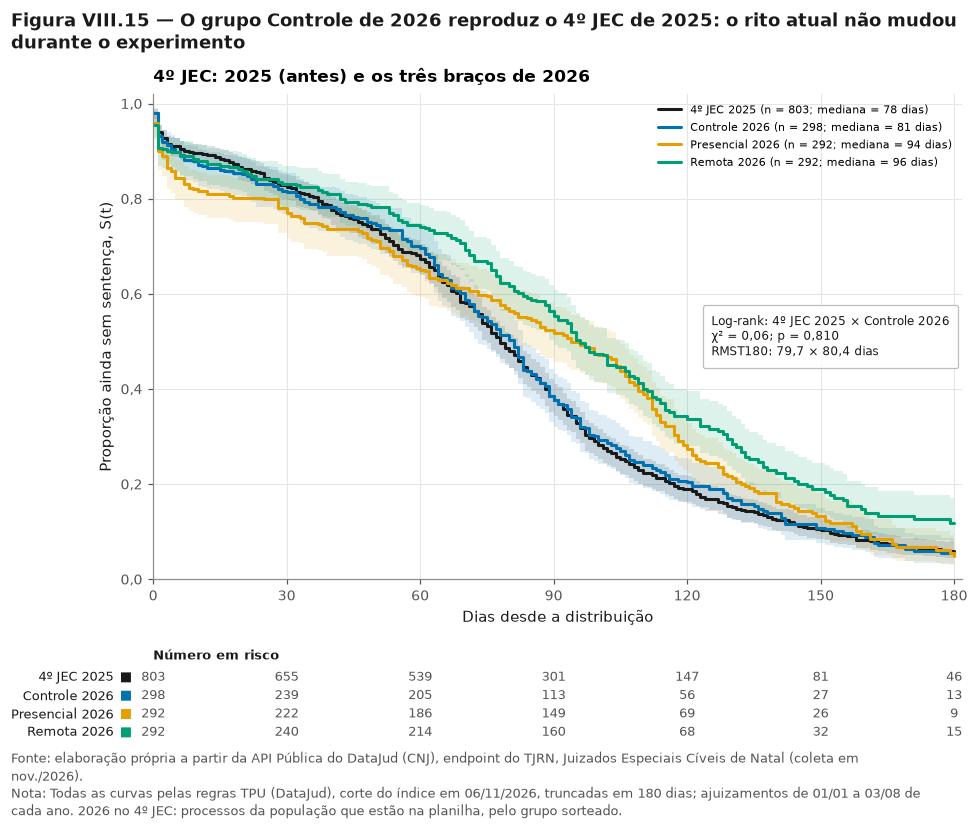

Série,n,RMST180 (dias),Sentenciados até 90 dias
4º JEC 2025,803,"79,7","62,3%"
Controle 2026,298,"80,4","62,4%"
Presencial 2026,292,"85,2","48,3%"
Remota 2026,292,"95,0","44,8%"


In [51]:
if DJ_POP4_OK:
    TRUNC = 180

    def dj_trunc(T, E, tau=TRUNC):
        T = np.asarray(T, float); E = np.asarray(E, int)
        return np.minimum(T, tau), np.where(T > tau, 0, E)

    _grp = dict(zip(dj['numero'], dj['grupo'].astype(str)))
    q25 = pop[pop['quarto'] & pop['janela'] & (pop['ano'] == 2025)]
    q26 = pop[pop['quarto'] & pop['janela'] & (pop['ano'] == 2026)].copy()
    q26['grupo'] = q26['numero'].map(_grp)
    q26s = q26[q26['grupo'].notna()]
    comp4 = pd.concat([pd.DataFrame({'T': q25['T'], 'E': q25['E'], 'serie': '4º JEC 2025'}),
                       pd.DataFrame({'T': q26s['T'], 'E': q26s['E'], 'serie': q26s['grupo'] + ' 2026'})], ignore_index=True)
    comp4['T'], comp4['E'] = dj_trunc(comp4['T'], comp4['E'])
    cores4 = {'4º JEC 2025': TINTA, 'Controle 2026': CORES_GRUPO['Controle'], 'Presencial 2026': CORES_GRUPO['Presencial'],
              'Remota 2026': CORES_GRUPO['Remota'], 'Outros 13 JECs 2025': TINTA, 'Outros 13 JECs 2026': CINZA}
    dois = DJ_POP_OK
    fig, axs = plt.subplots(1, 2 if dois else 1, figsize=(14, 6.4) if dois else (9, 6.4))
    axs = np.atleast_1d(axs)
    ORD4 = [k for k in ['4º JEC 2025', 'Controle 2026', 'Presencial 2026', 'Remota 2026'] if (comp4.serie == k).any()]
    plot_km(axs[0], comp4, tempo='T', evento='E', grupo='serie', ordem=ORD4,
            cores=cores4, passo=30, tmax=TRUNC, ic=True, censuras=False)
    a_ = comp4[comp4.serie.isin(['4º JEC 2025', 'Controle 2026'])]
    lr4 = logrank_test(a_.loc[a_.serie == '4º JEC 2025', 'T'], a_.loc[a_.serie == 'Controle 2026', 'T'],
                       a_.loc[a_.serie == '4º JEC 2025', 'E'], a_.loc[a_.serie == 'Controle 2026', 'E'])
    rm = {s_: dj_rmst(g_['T'].values.astype(int), g_['E'].values, TRUNC) for s_, g_ in comp4.groupby('serie')}
    anotar_teste(axs[0], texto_teste('Log-rank: 4º JEC 2025 × Controle 2026', f'χ² = {fmt_br(lr4.test_statistic, 2)}', lr4.p_value,
                                     f"RMST180: {fmt_br(rm['4º JEC 2025'], 1)} × {fmt_br(rm['Controle 2026'], 1)} dias"), loc='center right', tamanho=8)
    axs[0].set_title('4º JEC: 2025 (antes) e os três braços de 2026')
    tab_ad = pd.DataFrame([{'Série': k, 'n': int((comp4.serie == k).sum()), 'RMST180 (dias)': rm[k],
                            'Sentenciados até 90 dias': 1 - dj_km_grade(comp4.loc[comp4.serie == k, 'T'].values.astype(int),
                                                                         comp4.loc[comp4.serie == k, 'E'].values, 90)[90]}
                           for k in ORD4])
    if dois:
        o25 = pop[~pop['quarto'] & pop['janela'] & (pop['ano'] == 2025)]
        o26 = pop[~pop['quarto'] & pop['janela'] & (pop['ano'] == 2026)]
        compo = pd.concat([pd.DataFrame({'T': o25['T'], 'E': o25['E'], 'serie': 'Outros 13 JECs 2025'}),
                           pd.DataFrame({'T': o26['T'], 'E': o26['E'], 'serie': 'Outros 13 JECs 2026'})], ignore_index=True)
        compo['T'], compo['E'] = dj_trunc(compo['T'], compo['E'])
        plot_km(axs[1], compo, tempo='T', evento='E', grupo='serie', ordem=['Outros 13 JECs 2025', 'Outros 13 JECs 2026'], cores=cores4,
                passo=30, tmax=TRUNC, ic=True, censuras=False)
        lro = logrank_test(compo.loc[compo.serie.str.endswith('2025'), 'T'], compo.loc[compo.serie.str.endswith('2026'), 'T'],
                           compo.loc[compo.serie.str.endswith('2025'), 'E'], compo.loc[compo.serie.str.endswith('2026'), 'E'])
        rmo = {s_: dj_rmst(g_['T'].values.astype(int), g_['E'].values, TRUNC) for s_, g_ in compo.groupby('serie')}
        anotar_teste(axs[1], texto_teste('Log-rank: 2025 × 2026', f'χ² = {fmt_br(lro.test_statistic, 2)}', lro.p_value,
                                         f"RMST180: {fmt_br(rmo['Outros 13 JECs 2025'], 1)} × {fmt_br(rmo['Outros 13 JECs 2026'], 1)} dias"),
                     loc='center right', tamanho=8)
        axs[1].set_title('Outros 13 JECs cíveis de Natal: 2025 e 2026')
        tab_ad = pd.concat([tab_ad, pd.DataFrame([{'Série': k, 'n': int((compo.serie == k).sum()), 'RMST180 (dias)': rmo[k],
                                                   'Sentenciados até 90 dias': 1 - dj_km_grade(compo.loc[compo.serie == k, 'T'].values.astype(int),
                                                                                               compo.loc[compo.serie == k, 'E'].values, 90)[90]}
                                                  for k in ['Outros 13 JECs 2025', 'Outros 13 JECs 2026']])], ignore_index=True)
    for ax in axs:
        ax.legend(loc='upper right', fontsize=7.5)
    figura(fig, 'dj_antes_durante', ('O grupo Controle de 2026 reproduz o 4º JEC de 2025: o rito atual não mudou durante o experimento'
                                  if lr4.p_value >= 0.05 else 'O grupo Controle de 2026 difere do 4º JEC de 2025: a unidade mudou durante o experimento'),
       secao='8.6.5', fonte=FONTE_DJ_POP,
           nota=f'Todas as curvas pelas regras TPU (DataJud), corte do índice em {DJ_CORTE_POP:%d/%m/%Y}, truncadas em 180 dias; '
                'ajuizamentos de 01/01 a 03/08 de cada ano. 2026 no 4º JEC: processos da população que estão na planilha, pelo grupo sorteado.')
    tabela(tab_ad, 'dj_antes_durante', 'Antes × durante: RMST até 180 dias e proporção sentenciada até 90 dias (regras TPU)',
           secao='8.6.5', fonte=FONTE_DJ_POP, formatos={'Sentenciados até 90 dias': 'pct', 'RMST180 (dias)': 1, 'n': 'int'})

**Leitura.** Medido pelas mesmas regras, com o mesmo corte e o mesmo horizonte, o **grupo Controle de 2026 é indistinguível do 4º JEC de 2025**: medianas de 81 e 78 dias, RMST até 180 dias de 80,4 e 79,7 dias, 62,4% e 62,3% sentenciados até 90 dias (log-rank χ² = 0,06; p = 0,81). Já os dois braços com AC obrigatória ficam abaixo do patamar histórico da unidade: 48,3% (presencial) e 44,8% (remota) sentenciados até 90 dias, e RMST180 de 85,2 e 95,0 dias.

Três consequências:

1. **O Controle representa de fato o "rito atual"**. Uma ameaça discutida na seção 6.9 era que o experimento, ao ocupar a pauta com audiências obrigatórias e mobilizar cartório e juiz, mudasse a unidade inteira, e que o Controle de 2026 deixasse de representar o rito anterior (contaminação, efeito Hawthorne sobre o juiz-pesquisador). Os dados não mostram isso: o Controle de 2026 tramitou no mesmo ritmo do 4º JEC de 2025.
2. **O atraso dos grupos com AC é um efeito do rito sobre um patamar estável**, e não a combinação de um Controle "acelerado" com grupos tratados normais.
3. **A unidade como um todo ficou mais lenta em 2026**, porque dois terços dos processos foram sorteados para a AC obrigatória: é o custo de escala da política, que uma adoção geral transferiria a toda a unidade. É também o que o DiD agregado de 8.6.2 capta (queda do mérito no 4º JEC maior que em qualquer outro juizado).

**Limites.** É uma comparação antes × depois numa única unidade. Os dados agregados de 8.6.2 indicam que, nos outros 13 JECs, a proporção sentenciada também caiu de 2025 para 2026 (menos tempo de observação para os processos de 2026), mas sem os tempos dos outros juizados não é possível excluir, com horizonte fixo, uma mudança comum à capital. E é observacional: a semelhança Controle 2026 × 4º JEC 2025 é evidência a favor da validade do grupo de comparação, não uma prova.

### 8.6.6 O 4º JEC é típico entre os 14? (questão 2.10)

Em 2025, antes do experimento, as 14 unidades recebiam processos sorteados pelo mesmo distribuidor; diferenças entre elas refletem juiz, cartório e pauta. O gráfico ordena os juizados pelo P90 de 2025 e mostra o de 2026 ao lado. **Teste:** qui-quadrado de homogeneidade da proporção sentenciada até 90 dias entre as 14 unidades em 2025 (todas as coortes de 2025 têm os 90 dias completos, de modo que a proporção simples não sofre censura, a não ser pela saída da unidade).

In [52]:
if DJ_POP_OK:
    p90 = wide['P90'].sort_values(2025)
    fig, ax = plt.subplots(figsize=(12, 5.2))
    xs = np.arange(len(p90))
    ax.bar(xs - 0.2, 100 * p90[2025], width=0.4, color=[COR_4JEC if u == '4º' else COR_OUTROS for u in p90.index], label='2025')
    ax.bar(xs + 0.2, 100 * p90[2026], width=0.4, color=[COR_4JEC if u == '4º' else COR_OUTROS for u in p90.index], alpha=0.45,
           hatch='//', edgecolor='white', label='2026')
    ax.set_xticks(xs, [f'{u} JEC' for u in p90.index], fontsize=8.5)
    ax.set_ylabel('Sentenciados até 90 dias (%)')
    ax.set_title('P90 por juizado: barras cheias = 2025; hachuradas = 2026; preto = 4º JEC')
    ax.grid(axis='x', visible=False)
    j25 = jan[jan['ano'] == 2025]
    ct = pd.crosstab(j25['jec'], (j25['E'] == 1) & (j25['T'] <= H_DJ))
    chi_h, p_h, gl_h, _ = stats.chi2_contingency(ct.values)
    pos4 = int((p90[2025] > p90.loc['4º', 2025]).sum()) + 1
    anotar_teste(ax, texto_teste('Qui-quadrado de homogeneidade (2025)', f'χ² = {fmt_br(chi_h, 1)} ({gl_h} gl)', p_h,
                                 f'4º JEC: {pos4}º maior P90 de 14 em 2025'), loc='upper left')
    legenda_abaixo(ax, ncol=2)
    figura(fig, 'dj_tipicidade', 'O 4º JEC entre os 14 Juizados Cíveis de Natal, antes e durante o experimento', secao='8.6.6',
           fonte=FONTE_DJ_POP, nota='P90 = 1 − Ŝ(90) de Kaplan-Meier (saída = censura). Ajuizamentos de 01/01 a 03/08 de cada ano.')
    tip = (up.assign(**{c: up[c] * DJ_DESF[c][2] for c in DJ_DESF})
           .pivot(index='jec', columns='ano', values=['n'] + list(DJ_DESF)))
    tip.columns = [f'{a} {b}' for a, b in tip.columns]
    tabela(tip.loc[p90.index].rename_axis('Juizado'), 'dj_tipicidade', 'Desfechos com horizonte de 90 dias por juizado, 2025 e 2026',
           secao='8.6.6', fonte=FONTE_DJ_POP, casas=1, formatos={'n 2025': 'int', 'n 2026': 'int'},
           destaque=lambda df: df.index == '4º', nota='P90, SM90 e HOM90 em %; RMST90 em dias.')

*Não executada nesta versão (ver 8.6.1): a tipicidade com horizonte fixo exige os tempos dos outros 13 JECs. A comparação possível, pelo perfil de desfechos em 2025, está em 8.6.2: o 4º JEC já era, antes do experimento, o 2º juizado com mais extinções sem mérito e menos julgamentos de mérito.*

### 8.6.7 Os "106,8 dias" do período anterior

O projeto do experimento cita, como duração média do 4º JEC antes da intervenção, **106,8 dias** (painel GPS-Jus, consulta de 17/12/2025), e a comparação do pesquisador opõe esse número à média de ~75 dias dos sentenciados de 2026. O GPS-Jus mede a duração média **dos processos que receberam sentença em um período**, olhando para trás (do ajuizamento à sentença). A célula reproduz essa medida com o DataJud: 4º JEC, processos com o 1º julgamento entre 17/12/2024 e 17/12/2025 (12 meses), média de dias desde a entrada; e a **mesma medida** para os sentenciados de 2026 até 07/10/2026. Essa média "dos sentenciados" depende de quanto tempo a janela olha para trás: numa janela que começa com o experimento, só entram processos novos, e a média cai por construção (seção 2.5, artefato da entrada escalonada). Por isso a comparação justa é a de horizonte fixo (8.6.4–8.6.5).

Medida,Média (dias),Mediana (dias),n
"GPS-Jus (citado no projeto, 17/12/2025)","106,8",–,–
DataJud: sentenciados de 17/12/2024 a 17/12/2025,"93,0","82,0",1.390
DataJud: sentenciados de 01/01 a 07/10/2026,"93,5","86,0",948
Planilha: sentenciados até 07/10/2026 (média ingênua),"71,0","73,5",708


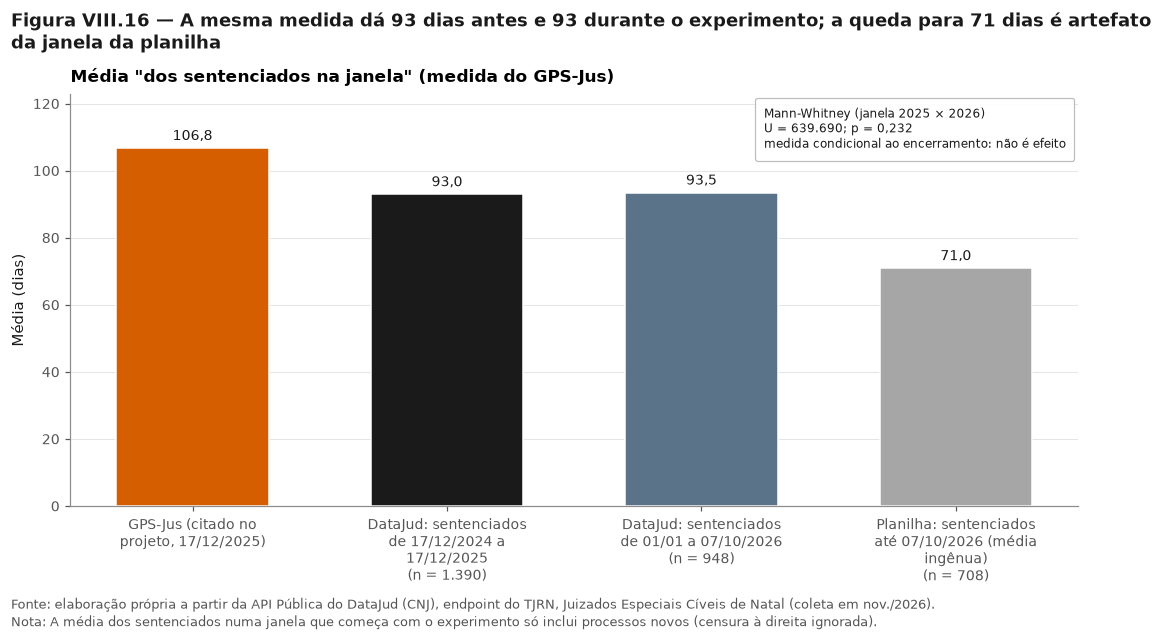

In [53]:
if DJ_POP4_OK:
    tem_2024 = DJ_4JEC_2024_2025
    q4 = pop[pop['quarto'] & (pop['E'] == 1)].copy()
    q4['dt_s'] = q4['entrada'].dt.normalize() + pd.to_timedelta(q4['T'], unit='D')
    jan1 = q4[(q4['dt_s'] > '2024-12-17') & (q4['dt_s'] <= '2025-12-17')]
    if not tem_2024:
        jan1 = jan1[jan1['ano'] >= 2025]          # 2024 incompleto não entra (subconjunto não aleatório)
    jan2 = q4[(q4['dt_s'] >= '2026-01-01') & (q4['dt_s'] <= DATA_CORTE)]
    sent_pl = dados[dados['evento'].astype(int) == 1]['tempo'].astype(float)
    g106 = pd.DataFrame([
        ['GPS-Jus (citado no projeto, 17/12/2025)', 106.8, np.nan, np.nan],
        ['DataJud: sentenciados de 17/12/2024 a 17/12/2025' + ('' if tem_2024 else ' (só ajuizados em 2025: limite inferior)'),
         jan1['T'].mean(), jan1['T'].median(), len(jan1)],
        ['DataJud: sentenciados de 01/01 a 07/10/2026', jan2['T'].mean(), jan2['T'].median(), len(jan2)],
        ['Planilha: sentenciados até 07/10/2026 (média ingênua)', sent_pl.mean(), sent_pl.median(), len(sent_pl)],
    ], columns=['Medida', 'Média (dias)', 'Mediana (dias)', 'n'])
    tabela(g106, 'dj_106', 'A "média anterior" de 106,8 dias e a mesma medida calculada no DataJud', secao='8.6.7', fonte=FONTE_DJ_POP,
           casas=1, formatos={'n': 'int'},
           nota='Média dos dias da entrada no 4º JEC ao 1º julgamento, entre os sentenciados na janela. '
                + ('Inclui ajuizamentos de 2024 e 2025; processos ajuizados antes de 2024 e sentenciados na 1ª janela não foram coletados.'
                   if tem_2024 else 'ATENÇÃO: a coleta de 2024 do 4º JEC não terminou (API sobrecarregada); a 1ª janela inclui só os ajuizados em 2025, '
                   'e a sua média é um limite inferior da medida do GPS-Jus.'))
    fig, ax = plt.subplots(figsize=(10, 5))
    _cats = [quebra(t, 22) + (f'\n(n = {fmt_int(n)})' if pd.notna(n) else '') for t, n in zip(g106['Medida'], g106['n'])]
    barras_verticais(ax, _cats, g106['Média (dias)'], cores=[DESTAQUE, TINTA, '#5B7389', CINZA], ylabel='Média (dias)', quebrar=40)
    ax.set_title('Média "dos sentenciados na janela" (medida do GPS-Jus)')
    u_ = stats.mannwhitneyu(jan1['T'], jan2['T'])
    anotar_teste(ax, texto_teste('Mann-Whitney (janela 2025 × 2026)', f'U = {fmt_br(u_.statistic, 0)}', u_.pvalue,
                                 'medida condicional ao encerramento: não é efeito'), loc='upper right', tamanho=8)
    figura(fig, 'dj_106', f"A mesma medida dá {fmt_br(jan1['T'].mean(), 0)} dias antes e {fmt_br(jan2['T'].mean(), 0)} durante o experimento; "
       f"a queda para {fmt_br(sent_pl.mean(), 0)} dias é artefato da janela da planilha",
           secao='8.6.7', fonte=FONTE_DJ_POP, nota='A média dos sentenciados numa janela que começa com o experimento só inclui '
           'processos novos (censura à direita ignorada).')

**Leitura.** A medida do GPS-Jus (duração média dos processos sentenciados nos 12 meses anteriores, do ajuizamento à sentença) foi recalculada com todos os processos do 4º JEC ajuizados a partir de 2024: **93,0 dias** (mediana de 82) para os sentenciados entre 17/12/2024 e 17/12/2025. Fica abaixo dos 106,8 dias citados no projeto, o que é esperado: os processos ajuizados **antes de 2024** e sentenciados naquela janela (os mais antigos e demorados) não foram coletados, e o painel do CNJ pode usar outra definição de evento (baixa, e não a 1ª sentença). Os 93 dias são, portanto, um limite inferior da medida citada.

O ponto central é a comparação feita pelo pesquisador (106,8 → ~75 dias). A **mesma medida**, calculada no DataJud para todos os processos do 4º JEC sentenciados de 01/01 a 07/10/2026, dá **93,5 dias**, praticamente igual à de 2025 (Mann-Whitney p = 0,23), e não os 71 dias da média ingênua da planilha. A diferença vem da janela: a planilha só contém processos distribuídos a partir de 01/01/2026, de modo que até 07/10 nenhum deles podia ter mais de 279 dias, e os ainda pendentes (os mais demorados) ficam fora da média. A "queda" é, portanto, **um artefato da janela de observação** (seção 2.5; E14, E30), e não uma aceleração da unidade; a comparação correta é a de horizonte fixo (8.6.5), que mostra o Controle de 2026 igual ao 4º JEC de 2025 e os grupos com AC mais lentos.

## 8.7 Síntese da Parte VIII

| Pergunta | Resposta | Seção |
|---|---|---|
| A planilha confere com o DataJud? | Sim. Vínculo de 98,7% (igual nos grupos); datas de distribuição e sentença coincidem em 99,9% e 97,6–99,1%; tipo de desfecho κ = 0,971, AC realizada κ = 0,983, acordo κ = 0,993. Divergências: acordo homologado depois da sentença registrado como desfecho (11) e atraso de alimentação perto de 07/10 (13 processos "ativos" já encerrados) | 8.3 |
| As 135 sentenças em fim de semana são erro? | Não: 98,5% estão no mesmo dia no DataJud; são assinaturas eletrônicas feitas no sábado ou no domingo, quase sempre de manhã | 8.3.3 |
| O seguimento curto distorcia o resultado? | Não; era conservador. Até 06/11/2026, 81 censurados foram sentenciados (mais 8 já sentenciados antes de 07/10); o Controle encerrou mais dos seus pendentes. HR da AC remota 0,81 → 0,76; ΔRMST180 10,7 → 14,0 dias; log-rank p = 0,023 → 0,001 | 8.4 |
| O estudo pode ser refeito só com movimentos? | Sim: κ = 0,97 para o evento, 97,9% dos tempos com diferença ≤ 1 dia, mesmos HR e ΔRMST; critérios pré-fixados atendidos | 8.5 |
| O experimento mudou a unidade? | O Controle não: Controle 2026 = 4º JEC 2025 (RMST180 80,4 × 79,7 dias; p = 0,81). A unidade como um todo, sim: os braços com AC ficaram mais lentos e, entre os 14 JECs, a queda da sentença de mérito de 2025 para 2026 foi a maior no 4º JEC (DiD −11,8 p.p.; permutação p = 0,071, o mínimo possível) | 8.6.2, 8.6.5 |
| O 4º JEC é típico entre os 14? | Não: já em 2025 era o 2º com mais extinções sem mérito (36% × 26%) e menos mérito (61% × 68%). Distribuição de entrada igual entre os 14 | 8.6.2 |
| Comparação com horizonte fixo × outros 13 JECs | Parcial: a API não permitiu coletar os processos dos outros 13 JECs; código retomável a partir do cache | 8.6.1, 8.6.3, 8.6.4, 8.6.6 |
| Os 106,8 dias | Limite inferior de 93 dias no DataJud (sem os ajuizados antes de 2024); a mesma medida em 2026 dá 93,5 dias: a queda para ~75 é artefato da janela da planilha | 8.6.7 |

**Em síntese**, o DataJud **valida** a planilha, **confirma e reforça** o achado principal (a AC obrigatória, sobretudo a remota, atrasa a sentença; com mais seguimento, o efeito cresce) e **afasta** duas ameaças levantadas nas Partes I e VI: as datas de fim de semana não são erro, e o grupo Controle não foi alterado pelo experimento. Mostra também que o 4º JEC é uma unidade atípica em Natal, o que limita a validade externa (questão 2.10). As comparações entre anos e entre unidades são observacionais (e a comparação com os outros 13 JECs ficou parcial por indisponibilidade da API); nenhuma delas muda o estatuto da análise principal, que continua sendo a comparação entre grupos sorteados (Parte IV).